In [270]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cbook as cbook
import matplotlib.cm as cm
from matplotlib.colorbar import ColorbarBase
from numpy.linalg import cholesky
from numpy.random import multivariate_normal
from scipy.optimize import curve_fit
from scipy.interpolate import UnivariateSpline

from scipy.integrate import quad, dblquad
from scipy.interpolate import interp1d
from scipy.integrate import cumulative_trapezoid
from scipy import interpolate
from scipy.special import kn  # Modified Bessel function of second kind

import os
import seaborn as sns
import pandas as pd

#Plot param
plt.rcParams['font.family'] = 'serif'
plt.rcParams['mathtext.fontset']='dejavuserif'
plt.rcParams["figure.figsize"] = [15,10]
plt.rcParams["font.size"] = 30

In [271]:
#units

MeV_to_fm_m1 = 1/197.3
GeV_to_fm_m1 = 5.068
MeV_to_GeV = 1e-3
hbarc = 197.3 # MeV fm
MeV4_to_GeV_fm3 = (1e-3) * (1 / hbarc**3)

## Reading in lattice data

In [272]:
data = pd.read_csv("cs2_WB.dat",sep=r"\s+",header=None)

#data extracted from graph up to ~400 MeV and taken as 1/3 at 700 MeV
data_extracted = pd.read_csv("./cs2_data_extrap/points_extracted",sep=",",header=None)

In [273]:
lattice_cs2 = data[[0,1,2]]
extracted_cs2 = data_extracted[[0,1]]

In [274]:
lattice_cs2.columns = ['T','cs2','error']
extracted_cs2.columns = ['T_extract', 'cs2_extract']

In [275]:
lattice_cs2.to_csv("data.dat", sep= ' ', index = False)
extracted_cs2.to_csv("data_extracted.dat", sep= ',', index = False)

extracted_cs2_interp = interp1d(extracted_cs2['T_extract'], extracted_cs2['cs2_extract'], kind='linear') 

## GPs

In [276]:
def cs2fromphi(element):
    return 1/(np.exp(element) +1)

def phifromsc2(element):
    return np.log(1/element - 1)

In [277]:
def kernel_func(x1,x2,sigma,l):
    return(sigma*np.exp(-(x1-x2)**2/(2*l**2)))

In [278]:
#temperature vectors with stepsize one
T_max = 900

T_stepOne = np.linspace(120,260,260-120+1)
T_stepOne_total = np.linspace(120,T_max,T_max-120+1)
T_stepOne_up = np.linspace(261,T_max,T_max-261+1)

#cs2 means from lattice and extracted data
GP_mean_lat_file = lattice_cs2.cs2
GP_mean_extract = extracted_cs2_interp(T_stepOne_up)

In [279]:
def generate_sample(l, sigma):
    mean_data = np.concatenate([GP_mean_lat_file, GP_mean_extract])
    k = []
    mean = [phifromsc2(el) for el in mean_data]
    for x1 in T_stepOne_total:
        k_row = []
        for x2 in T_stepOne_total:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_stepOne_total))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

<>:73: SyntaxWarning: invalid escape sequence '\s'
<>:73: SyntaxWarning: invalid escape sequence '\s'
/tmp/ipykernel_5441/1047663273.py:73: SyntaxWarning: invalid escape sequence '\s'
  plt.figtext(0.12, 0.9,  f'l = {l_plot1}, $\sigma$ = {sigma_plot1}', size=17)


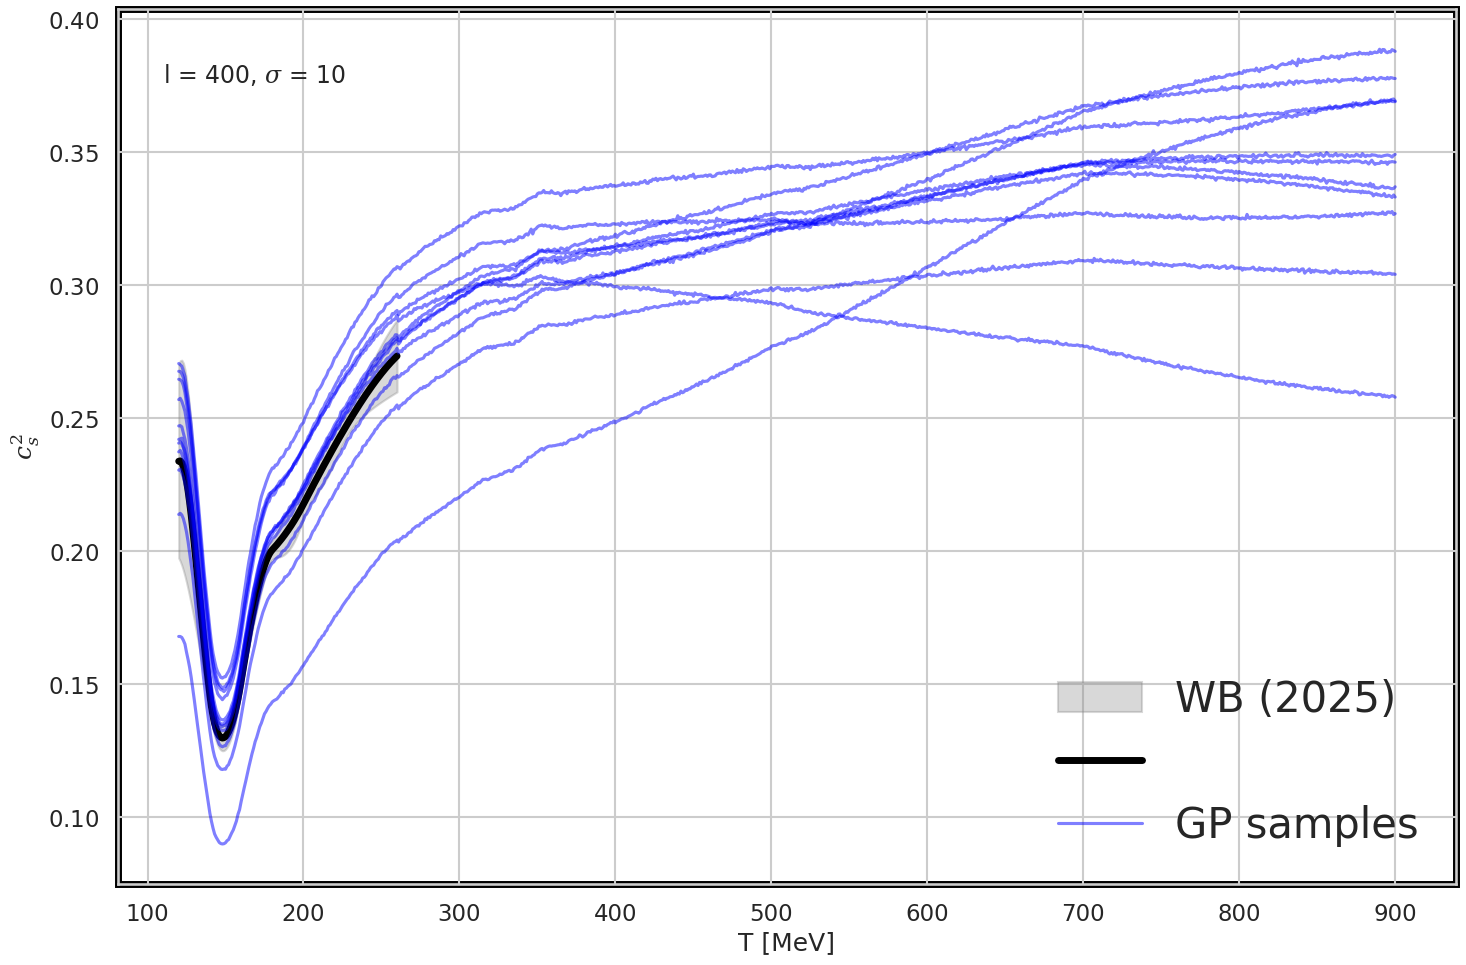

In [655]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

# Lattice error band
ax.fill_between(
    lattice_cs2['T'],
    lattice_cs2['cs2'] - lattice_cs2['error'],
    lattice_cs2['cs2'] + lattice_cs2['error'],
    alpha=0.3,
    color='gray',
    label='WB (2025)'
)

# Lattice mean line
sns.lineplot(
    data= lattice_cs2,
    x='T',
    y='cs2',
    ax=ax,
    color='black',
    linewidth=5,
    label=' '
)

for i in range(11):
    l_plot1 = 400
    sigma_plot1 = 10
    cs2_sample_plot1 = generate_sample(l_plot1, sigma_plot1)

    ax.plot(
        T_stepOne_total,
        cs2_sample_plot1,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)
plt.figtext(0.12, 0.9,  f'l = {l_plot1}, $\sigma$ = {sigma_plot1}', size=17)

plt.tight_layout()
plt.savefig('./images/cs2.png')
plt.show()



## HRG

In [281]:
#ranges in temperature with smaller stepsize

step_down = 0.001
step_up = 0.01

T_point01_up = np.linspace(120, T_max, int((T_max - 120) / step_up) + 1)
T_point001_down = np.round(np.arange(0, 119.9 + step_down, step_down), 10)
T_total = np.concatenate((T_point001_down, T_point01_up))

T_point001_110 = T_point001_down[0:int(110/step_down)]
T_concatenate_110to120 = np.concatenate([T_point001_110, T_point01_up])

#region in which we do the interpolation from HRG to values from sample
T_transitionRegion = T_total[1100:1200]

In [282]:
idx_30 = int(30/step_down)
idx_40 = int(40/step_down)
idx_100 = int(100/step_down)
idx_110 = int(110/step_down)
idx_120 = len(T_point001_down) 
idx_130 = int(len(T_point001_down) + 10/step_up)
idx_140 = int(len(T_point001_down) + 20/step_up)
idx_150 = int(len(T_point001_down) + 30/step_up)
idx_170 = int(len(T_point001_down) + 50/step_up)

len_transition = len(T_total[0:idx_120]) - len(T_total[0:idx_110])

In [283]:
print(len(T_total[0:idx_120]) - len(T_total[0:idx_110]))
print(T_total[idx_110 + 9902])

9902
120.0


In [284]:
print(len(T_point01_up))
print(len(T_point001_down))
print(len(T_total))
print(T_point001_down[110000])
print(T_point001_down[0] - T_point001_down[1])
print(T_point01_up[0] - T_point01_up[1])
print(int(110/step_down))

78001
119902
197903
110.0
-0.001
-0.010000000000005116
110000


In [285]:
file_path = "./pdg-urqmd_v3.3+.dat"

if not os.path.isfile(file_path):
    print("Unable to open file")
    exit(1)

m_bosons = []
m_fermions = []
g_b = []
g_f = []

with open(file_path, "r") as file:
    for line in file:
        
        #removes whitespace characters, including spaces, tabs, and newlines
        line = line.strip() 
        
        if not line:
            continue  # skip empty lines

        values = line.split()

        if values[1][0].isalpha():
            try:
                mass = float(values[2])
                f_or_b = int(values[5])
                g = float(values[4])
                mass_mev = mass * 1e3  #MeV

                if f_or_b == 1:
                    m_fermions.append(mass_mev)
                    g_f.append(g)
                elif f_or_b == 0:
                    m_bosons.append(mass_mev)
                    g_b.append(g)
            except ValueError:
                continue  
        elif values[1][0].isdigit():
            continue  


In [286]:
def bose_einstein(k, T, mass):
    x = np.sqrt(k**2 + mass**2)/T
    x = np.float128(x)
    if x > 700:
        return 0.0
    return 1.0/(np.expm1(x))

def fermi_dirac(k, T, mass):
    x = np.sqrt(k**2 + mass**2)/T
    x = np.float128(x)
    if x > 700:
        return 0.0
    return 1.0/(np.expm1(x) +1 + 1)

def pressure_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(6.0*(np.pi)**2))*(k**4)*fermi_dirac(k, T, mass)/(np.sqrt(k**2 + mass**2))
    elif eta == 0:
        return (g/(6.0*(np.pi)**2))*(k**4)*bose_einstein(k, T, mass)/(np.sqrt(k**2 + mass**2))
    else:
        raise ValueError("eta must be 0 or 1")

def energy_integrand(k, g, T, mass, eta):
    if eta == 1:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*fermi_dirac(k, T, mass)
    elif eta == 0:
        return (g/(2*(np.pi)**2))*(k**2)*(np.sqrt(k**2 + mass**2))*bose_einstein(k, T, mass)

In [287]:
T_sw = 150 #MeV

idx_Tsw = int(len(T_point001_down) + (T_sw-120)/step_up)
idx_Tsw_up = int((T_sw-120)/step_up)

def pressure_hrg(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(pressure_integrand, 0, 10000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(pressure_integrand, 0, 10000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

def energy_hrg(T, m_fermions, g_f, m_bosons, g_b):
    total = 0.0
    for m, g in zip(m_fermions, g_f):
        result, _ = quad(energy_integrand, 0, 10000, args=(g, T, m, 1), limit=200)
        total += result

    for m, g in zip(m_bosons, g_b):
        result, _ = quad(energy_integrand, 0, 10000, args=(g, T, m, 0), limit=200)
        total += result

    return total  # MeV^4

P_sw = pressure_hrg(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
e_sw = energy_hrg(T_sw, m_fermions, g_f, m_bosons, g_b) #MeV^4
s_sw =  (P_sw + e_sw)/T_sw #MeV^3

In [288]:
print(P_sw*MeV4_to_GeV_fm3)
print(e_sw*MeV4_to_GeV_fm3)
print(s_sw*(1/hbarc**3))
print(s_sw)

0.05254009465837943
0.2533134803289631
2.03902383324895
15660425.500159467


## Thermodynamics from sample

In [289]:
#every time you tun this cell it changes all other results from below

cs2_sample_list = generate_sample(10, 15) 

cs2_interp = interp1d(T_stepOne_total, cs2_sample_list)

In [290]:
def s_integrand(T, cs2_interp): 
    return 1 / (T * cs2_interp)

def entropy_up(s_sw, T_sw, cs2_interp, T_up):

    integrand = s_integrand(T_up, cs2_interp)
    integral = cumulative_trapezoid(integrand, T_up, initial=0)

    Int_at_Tsw = np.interp(T_sw, T_up, integral)

    #subtracts Int_at_Tsw from the integral, s(T_sw) = s_sw
    integral -= Int_at_Tsw

    s_up_vec = s_sw * np.exp(integral)
    s_interp = interp1d(T_up, s_up_vec)

    return s_interp

s_up_interp = entropy_up(s_sw, T_sw, cs2_interp(T_point01_up), T_point01_up)

In [291]:
#old integration method for comparison
""" 
def entropy_up_old(s_sw, T_sw, cs2_interp, T_up):
    s_up = []
        
    for T in T_up:
        if T < T_sw:
            integral, _ = quad(s_integrand, T, T_sw, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=1000)
            s = s_sw * np.exp(-integral)
        elif T > T_sw:
            integral, _ = quad(s_integrand, T_sw, T, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=1000)
            s = s_sw * np.exp(integral)
        else:
            s = s_sw
        s_up.append(s)
    return s_up

s_up_old = entropy_up_old(s_sw, T_sw, cs2_interp, T_pointZeroOne_up) """

' \ndef entropy_up_old(s_sw, T_sw, cs2_interp, T_up):\n    s_up = []\n\n    for T in T_up:\n        if T < T_sw:\n            integral, _ = quad(s_integrand, T, T_sw, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=1000)\n            s = s_sw * np.exp(-integral)\n        elif T > T_sw:\n            integral, _ = quad(s_integrand, T_sw, T, args=(cs2_interp,), epsabs=1e-3, epsrel=1e-3, limit=1000)\n            s = s_sw * np.exp(integral)\n        else:\n            s = s_sw\n        s_up.append(s)\n    return s_up\n\ns_up_old = entropy_up_old(s_sw, T_sw, cs2_interp, T_pointZeroOne_up) '

In [292]:
plt.figure(figsize=(8, 5))

plt.plot(T_point01_up[54000:56000], s_up_old[54000:56000],
         '-', linewidth=1.5, color='blue', label='Old $s(T)$')

plt.plot(T_point01_up[54000:56000],s_up_interp(T_point01_up[54000:56000]),
         '--', linewidth=1.5, color='red', label='Fixed $s(T)$')

plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/integral_comparison.png')
plt.show()


NameError: name 's_up_old' is not defined

<Figure size 800x500 with 0 Axes>

/tmp/ipykernel_5441/174271304.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


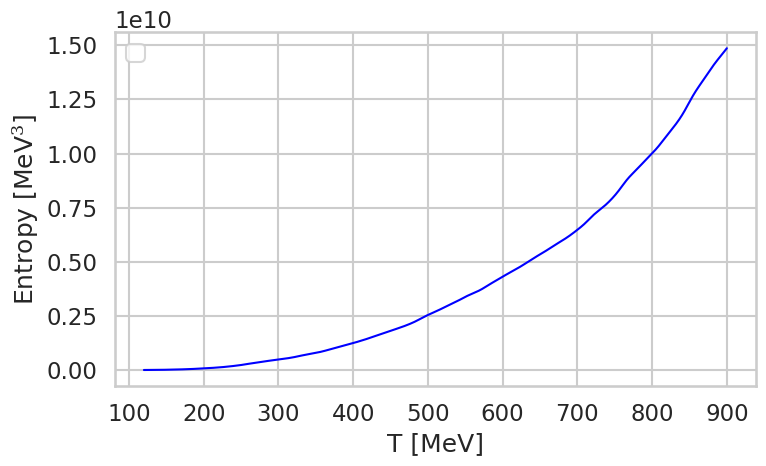

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(T_point01_up, s_up_interp(T_point01_up),
         '-', linewidth=1.5, color='blue', label = None)

plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/integral_comparison.png')
plt.show() 

In [ ]:
#pressure old integration method for comparison

def P_integrand(T, s_interp):
    return s_interp(T)

def pressure_up_old(P_sw, T_sw, T_vec, s_interp):
    pressure = []
    for T in T_vec:
        if T < T_sw:
            integral, _ = quad(P_integrand, T, T_sw, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw - integral
        elif T > T_sw:
            integral, _ = quad(P_integrand, T_sw, T, args=(s_interp,), epsabs=1e-3, epsrel=1e-3, limit=600)
            p = P_sw + integral
        else:
            p = P_sw
        pressure.append(p)
    return pressure

P_up_vec_old = pressure_up_old(P_sw, T_sw, T_point01_up, s_up_interp)

In [ ]:
def pressure_up(P_sw, T_sw, T_vec, s_interp):
    T_vec = np.asarray(T_vec)

    integrand = s_interp(T_vec)
    integral = cumulative_trapezoid(integrand, T_vec, initial=0)

    # find switch index
    i_sw = np.argmin(np.abs(T_vec - T_sw))

    # shift so that P(T_sw) = P_sw
    pressure = P_sw + integral - integral[i_sw]

    return pressure

P_up_vec = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp)
P_up_interp = interp1d(T_point01_up, P_up_vec)

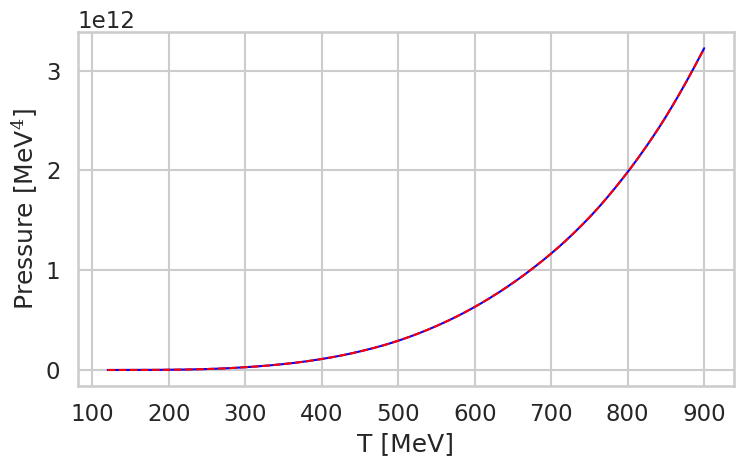

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(T_point01_up, P_up_vec,
         '-', linewidth=1.5, color='blue', label=None)
plt.plot(T_point01_up, P_up_vec_old,
         '--', linewidth=1.5, color='red', label='Old $P(T)$')

plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/integral_comparison.png')
plt.show()

In [ ]:
#energy upwards

def energy_up(s, P, T_vec):
    energy_vec = []
    for T in T_vec:
        energy_vec.append(s(T)*T - P(T))
    return energy_vec

e_up_vec = energy_up(s_up_interp, P_up_interp, T_point01_up)

/tmp/ipykernel_5441/3204410421.py:8: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


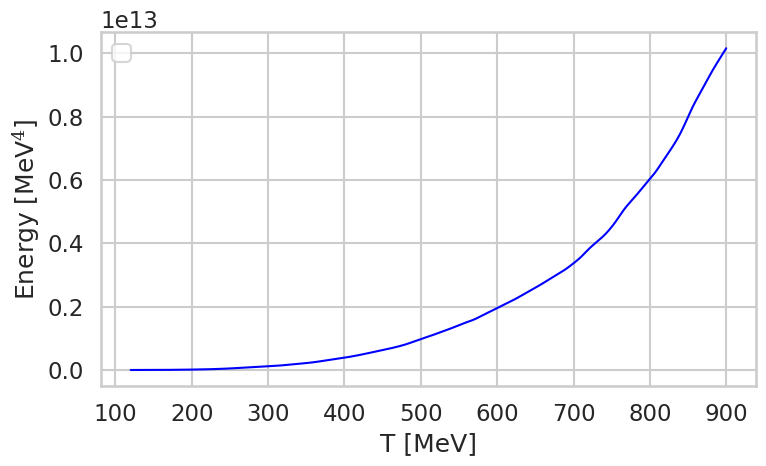

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(T_point01_up, e_up_vec,
         '-', linewidth=1.5, color='blue', label=None)

plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/integral_comparison.png')
plt.show()

## Downwards extrap

### Using a power law

In [ ]:
#s_down

def s_extrap_pwr(T, T_up, s_up_interp, P_up_interp):
    T0 = T_up[0]
    s0 = s_up_interp(120)
    p0 = P_up_interp(120)

    n = (T0*s0/p0) - 1
    a_s = s0 / T0**n
    return a_s * T**n

#vector of entropy for the whole range
s_total_pwr =  np.concatenate([s_extrap_pwr(T_point001_down, T_point01_up, s_up_interp, P_up_interp), s_up_interp(T_point01_up)])

s_interp_pwr = interp1d(T_total, s_total_pwr, kind='cubic')

sT_vec_pwr = []
for T in T_total:
    sT_vec_pwr.append(s_interp_pwr(T)*T)

In [ ]:
#pressure downwards

def P_extrap_pwr(T, T_up, s_up_interp, P_up_interp):
    T0 = T_up[0]
    s0 = s_up_interp(120)
    p0 = P_up_interp(120)

    n = (T0*s0/p0) - 1
    a_s = s0 / T0**n
    return (a_s*T**(n+1))/(n+1) 

#vector of pressure for the whole range
P_total_pwr = np.concatenate([P_extrap_pwr(T_point001_down, T_point01_up, s_up_interp, P_up_interp), P_up_vec])

P_interp_pwr = interp1d(T_total, P_total_pwr)


In [ ]:
#energy downwards

e_extrap_pwr = []
for i, T in enumerate(T_point001_down):
    s = s_extrap_pwr(T, T_point01_up, s_up_interp, P_up_interp)             
    p = P_extrap_pwr(T, T_point01_up, s_up_interp, P_up_interp)             
    e = s * T - p             
    e_extrap_pwr.append(e)

#vector of energy for the whole range
e_total_pwr = np.concatenate([e_extrap_pwr, e_up_vec])

e_interp_pwr = interp1d(T_total, e_total_pwr)

In [ ]:
with open("./check_files/thermo_check_powerlaw.txt", "w") as f:
    for i, T in enumerate(T_total):
        s_value = s_interp_pwr(T)
        p_value = P_interp_pwr(T)
        e_value = e_interp_pwr(T)
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")


Discrepancy at T = 620.92 MeV: e + p = 2931790155929.561523, s*T = 2931790155929.560059, diff = 1.46e-03
Discrepancy at T = 622.02 MeV: e + p = 2950754480500.859375, s*T = 2950754480500.857910, diff = 1.46e-03
Discrepancy at T = 625.66 MeV: e + p = 3015118244974.790039, s*T = 3015118244974.788574, diff = 1.46e-03
Discrepancy at T = 629.53 MeV: e + p = 3086227811464.010742, s*T = 3086227811464.009277, diff = 1.46e-03
Discrepancy at T = 631.20 MeV: e + p = 3117731433063.044922, s*T = 3117731433063.043457, diff = 1.46e-03
Discrepancy at T = 636.69 MeV: e + p = 3223424822034.021484, s*T = 3223424822034.022949, diff = 1.46e-03
Discrepancy at T = 636.97 MeV: e + p = 3228840676040.472656, s*T = 3228840676040.474121, diff = 1.46e-03
Discrepancy at T = 636.98 MeV: e + p = 3229034035850.208008, s*T = 3229034035850.206543, diff = 1.46e-03
Discrepancy at T = 637.09 MeV: e + p = 3231160590985.766602, s*T = 3231160590985.765137, diff = 1.46e-03
Discrepancy at T = 638.27 MeV: e + p = 3253917602546.54

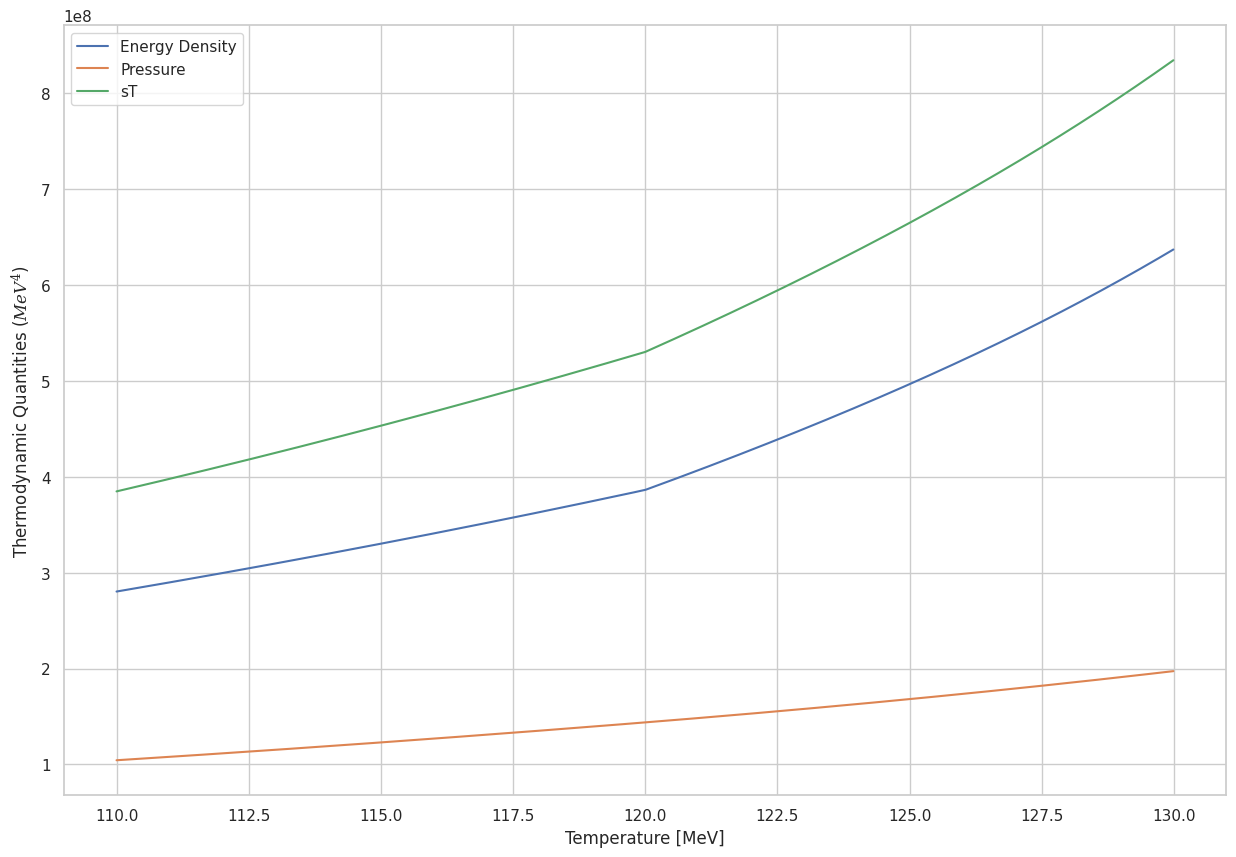

In [ ]:
#all thermo plots

df = pd.DataFrame({'T': T_total[idx_110:idx_130], 'Entropy': s_total_pwr[idx_110:idx_130], 'Energy': e_total_pwr[idx_110:idx_130], 
                   'Pressure': P_total_pwr[idx_110:idx_130], 'sT': sT_vec_pwr[idx_110:idx_130]})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='Energy', label='Energy Density')
sns.lineplot(data=df, x='T', y='Pressure', label='Pressure')
sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Thermodynamic Quantities ($ MeV^4$)')
plt.legend()
plt.savefig('./images/power_extrap.png')
plt.show()

In [ ]:
#cs2_vector

def cs2_extrap_pwr(T_down, T_up, s_up_interp, P_up_interp):
    cs2_down = []
    T0 = T_up[0]
    s0 = s_up_interp(120)
    p0 = P_up_interp(120)

    n = (T0*s0/p0) - 1

    for T in T_down:
        cs2_down.append(1/n)

    return cs2_down
    
#vector of cs2 for the whole range
#since cs2 isnt automatically continuous, we only extrapolate up to T = 110 MeV and do a linear interp in the transition region to 120 MeV    
cs2_total_pwr = np.concatenate([cs2_extrap_pwr(T_point001_110, T_point01_up, s_up_interp, P_up_interp), cs2_interp(T_point01_up)])

cs2_interp_pwr = interp1d(T_concatenate_110to120, cs2_total_pwr, kind='linear')

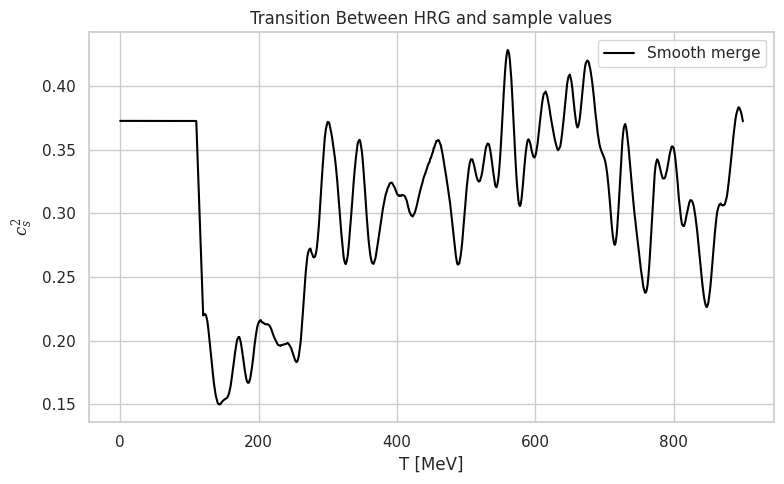

In [ ]:
#cs2 pwr plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total, cs2_interp_pwr(T_total) , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel(f'$c_s^2$')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
#plt.savefig('./images/cs2_transition_disc120.png')
plt.show()

In [ ]:
# sns.set(style="whitegrid", context="talk")

# fig1, axs1 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)
# fig2, axs2 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

# cmap = cm.get_cmap('tab10', 7)  
# colors = [cmap(i) for i in range(7)]

# for i in range(4):
#     s_plot = []
#     p_plot = []
#     e_plot = []
#     T_divide = T_total[500:]
    
#     cs2_sample_plot = generate_sample(10, 15)
#     cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

#     s_up_interp_plot = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)

#     P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp_plot)
#     P_up_interp_plot = interp1d(T_range_up, P_up_vec)

#     s_plot = np.concatenate([s_extrap_pwr(T_range_down, T_range_up, s_up_interp_plot, P_up_interp_plot), 
#                                   s_up_interp_plot(T_range_up)])

#     P_plot = np.concatenate([P_extrap_pwr(T_range_down, T_range_up, s_up_interp_plot, P_up_interp_plot), 
#                                P_up_interp_plot(T_range_up)])

#     e_plot = s_plot*T_total - P_plot

#     cs2_vec_plot = np.concatenate([cs2_extrap_pwr(T_range_down[0:1100], T_range_up, s_up_interp_plot, P_up_interp_plot), cs2_interp_plot(T_range_up)])

#     cs2_pwr_plot = interp1d(T_interp_cs2, cs2_vec_plot, kind='quadratic')

#     color = colors[i] 
#     axs1[0].plot(T_total, s_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
#     axs1[1].plot(T_total, P_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
#     axs1[2].plot(T_total, e_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
#     axs1[3].plot(T_total, cs2_pwr_plot(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

#     axs2[0].plot(T_divide, s_plot[500:] / T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
#     axs2[1].plot(T_divide, P_plot[500:] / T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
#     axs2[2].plot(T_divide, e_plot[500:] / T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
#     axs2[3].plot(T_divide, cs2_pwr_plot(T_total[500:]), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# # Labels and layout
# axs1[0].set_ylabel(r"$s(T) (1/fm^3)$")
# axs1[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
# axs1[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
# axs1[3].set_ylabel(r"$c_s^2(T)$")
# axs1[3].set_xlabel("Temperature T")

# axs2[0].set_ylabel(r"$s(T)/T^3 (1/fm^3)$")
# axs2[1].set_ylabel(r"$p(T)/T^4 (GeV/fm^3)$")
# axs2[2].set_ylabel(r"$e(T)/T^4 (GeV/fm^3)$")
# axs2[3].set_ylabel(r"$c_s^2(T)$")
# axs2[3].set_xlabel("Temperature T")

# for ax in axs1:
#     ax.legend()
#     ax.grid(True)

# for ax in axs2:
#     ax.legend()
#     ax.grid(True)

# plt.tight_layout()
# plt.savefig('./images/eos_pwr_change_hyper.png')
# plt.show()


### Using HRG and performing a weighted interpolation in a transition region

In [ ]:
def P_extrap_hrg(T, m_fermions, g_f, m_bosons, g_b):
    p_down = []
    for temp in T: 
        total = 0.0
        for m, g in zip(m_fermions, g_f):
            if temp <= 1.:
                total += 0.0
            else:
                result, _ = quad(pressure_integrand, 0, 10000, args=(g, temp, m, 1), limit=200)
                total += result

        for m, g in zip(m_bosons, g_b):
            if temp <=1:
                total += 0.0
            else:
                result, _ = quad(pressure_integrand, 0, 10000, args=(g, temp, m, 0), limit=200)
                total += result

        #print(temp, total)
        p_down.append(total)

    return p_down  # MeV^4

def e_extrap_hrg(T, m_fermions, g_f, m_bosons, g_b):
    e_down = []
    for temp in T: 
        total = 0.0     
        for m, g in zip(m_fermions, g_f):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(energy_integrand, 0, 10000, args=(g, temp+0.08, m, 1), limit=200)
                total += result

        for m, g in zip(m_bosons, g_b):
            if temp <= 1:
                total += 0.0
            else:
                result, _ = quad(energy_integrand, 0, 10000, args=(g, temp+0.08, m, 0), limit=200)
                total += result

        e_down.append(total)

    return e_down  # MeV^4

In [ ]:
P_hrg_total = P_extrap_hrg(T_total[:idx_Tsw], m_fermions, g_f, m_bosons, g_b)
e_hrg_total = e_extrap_hrg(T_total[:idx_Tsw], m_fermions, g_f, m_bosons, g_b)

In [ ]:
s_hrg_total =[]
for i in range(0, len(e_hrg_total)):
    s_hrg_total.append(np.where(T_total[i] != 0, (e_hrg_total[i] + P_hrg_total[i]) / T_total[i], 0.0))

/tmp/ipykernel_8113/3657949816.py:3: RuntimeWarning: invalid value encountered in scalar divide
  s_hrg_total.append(np.where(T_total[i] != 0, (e_hrg_total[i] + P_hrg_total[i]) / T_total[i], 0.0))


In [ ]:
#Save HRG to file

""" # Stack columns: P, e, s
data_hrg = np.column_stack((P_hrg_total, e_hrg_total, s_hrg_total))

# Save to file
np.savetxt(
    "hrg_thermo_table.txt",
    data_hrg,
    header="P_hrg  e_hrg  s_hrg",
    fmt="%.8e"
) """

' # Stack columns: T, P, e, s\ndata_hrg = np.column_stack((P_hrg_total, e_hrg_total, s_hrg_total))\n\n# Save to file\nnp.savetxt(\n    "hrg_thermo_table.txt",\n    data_hrg,\n    header="T  P_hrg  e_hrg  s_hrg",\n    fmt="%.8e"\n) '

In [ ]:
P_hrg_total = np.loadtxt("hrg_thermo_table.txt", usecols=0, skiprows=1)
e_hrg_total = np.loadtxt("hrg_thermo_table.txt", usecols=1, skiprows=1)
s_hrg_total = np.loadtxt("hrg_thermo_table.txt", usecols=2, skiprows=1)

In [ ]:
#HRG vectors low T

P_hrg_to110 = P_hrg_total[:idx_110]
e_hrg_to110 = e_hrg_total[:idx_110]

In [ ]:
s_hrg_to110 =[]
for i in range(0, len(e_hrg_to110)):
    s_hrg_to110.append(np.where(T_total[i] != 0, (e_hrg_to110[i] + P_hrg_to110[i]) / T_total[i], 0.0))

/tmp/ipykernel_5441/93237865.py:3: RuntimeWarning: invalid value encountered in scalar divide
  s_hrg_to110.append(np.where(T_total[i] != 0, (e_hrg_to110[i] + P_hrg_to110[i]) / T_total[i], 0.0))


In [ ]:
# weighted monotonic function old
# def weighted_monotonic(vec_down, vec_up):
#     vec_down = np.asarray(vec_down, dtype=float)
#     vec_up = np.asarray(vec_up, dtype=float)
#     # Default to the last value of vec_down if condition is never met
#     initial_val = vec_down[-1]
#     w_range = np.linspace(0, 1, 100)
#     vec_T_len = len(np.concatenate([vec_down, w_range, vec_up]))
#     for el, i in zip(vec_down, range(len(vec_down))):
#         if el > vec_up[0]:
#             #print(i-10) 
#             initial_val = vec_down[i-20] if i >= 20 else vec_down[0]
#             w_range = np.linspace(0, 1, vec_T_len - len(vec_up) - len(vec_down[0:i-20]))
#             vec_down = vec_down[0:i-20]
#             break 
#     weighted_vec = [weighted_interp(x, initial_val, vec_up[0]) for x in w_range]
#     #print(len(weighted_vec))
#     vec_total = np.concatenate([vec_down, weighted_vec, vec_up])
#     return vec_total 

In [ ]:
w_range = np.linspace(0, 1, 100)

def weighted_interp(x, val_down, val_up):
    return (1 - x) * val_down + x * val_up

def smoothstepFunction(T, T1, T2, val_down, val_up):
    x = (T-T1)/(T2-T1)
    #print(x)
    z = 6*x**5 - 15*x**4 + 10*x**3
    #print(z)
    return (1 - z) * val_down + z * val_up

In [ ]:
#interpolation w/ weights

def weightedExtrap_linear(vec_down, vec_up, n_transition=len_transition):
    vec_down = np.asarray(vec_down, dtype=float)
    vec_up   = np.asarray(vec_up, dtype=float)

    up_start = vec_up[0]

    # --- Find last index in vec_down that is STRICTLY below vec_up[0]
    valid_indices = np.where(vec_down < up_start)[0]

    if len(valid_indices) == 0:
        # Edge case: everything in vec_down is above vec_up[0], no valid index
        cut_idx = 0
    elif vec_down[-1] > up_start:
        cut_idx = valid_indices[-15]
        print(cut_idx)
    else:
        cut_idx = valid_indices[-1] + 1 # keep until this index
        print('last valid index is ' + str(valid_indices[-1]))

    vec_down_cut = vec_down[:cut_idx]

    # --- Define original total size (same as before cutting)
    N_total = len(vec_down) + n_transition + len(vec_up)

    # --- Define transition endpoints
    start_val = vec_down_cut[-1] if len(vec_down_cut) > 0 else up_start
    end_val   = up_start

    # --- Adjust transition size to preserve total length   
    n_transition = N_total - len(vec_down_cut) - len(vec_up)
    print('n_transition adjusted to ' + str(n_transition))

    # --- Build weights from 0 to 1
    diff = N_total - (len(vec_down_cut) + n_transition + len(vec_up))
    w_range = np.linspace(0, 1, n_transition, endpoint=False)
    
    print('len vec_down = ' + str(len(vec_down_cut)) + ' len weights = ' + str(len(w_range)) + 
        ' len vec_up = ' + str(len(vec_up)) + ' such that the difference should be zero = ' + str(diff))

    # --- Apply weights to interpolate values
    transition = np.array([
        weighted_interp(w, start_val, end_val) for w in w_range
    ])


    # --- Final concatenation
    vec_total = np.concatenate([
        vec_down_cut,
        transition,
        vec_up
    ])

    print('Final length check: ' + str(len(vec_total)) + ' should be ' + str(N_total))

    interpolation = interp1d(T_total, vec_total, kind='linear')

    return interpolation(T_total)


In [ ]:
#interpolation w/ weights, but not linear

def weightedExtrap_smooth(vec_down, vec_up, n_transition=len_transition):
    vec_down = np.asarray(vec_down, dtype=float)
    vec_up   = np.asarray(vec_up, dtype=float)

    up_start = vec_up[0]

    # --- Find last index in vec_down that is STRICTLY below vec_up[0]
    valid_indices = np.where(vec_down < up_start)[0]

    if len(valid_indices) == 0:
        # Edge case: everything in vec_down is above vec_up[0], no valid index
        cut_idx = 0
    elif vec_down[-1] > up_start:
        cut_idx = valid_indices[-15]
        print(cut_idx)
    else:
        cut_idx = valid_indices[-1] + 1 # keep until this index
        print('last valid index is ' + str(valid_indices[-1]))

    vec_down_cut = vec_down[:cut_idx]

    # --- Define original total size (same as before cutting)
    N_total = len(vec_down) + n_transition + len(vec_up)

    # --- Define transition endpoints
    start_val = vec_down_cut[-1] if len(vec_down_cut) > 0 else up_start
    end_val   = up_start

    # --- Adjust transition size to preserve total length   
    n_transition = N_total - len(vec_down_cut) - len(vec_up)
    print('n_transition adjusted to ' + str(n_transition))

    # --- Build weights from 0 to 1
    diff = N_total - (len(vec_down_cut) + n_transition + len(vec_up))
    w_range = np.linspace(0, 1, n_transition, endpoint=False)
    
    print('len vec_down = ' + str(len(vec_down_cut)) + ' len weights = ' + str(len(w_range)) + 
        ' len vec_up = ' + str(len(vec_up)) + ' such that the difference should be zero = ' + str(diff))

    # --- Apply weights to interpolate values
    transition = np.array([
        smoothstepFunction(T_total[i], T_total[cut_idx], T_point01_up[0], start_val, end_val)
        for i in range(cut_idx, cut_idx + n_transition)
    ])

    print( 'T1 = ' + str(T_total[cut_idx]) + ' T2 = ' + str(T_point01_up[0]))
    print('len transition = ' + str(len(transition)) + ' should be ' + str(n_transition))


    # --- Final concatenation
    vec_total = np.concatenate([
        vec_down_cut,
        transition,
        vec_up
    ])

    print('Final length check: ' + str(len(vec_total)) + ' should be ' + str(N_total))

    return vec_total

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


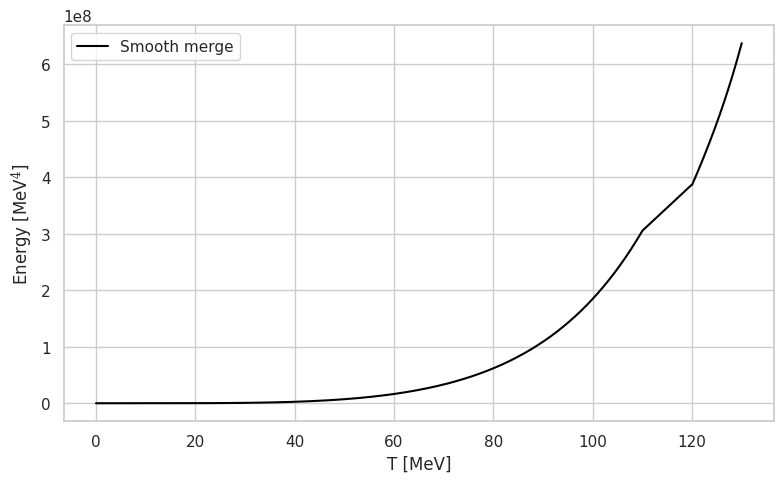

In [ ]:
# Energy transition plot

e_plot_w = weightedExtrap_linear(e_hrg_to110, e_up_vec)

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[:idx_130], e_plot_w[:idx_130] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/energy_transition_piongas.png')
plt.show()

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


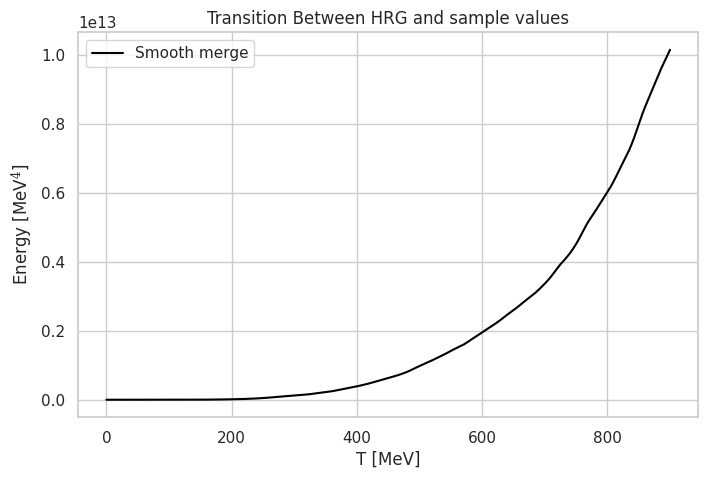

In [ ]:
#energy full range

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total, weightedExtrap_linear(e_hrg_to110, e_up_vec) , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
#plt.savefig('./images/hrg_e_transition.png')
plt.show()

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


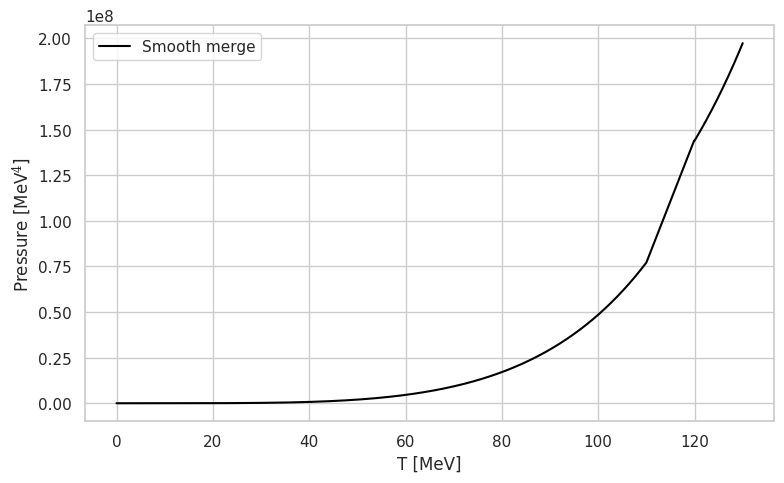

In [ ]:
# P transition plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

P_plot_w = weightedExtrap_linear(P_hrg_to110, P_up_vec)

plt.plot(T_total[:idx_130], P_plot_w[:idx_130] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/pressure_transition_piongas.png')
plt.show()

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


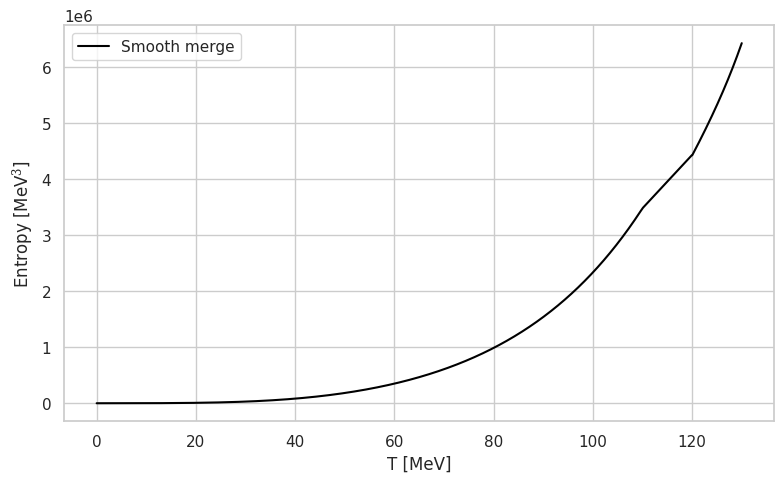

In [ ]:
#s transition plot

#s_plot = (weightedExtrap(e_hrg_vec_110, e_up_vec) +  weightedExtrap(P_hrg_vec_110, P_up_vec))/T_total
s_plot = weightedExtrap_linear(s_hrg_to110, s_up_interp(T_point01_up))

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[:idx_130], s_plot[:idx_130], '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/entropy_transition_piongas.png')
plt.show()

In [ ]:
#checking thermodynamic consistency

with open("./check_files/thermo_check_hrg.txt", "w") as f:
    p = weightedExtrap_linear(P_hrg_to110, P_up_vec)
    e = weightedExtrap_linear(e_hrg_to110, e_up_vec)
    s = np.where(T_total != 0, (p + e) / T_total, 0.0)

    for i, T in enumerate(T_total):
        s_value = s[i]
        p_value = p[i]
        e_value = e[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


/tmp/ipykernel_5441/1185814978.py:6: RuntimeWarning: invalid value encountered in divide
  s = np.where(T_total != 0, (p + e) / T_total, 0.0)


In [ ]:
def cs2_interp_w(cs2_interp, P, e, T):
    dP_dT_to120 = np.gradient(P[:idx_120], T[:idx_120])
    de_dT_to120 = np.gradient(e[:idx_120], T[:idx_120])

    with np.errstate(invalid='ignore', divide='ignore'): 
        cs2_to120 = dP_dT_to120 / de_dT_to120

    cs2_to120[np.isnan(cs2_to120)] = cs2_to120[~np.isnan(cs2_to120)][0]

    cs2_total_w = np.concatenate([cs2_to120, cs2_interp(T_point01_up)])

    cs2_interp_w = interp1d(T, cs2_total_w, kind='linear', fill_value="extrapolate")

    return cs2_interp_w(T)

/tmp/ipykernel_5441/582460685.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


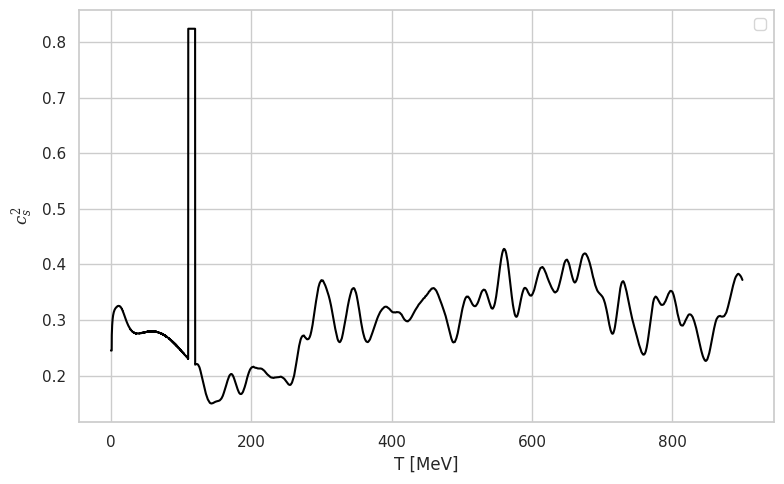

In [ ]:
#cs2 interp plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')
cs2_w_plot = cs2_interp_w(cs2_interp, P_plot_w, e_plot_w, T_total)

plt.plot(T_total, cs2_w_plot , '-', linewidth=1.5, color='black')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel(f'$c_s^2$')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/cs2_total_pionGas_w.png')
plt.show()

/tmp/ipykernel_5441/2402776292.py:6: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 7)
/tmp/ipykernel_5441/2402776292.py:32: RuntimeWarning: invalid value encountered in divide
  s_plot = (p_plot + e_plot)/T_total


last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check:

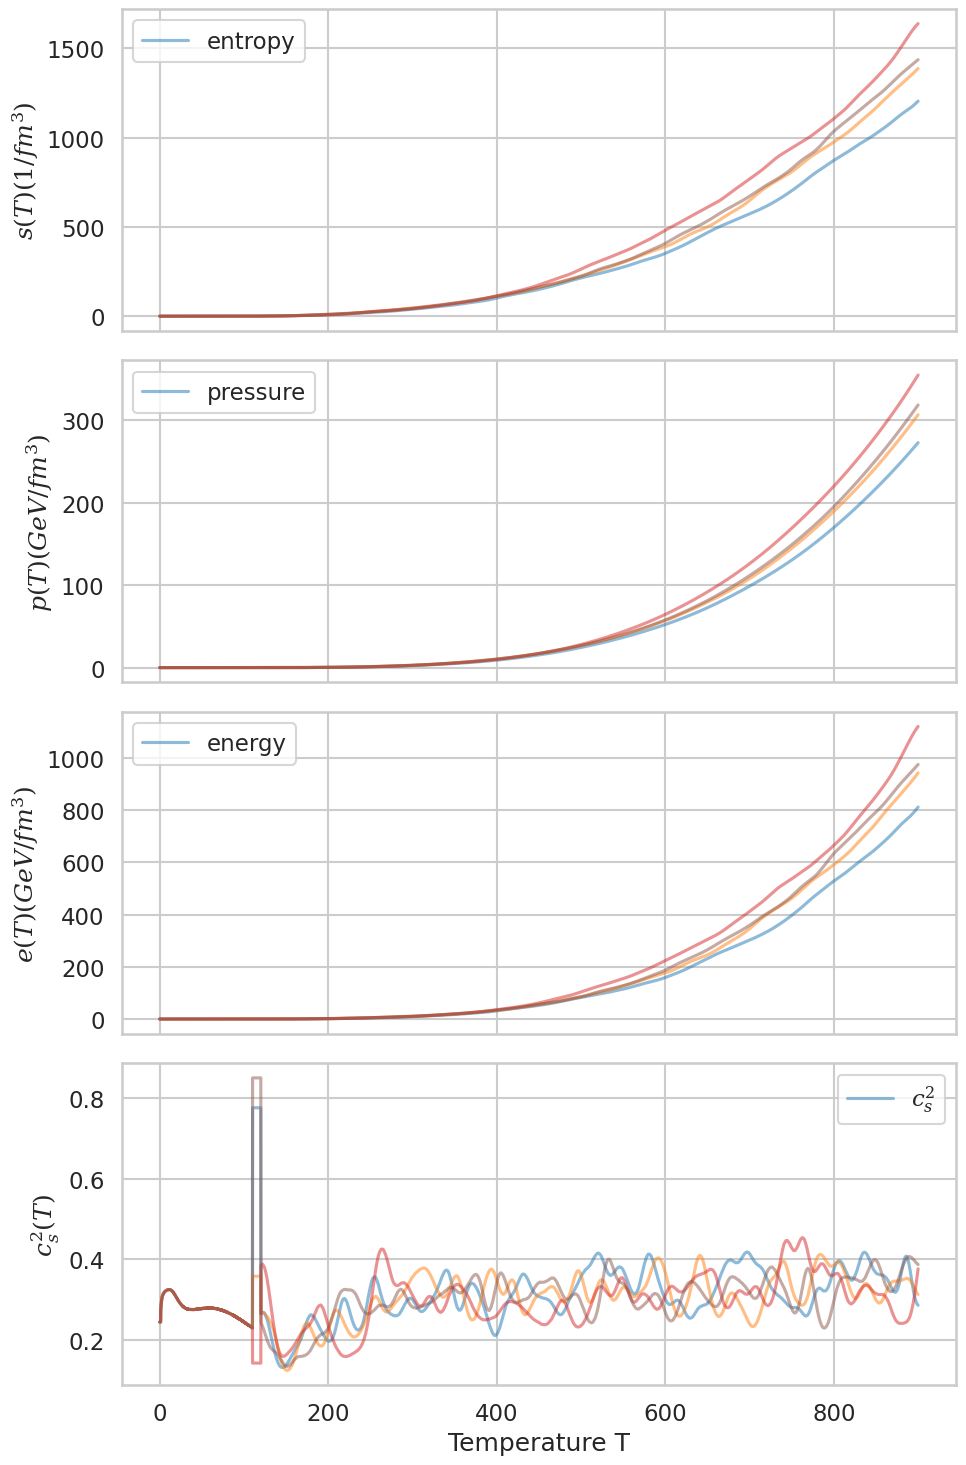

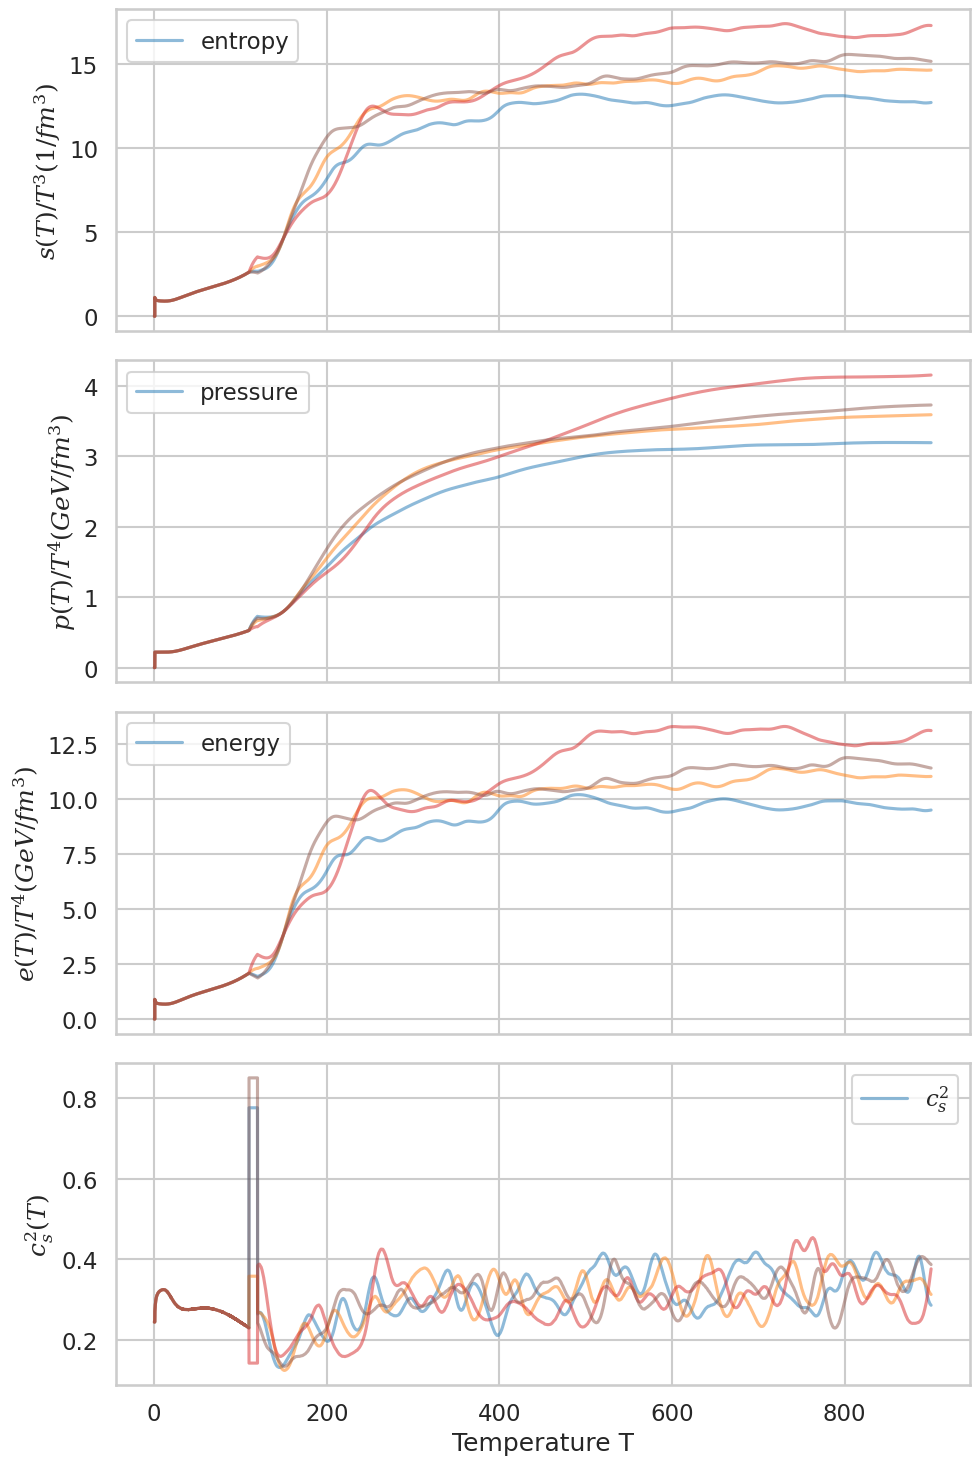

In [ ]:
sns.set(style="whitegrid", context="talk")

fig1, axs1 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)
fig2, axs2 = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
     while True:
        s_plot = []
        p_plot = []
        e_plot = []
        T_divide = T_total[500:]
    
        cs2_sample_plot = generate_sample(10, 15)
        cs2_interp_plot = interp1d(T_stepOne_total, cs2_sample_plot)

        s_up_interp_plot = entropy_up(s_sw, T_sw, cs2_interp_plot(T_point01_up), T_point01_up)

        P_up_vec = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp_plot)
        P_up_interp_plot = interp1d(T_point01_up, P_up_vec)

        e_up_vec = s_up_interp_plot(T_point01_up)*T_point01_up - P_up_interp_plot(T_point01_up)

        p_plot = weightedExtrap_linear(P_hrg_to110, P_up_vec)

        e_plot = weightedExtrap_linear(e_hrg_to110, e_up_vec)

        s_plot = (p_plot + e_plot)/T_total

        cs2_w_plot = cs2_interp_w(cs2_interp_plot, p_plot, e_plot, T_total)

        if np.any(cs2_w_plot[idx_110:idx_120] > 1.0001):
            print("Rejected sample: cs2 > 1 detected")
            continue   # regenerate

        if np.any(cs2_w_plot[idx_110:idx_120] < 0):
            print("Rejected sample: negative cs2")
            continue
        
        color = colors[i] 
        axs1[0].plot(T_total, s_plot*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
        axs1[1].plot(T_total, p_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
        axs1[2].plot(T_total, e_plot*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
        axs1[3].plot(T_total, cs2_w_plot, color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

        axs2[0].plot(T_divide, s_plot[500:] / T_divide**3, color=color, alpha=0.5, label='entropy' if i == 0 else None)
        axs2[1].plot(T_divide, p_plot[500:] / T_divide**4, color=color, alpha=0.5, label='pressure' if i == 0 else None)
        axs2[2].plot(T_divide, e_plot[500:] / T_divide**4, color=color, alpha=0.5, label='energy' if i == 0 else None)
        axs2[3].plot(T_divide, cs2_w_plot[500:], color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

        break  # exit while loop if sample is accepted
     
 # Labels and layout
axs1[0].set_ylabel(r"$s(T) (1/fm^3)$")
axs1[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
axs1[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
axs1[3].set_ylabel(r"$c_s^2(T)$")
axs1[3].set_xlabel("Temperature T")

axs2[0].set_ylabel(r"$s(T)/T^3 (1/fm^3)$")
axs2[1].set_ylabel(r"$p(T)/T^4 (GeV/fm^3)$")
axs2[2].set_ylabel(r"$e(T)/T^4 (GeV/fm^3)$")
axs2[3].set_ylabel(r"$c_s^2(T)$")
axs2[3].set_xlabel("Temperature T")

for ax in axs1:
     ax.legend()
     ax.grid(True)

for ax in axs2:
     ax.legend()
     ax.grid(True)

fig1.tight_layout()
fig1.savefig("./images/eos_weighted.png", dpi=300)

# Save second figure
fig2.tight_layout()
fig2.savefig("./images/eos_weighted_scaled.png", dpi=300)
plt.show()

### Taking it as a HRG up to switching temperature

In [ ]:
P_total_Tsw = np.concatenate([P_hrg_total, P_up_vec[idx_Tsw_up:]])
e_total_Tsw = np.concatenate([e_hrg_total, e_up_vec[idx_Tsw_up:]])
s_total_Tsw = np.concatenate([s_hrg_total, s_up_interp(T_point01_up[idx_Tsw_up:])])

In [ ]:
P_hrg_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), P_total_Tsw, kind='linear')
e_hrg_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), e_total_Tsw, kind='linear')
s_hrg_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), s_total_Tsw, kind='linear')

/tmp/ipykernel_5441/959690901.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


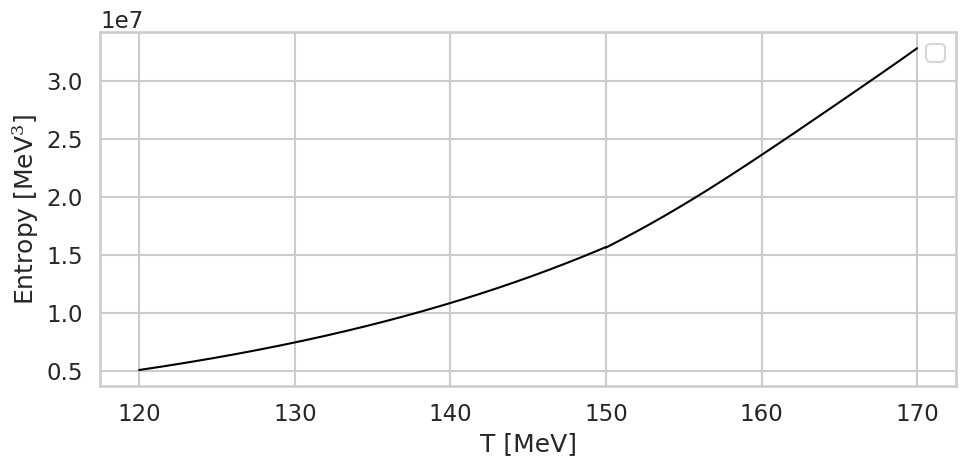

In [ ]:
#s plot
plt.figure(figsize=(10, 5))


plt.plot(T_total[idx_120:idx_170], s_hrg_interp(T_total[idx_120:idx_170]) , '-', linewidth=1.5, color='black')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)

plt.tight_layout()
plt.savefig('./images/s_hrg_150_transition.png')
plt.show()


/tmp/ipykernel_5441/1015736932.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


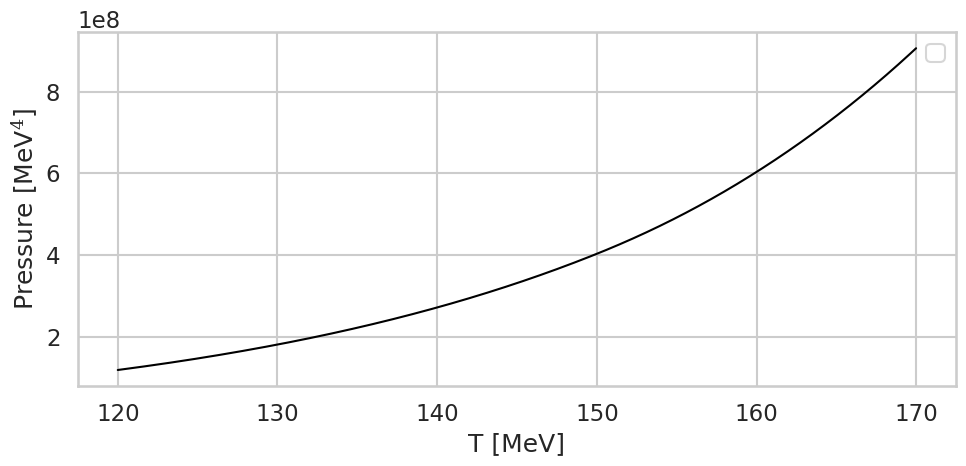

In [ ]:
#P plot
plt.figure(figsize=(10, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[idx_120:idx_170], P_hrg_interp(T_total[idx_120:idx_170]) , '-', linewidth=1.5, color='black')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)

plt.tight_layout()
plt.savefig('./images/P_hrg_150_transition.png')
plt.show()

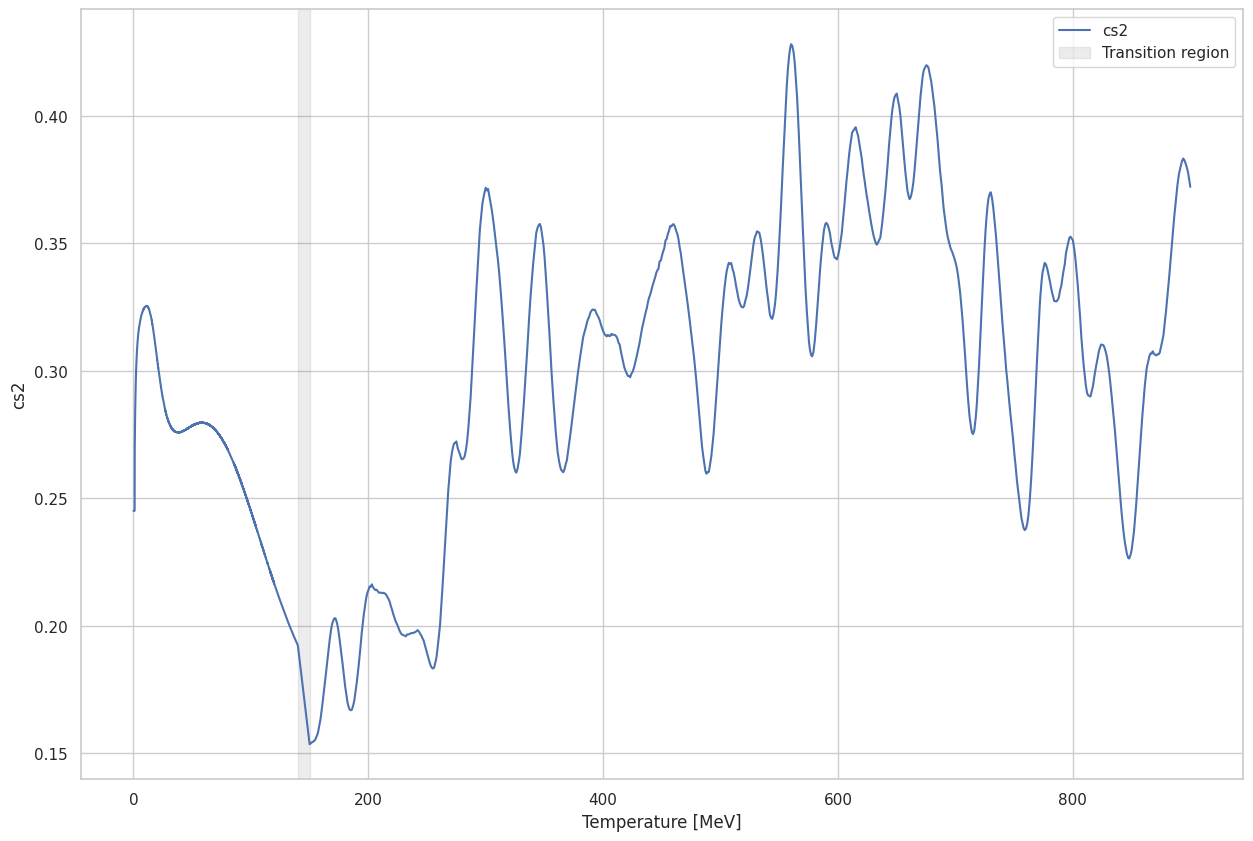

In [ ]:
#cs2 plot, inportalting from 140 to 150 such that it isnt discontinuous

dP_dT_150 = np.gradient(P_hrg_total[:idx_140], T_total[:idx_140])
de_dT_150 = np.gradient(e_hrg_total[:idx_140], T_total[:idx_140])

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_to_interp150 = dP_dT_150 / de_dT_150
# Fill NaNs with first valid value
cs2_hrg_to_interp150[np.isnan(cs2_hrg_to_interp150)] = cs2_hrg_to_interp150[~np.isnan(cs2_hrg_to_interp150)][0]

cs2_to_150 = np.concatenate([cs2_hrg_to_interp150, cs2_interp(T_point01_up[3001:])])

cs2_interp_150 = interp1d(np.concatenate([T_total[:idx_140],T_point01_up[3001:] ]), cs2_to_150, kind='linear')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_interp_150(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(140, 150, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_to_150.png')
plt.show()

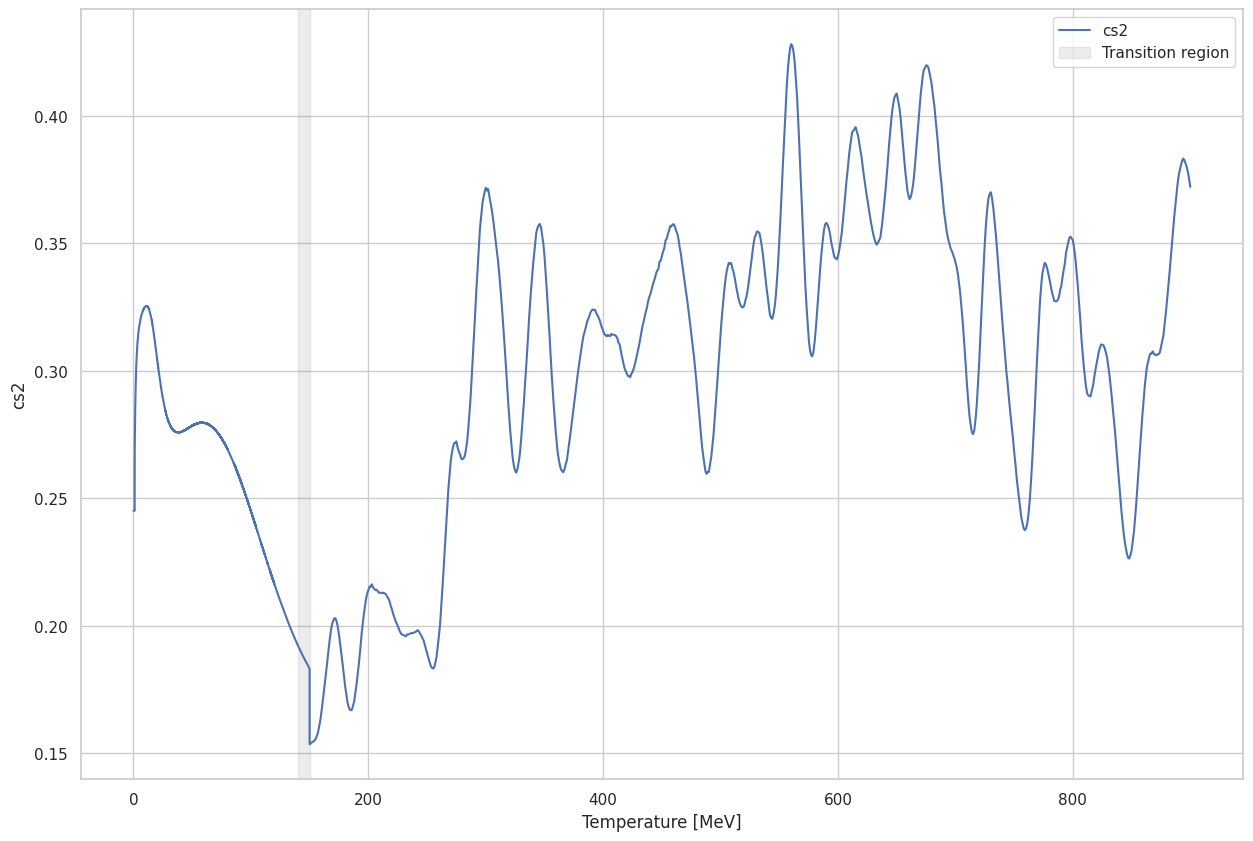

In [ ]:
#without using interp1d, with the descontinuity

dP_dT_Tswdisc = np.gradient(P_hrg_total, T_total[:idx_Tsw])
de_dT_Tswdisc = np.gradient(e_hrg_total, T_total[:idx_Tsw])

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_Tswdisc = dP_dT_Tswdisc / de_dT_Tswdisc

# Fill NaNs with first valid value
cs2_hrg_Tswdisc[np.isnan(cs2_hrg_Tswdisc)] = cs2_hrg_Tswdisc[~np.isnan(cs2_hrg_Tswdisc)][0]

cs2_Tswdisc_total = np.concatenate([cs2_hrg_Tswdisc, cs2_interp(T_point01_up[idx_Tsw_up:])])
cs2_Tswdisc_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), cs2_Tswdisc_total, kind='linear')
df = pd.DataFrame({'T': T_total, 'cs2':cs2_Tswdisc_interp(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='Entropy', label='Entropy')
sns.lineplot(data=df, x='T', y='cs2', label='cs2')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.axvspan(140, 150, color='gray', alpha=0.15, label='Transition region')
plt.legend()
plt.savefig('./images/cs2_transition_to_150_not_cont.png')
plt.show()

In [ ]:
""" sns.set(style="whitegrid", context="talk")

fig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)

cmap = cm.get_cmap('tab10', 7)  
colors = [cmap(i) for i in range(7)]

cs2_all = [] 

for i in range(4):
    entropy_total_plot = []
    pressure_total_plot = []
    energy_total_plot = []
    cs2_hrg_plot = []
    
    cs2_sample_plot = generate_sample()
    
    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)

    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)
    
    s_up_interp = interp1d(T_range_up, s_up_vec, kind='cubic', fill_value="extrapolate")

    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)

    e_up_vec = s_up_vec*T_range_up - P_up_vec

    pressure_total_plot = np.concatenate([pressure_hrg_vec, P_up_vec[301:5801]])
    energy_total_plot = np.concatenate([energy_hrg_vec, e_up_vec[301:5801]])
    entropy_total_plot = np.concatenate([entropy_hrg_vec, s_up_vec[301:5801]])
    
    p_hrg_interp_plot = interp1d(T_total, pressure_total_plot, kind='linear')
    e_hrg_interp_plot = interp1d(T_total, energy_total_plot, kind='linear')
    s_hrg_interp_plot = interp1d(T_total, entropy_total_plot, kind='linear')

    cs2_to_150_plot = np.concatenate([cs2_hrg_to_150, cs2_interp_plot(T_total[1500:])])

    cs2_interp_150 = interp1d(np.concatenate([ T_hrg_to_150[:1400],T_total[1500:] ]), cs2_to_150_plot, kind='cubic')

    color = colors[i] 
    axs[0].plot(T_total, s_hrg_interp_plot(T_total)*(1/hbarc**3), color=color, alpha=0.5, label='entropy' if i == 0 else None)
    axs[1].plot(T_total, p_hrg_interp_plot(T_total)*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='pressure' if i == 0 else None)
    axs[2].plot(T_total, e_hrg_interp_plot(T_total)*MeV4_to_GeV_fm3, color=color, alpha=0.5, label='energy' if i == 0 else None)
    axs[3].plot(T_total, cs2_interp_150(T_total), color=color, alpha=0.5, label=r'$c_s^2$' if i == 0 else None)

# Labels and layout
axs[0].set_ylabel(r"$s(T) (1/fm^3)$")
axs[1].set_ylabel(r"$p(T) (GeV/fm^3)$")
axs[2].set_ylabel(r"$e(T) (GeV/fm^3)$")
axs[3].set_ylabel(r"$c_s^2(T)$")
axs[2].set_xlabel("Temperature T")

for ax in axs:
    ax.legend()
    ax.grid(True)

plt.tight_layout()
plt.savefig('./images/eos_hrg_to_150.png')
plt.show() """

' sns.set(style="whitegrid", context="talk")\n\nfig, axs = plt.subplots(4, 1, figsize=(10, 15), sharex=True)\n\ncmap = cm.get_cmap(\'tab10\', 7)  \ncolors = [cmap(i) for i in range(7)]\n\ncs2_all = [] \n\nfor i in range(4):\n    entropy_total_plot = []\n    pressure_total_plot = []\n    energy_total_plot = []\n    cs2_hrg_plot = []\n\n    cs2_sample_plot = generate_sample()\n\n    cs2_interp_plot = interp1d(T_sampling, cs2_sample_plot)\n\n    s_up_vec = entropy_up(s_sw, T_sw, cs2_interp_plot, T_range_up)\n\n    s_up_interp = interp1d(T_range_up, s_up_vec, kind=\'cubic\', fill_value="extrapolate")\n\n    P_up_vec = pressure_up(P_sw, T_sw, T_range_up, s_up_interp)\n\n    e_up_vec = s_up_vec*T_range_up - P_up_vec\n\n    pressure_total_plot = np.concatenate([pressure_hrg_vec, P_up_vec[301:5801]])\n    energy_total_plot = np.concatenate([energy_hrg_vec, e_up_vec[301:5801]])\n    entropy_total_plot = np.concatenate([entropy_hrg_vec, s_up_vec[301:5801]])\n\n    p_hrg_interp_plot = interp1d(T_

## Saving to file (constrained gp)

In [ ]:
# for constrained GP 

def save_constrained_gp_files(sample_idx, l, sigma):
    while True:
        cs2_sample_file = generate_sample(l, sigma)
        cs2_interp_file = interp1d(T_stepOne_total, cs2_sample_file) 

        s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file(T_point01_up), T_point01_up)
        P_up_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_file)
        P_up_interp_file = interp1d(T_point01_up, P_up_file)
        e_up_file = s_up_file(T_point01_up)*T_point01_up - P_up_interp_file(T_point01_up)

        #pwr extrap vectors
        pressure_pwr_file = np.concatenate([P_extrap_pwr(T_point001_down, T_point01_up, s_up_file, P_up_interp_file), P_up_interp_file(T_point01_up)])
        entropy_pwr_file = np.concatenate([s_extrap_pwr(T_point001_down, T_point01_up, s_up_file, P_up_interp_file), s_up_file(T_point01_up)])
        energy_pwr_file = entropy_pwr_file*T_total - pressure_pwr_file
        #discontinuous cs2
        cs2_pwr_file = np.concatenate([cs2_extrap_pwr(T_point001_110, T_point01_up, s_up_file, P_up_interp_file), cs2_interp_file(T_point01_up)])
        cs2_pwr_file_interp = interp1d(T_concatenate_110to120, cs2_pwr_file, kind='linear')

        #weighted extrap vectors
        pressure_w_file = weightedExtrap_linear(P_hrg_to110, P_up_file)
        energy_w_file = weightedExtrap_linear(e_hrg_to110, e_up_file)
        entropy_w_file = np.where(T_total != 0, (pressure_w_file + energy_w_file) / T_total, 0.0)
        cs2_w_file = cs2_interp_w(cs2_interp_file, pressure_w_file, energy_w_file, T_total)

        if np.any(cs2_w_file[idx_110:idx_120] > 1.0001):
            print("Rejected sample: cs2 > 1 detected")
            continue   # regenerate

        if np.any(cs2_w_file[idx_110:idx_120] < 0):
            print("Rejected sample: negative cs2")
            continue

        #hrg to 150 vectors
        pressure_hrg_file = np.concatenate([P_hrg_total, P_up_file[idx_Tsw_up:]])
        energy_hrg_file = np.concatenate([e_hrg_total, e_up_file[idx_Tsw_up:]])
        entropy_hrg_file = np.concatenate([s_hrg_total, s_up_file(T_point01_up[idx_Tsw_up:])])
        cs2_Tswdisc_file = np.concatenate([cs2_hrg_Tswdisc, cs2_interp_file(T_point01_up[idx_Tsw_up:])])
        #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)
        cs2_Tswdisc_interp_file = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), cs2_Tswdisc_file, kind='linear')
        pressure_hrg_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), pressure_hrg_file, kind='linear')
        energy_hrg_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), energy_hrg_file, kind='linear')
        entropy_hrg_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), entropy_hrg_file, kind='linear') 

        with open(f"./data_files/constrained/l{l}_s{sigma}/eos_pwr_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(energy_pwr_file)}\n")
            for e, T, p, cs2, s in zip(energy_pwr_file, T_total, pressure_pwr_file, cs2_pwr_file_interp(T_total), entropy_pwr_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./data_files/constrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(energy_w_file)}\n")
            for e, T, p, cs2, s in zip(energy_w_file, T_total, pressure_w_file, cs2_w_file, entropy_w_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./data_files/constrained/l{l}_s{sigma}/eos_hrg_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(energy_hrg_interp(T_total))}\n")
            for e, T, p, cs2, s in zip(energy_hrg_interp(T_total), T_total, pressure_hrg_interp(T_total), cs2_Tswdisc_interp_file(T_total), entropy_hrg_interp(T_total)):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n") 
    
        with open(f"./data_files/constrained/l{l}_s{sigma}/thermo_check_w_file.txt", "w") as f:

            for i, T in enumerate(T_total):
                s_value = entropy_w_file[i]*(1/hbarc**3)
                p_value = pressure_w_file[i]*(MeV4_to_GeV_fm3)
                e_value = energy_w_file[i]*(MeV4_to_GeV_fm3)
                check = e_value + p_value
                expected = s_value * T*MeV_to_GeV
                diff = abs(check - expected)

                f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

                if diff > 1e-3:
                    print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}") 

        print("Sample accepted ✔")
        break

In [ ]:
""" for i in range(0, 4):
    save_constrained_gp_files(sample_idx=i, l=10, sigma=15)  """

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


/tmp/ipykernel_5441/3354600047.py:24: RuntimeWarning: invalid value encountered in divide
  entropy_w_file = np.where(T_total != 0, (pressure_w_file + energy_w_file) / T_total, 0.0)


Sample accepted ✔
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
Sample accepted ✔
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
107823
n_transition adjusted to 12079
len vec_down = 107823 len weights = 12079 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
Rejected sample: cs2 > 1 detected
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that t

## Testing

In [ ]:
""" def save_constrained_files_test(sample_idx, l, sigma):
    filename = f"./data_files/constrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat"
    
    data = np.loadtxt(filename, skiprows=1)
    
    T_file  = data[:, 1] / MeV_to_GeV      # convert back to MeV
    cs2_file = data[:, 3]                  
    
    cs2_interp_file = interp1d(T_file, cs2_file, kind='linear', fill_value="extrapolate")

    s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file(T_point01_up), T_point01_up)
    P_up_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_file)
    P_up_interp_file = interp1d(T_point01_up, P_up_file)
    e_up_file = s_up_file(T_point01_up)*T_point01_up - P_up_interp_file(T_point01_up)

    #pwr extrap vectors
    pressure_pwr_file = np.concatenate([P_extrap_pwr(T_point001_down, T_point01_up, s_up_file, P_up_interp_file), P_up_interp_file(T_point01_up)])
    entropy_pwr_file = np.concatenate([s_extrap_pwr(T_point001_down, T_point01_up, s_up_file, P_up_interp_file), s_up_file(T_point01_up)])
    energy_pwr_file = entropy_pwr_file*T_total - pressure_pwr_file
    #discontinuous cs2
    cs2_pwr_file = np.concatenate([cs2_extrap_pwr(T_point001_110, T_point01_up, s_up_file, P_up_interp_file), cs2_interp_file(T_point01_up)])
    cs2_pwr_file_interp = interp1d(T_concatenate_110to120, cs2_pwr_file, kind='linear')

    #weighted extrap vectors
    pressure_w_file = weightedExtrap_linear(P_hrg_total_110, P_up_file)
    energy_w_file = weightedExtrap_linear(e_hrg_total_110, e_up_file)
    entropy_w_file = np.where(T_total != 0, (pressure_w_file + energy_w_file) / T_total, 0.0)
    cs2_w_file = cs2_interp_w(cs2_interp_file, pressure_w_file, energy_w_file, T_total)
    cs2_interp_w_file = interp1d(T_total, cs2_w_file, kind='linear')

    #hrg to 150 vectors
    pressure_hrg_file = np.concatenate([P_hrg_to_150, P_up_file[3001:]])
    energy_hrg_file = np.concatenate([e_hrg_to_150, e_up_file[3001:]])
    entropy_hrg_file = np.concatenate([s_hrg_to_150, s_up_file(T_point01_up[3001:])])
    cs2_150disc_file = np.concatenate([cs2_hrg_150disc, cs2_interp_file(T_point01_up[3001:])])
    #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)
    cs2_150disc_interp_file = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), cs2_150disc_file, kind='linear')
    pressure_hrg_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), pressure_hrg_file, kind='linear')
    energy_hrg_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), energy_hrg_file, kind='linear')
    entropy_hrg_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), entropy_hrg_file, kind='linear') 

    with open(f"./data_files/constrained/l{l}_s{sigma}/Testing_files/newStepsize/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
        f.write(f"{len(energy_w_file)}\n")
        for e, T, p, cs2, s in zip(energy_w_file, T_total, pressure_w_file, cs2_interp_w_file(T_total), entropy_w_file):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n") """

' def save_constrained_files_test(sample_idx, l, sigma):\n    filename = f"./data_files/constrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat"\n\n    data = np.loadtxt(filename, skiprows=1)\n\n    T_file  = data[:, 1] / MeV_to_GeV      # convert back to MeV\n    cs2_file = data[:, 3]                  \n\n    cs2_interp_file = interp1d(T_file, cs2_file, kind=\'linear\', fill_value="extrapolate")\n\n    s_up_file = entropy_up(s_sw, T_sw, cs2_interp_file(T_point01_up), T_point01_up)\n    P_up_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_file)\n    P_up_interp_file = interp1d(T_point01_up, P_up_file)\n    e_up_file = s_up_file(T_point01_up)*T_point01_up - P_up_interp_file(T_point01_up)\n\n    #pwr extrap vectors\n    pressure_pwr_file = np.concatenate([P_extrap_pwr(T_point001_down, T_point01_up, s_up_file, P_up_interp_file), P_up_interp_file(T_point01_up)])\n    entropy_pwr_file = np.concatenate([s_extrap_pwr(T_point001_down, T_point01_up, s_up_file, P_up_interp_file), s_up_

In [ ]:
""" for i in range(21, 22):
    save_constrained_files_test(sample_idx=i, l=10, sigma=15)  """

' for i in range(21, 22):\n    save_constrained_files_test(sample_idx=i, l=10, sigma=15)  '

In [ ]:
""" filename = f"./data_files/constrained/l10_s15/Testing_files/eos_w_s6_l10_s15.dat"
#filename = f"./data_files/constrained/l10_s15/eos_w_s18_l10_s15.dat"
    
data = np.loadtxt(filename, skiprows=1)
    
T_file  = data[:, 1] / MeV_to_GeV      # convert back to MeV
e_file = data[:, 0] / MeV4_to_GeV_fm3
p_file = data[:, 2] / MeV4_to_GeV_fm3
cs2_file = data[:, 3]
cs2_interp_file = interp1d(T_file, cs2_file, kind='linear', fill_value="extrapolate") """

' filename = f"./data_files/constrained/l10_s15/Testing_files/eos_w_s6_l10_s15.dat"\n#filename = f"./data_files/constrained/l10_s15/eos_w_s18_l10_s15.dat"\n\ndata = np.loadtxt(filename, skiprows=1)\n\nT_file  = data[:, 1] / MeV_to_GeV      # convert back to MeV\ne_file = data[:, 0] / MeV4_to_GeV_fm3\np_file = data[:, 2] / MeV4_to_GeV_fm3\ncs2_file = data[:, 3]\ncs2_interp_file = interp1d(T_file, cs2_file, kind=\'linear\', fill_value="extrapolate") '

In [ ]:
""" dP_dT_120_test = np.gradient(p_file[:idx_120] , T_file[:idx_120])
de_dT_120_test = np.gradient(e_file[:idx_120], T_file[:idx_120])

with np.errstate(invalid='ignore', divide='ignore'):
    cs2_hrg_to_interp120_test = dP_dT_120_test / de_dT_120_test

# Fill NaNs with first valid non-NaN value
cs2_hrg_to_interp120_test[np.isnan(cs2_hrg_to_interp120_test)] = cs2_hrg_to_interp120_test[~np.isnan(cs2_hrg_to_interp120_test)][0]

#vector of cs2 for the whole range
cs2_total_w = np.concatenate([cs2_hrg_to_interp120_test, cs2_interp_file(T_point01_up)])

cs2_interp_w = interp1d(T_total, cs2_total_w, kind='linear') """

" dP_dT_120_test = np.gradient(p_file[:idx_120] , T_file[:idx_120])\nde_dT_120_test = np.gradient(e_file[:idx_120], T_file[:idx_120])\n\nwith np.errstate(invalid='ignore', divide='ignore'):\n    cs2_hrg_to_interp120_test = dP_dT_120_test / de_dT_120_test\n\n# Fill NaNs with first valid non-NaN value\ncs2_hrg_to_interp120_test[np.isnan(cs2_hrg_to_interp120_test)] = cs2_hrg_to_interp120_test[~np.isnan(cs2_hrg_to_interp120_test)][0]\n\n#vector of cs2 for the whole range\ncs2_total_w = np.concatenate([cs2_hrg_to_interp120_test, cs2_interp_file(T_point01_up)])\n\ncs2_interp_w = interp1d(T_total, cs2_total_w, kind='linear') "

In [ ]:
""" #cs2 interp plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[:idx_150], cs2_interp_w(T_total[:idx_150]) , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel(f'$c_s^2$')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/cs2_transition_weighted.png')
plt.show() """

" #cs2 interp plot\n\nplt.figure(figsize=(8, 5))\n#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')\n#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')\n\nplt.plot(T_total[:idx_150], cs2_interp_w(T_total[:idx_150]) , '-', linewidth=1.5, color='black', label='Smooth merge')\nplt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')\nplt.xlabel('T [MeV]')\nplt.ylabel(f'$c_s^2$')\nplt.legend()\nplt.title('Transition Between HRG and sample values')\nplt.grid(True)\nplt.tight_layout()\nplt.savefig('./images/cs2_transition_weighted.png')\nplt.show() "

## Unconstrained GP

In [ ]:
cs2_cte_mean = np.full((len(T_stepOne_total)), 0.3)

def unconstrained_sample(l, sigma):   
    k = []
    mean_unc = [phifromsc2(el) for el in cs2_cte_mean]
    for x1 in T_stepOne_total:
        k_row = []
        for x2 in T_stepOne_total:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_stepOne_total))
    sample = list(mean_unc + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample

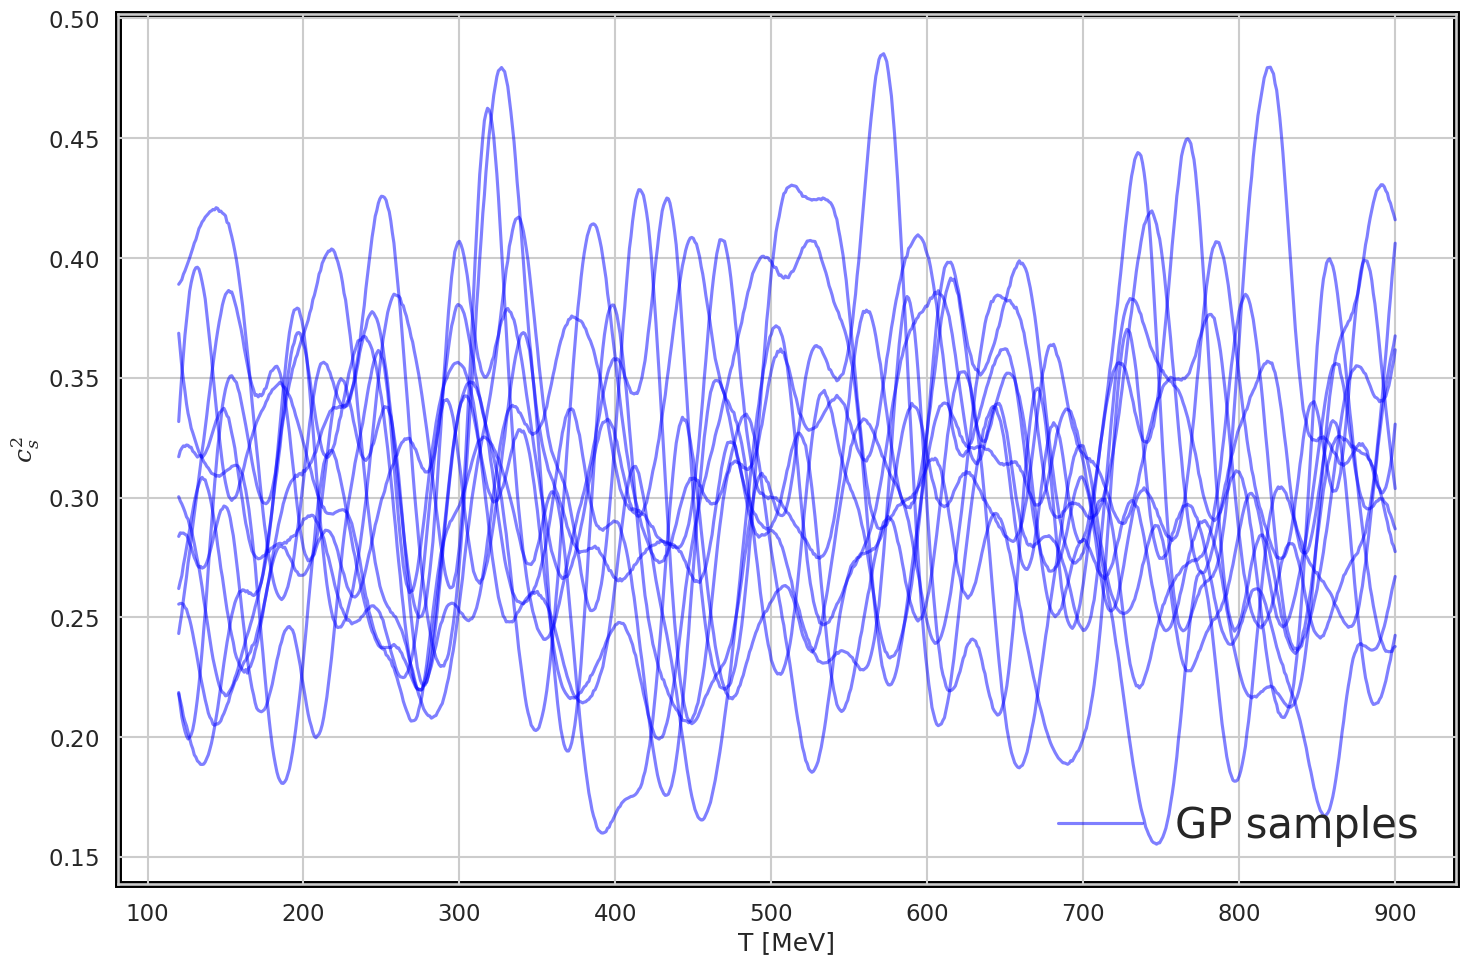

In [ ]:
# Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    cs2_sample_uncPlot = unconstrained_sample(15, 30)
    
    ax.plot(
        T_stepOne_total,
        cs2_sample_uncPlot,
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_unc.png')
plt.show()

In [ ]:
cs2_unc_list = unconstrained_sample(10, 15) #running this changes results below

cs2_interp_unc = interp1d(T_stepOne_total, cs2_unc_list)


In [ ]:
#entropy, pressure and energy upwards
s_up_interp_unc = entropy_up(s_sw, T_sw, cs2_interp_unc(T_point01_up), T_point01_up)

P_up_unc = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp_unc)
P_up_interp_unc = interp1d(T_point01_up, P_up_unc, kind='linear', fill_value="extrapolate")

e_up_unc = energy_up(s_up_interp_unc, P_up_interp_unc, T_point01_up)

### Weighted interpolation

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


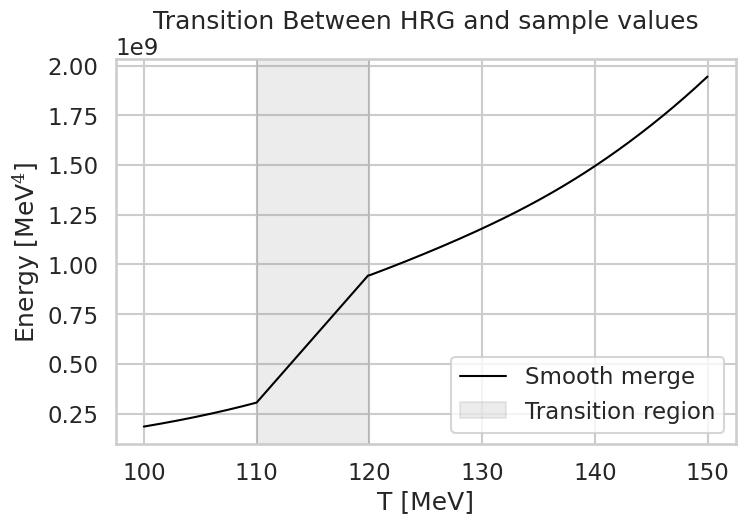

In [ ]:
# Energy plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

e_unc_plot = weightedExtrap_linear(e_hrg_to110, e_up_unc)

plt.plot(T_total[idx_100:idx_150], e_unc_plot[idx_100:idx_150] , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_e_transition_unc.png')
plt.show()

103397
n_transition adjusted to 16505
len vec_down = 103397 len weights = 16505 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


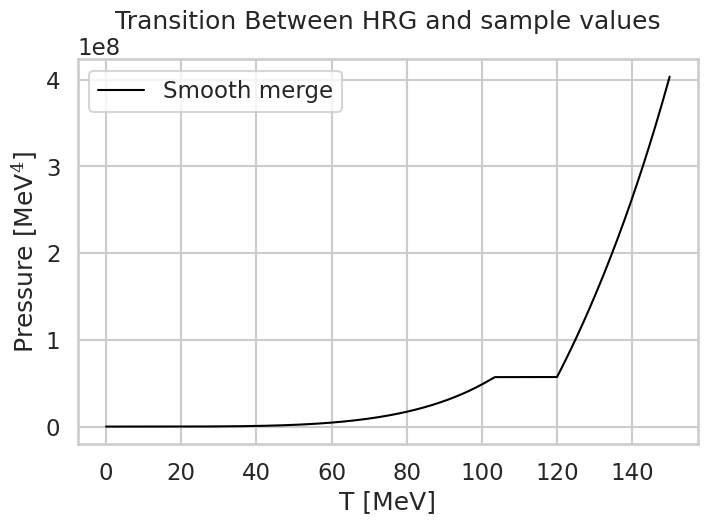

In [ ]:
#Pressure plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

p_plot_unc = weightedExtrap_linear(P_hrg_to110, P_up_unc)

plt.plot(T_total[:idx_150], p_plot_unc[:idx_150] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_p_transition_unc.png')
plt.show()

last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
103397
n_transition adjusted to 16505
len vec_down = 103397 len weights = 16505 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


/tmp/ipykernel_5441/2977990241.py:1: RuntimeWarning: invalid value encountered in divide
  s_plot_unc = (weightedExtrap_linear(e_hrg_to110, e_up_unc) + weightedExtrap_linear(P_hrg_to110, P_up_unc))/T_total


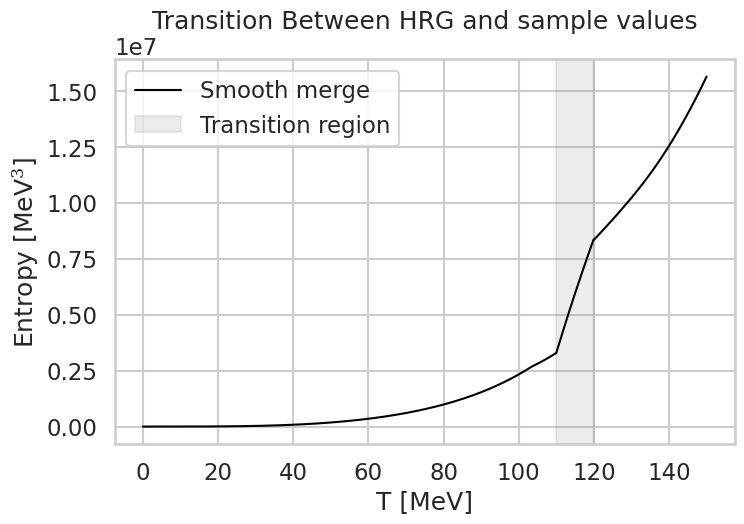

In [ ]:
s_plot_unc = (weightedExtrap_linear(e_hrg_to110, e_up_unc) + weightedExtrap_linear(P_hrg_to110, P_up_unc))/T_total

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[:idx_150], s_plot_unc[:idx_150] , '-', linewidth=1.5, color='black', label='Smooth merge')
plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.savefig('./images/hrg_s_transition_unc.png')
plt.show()

/tmp/ipykernel_5441/2118117263.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


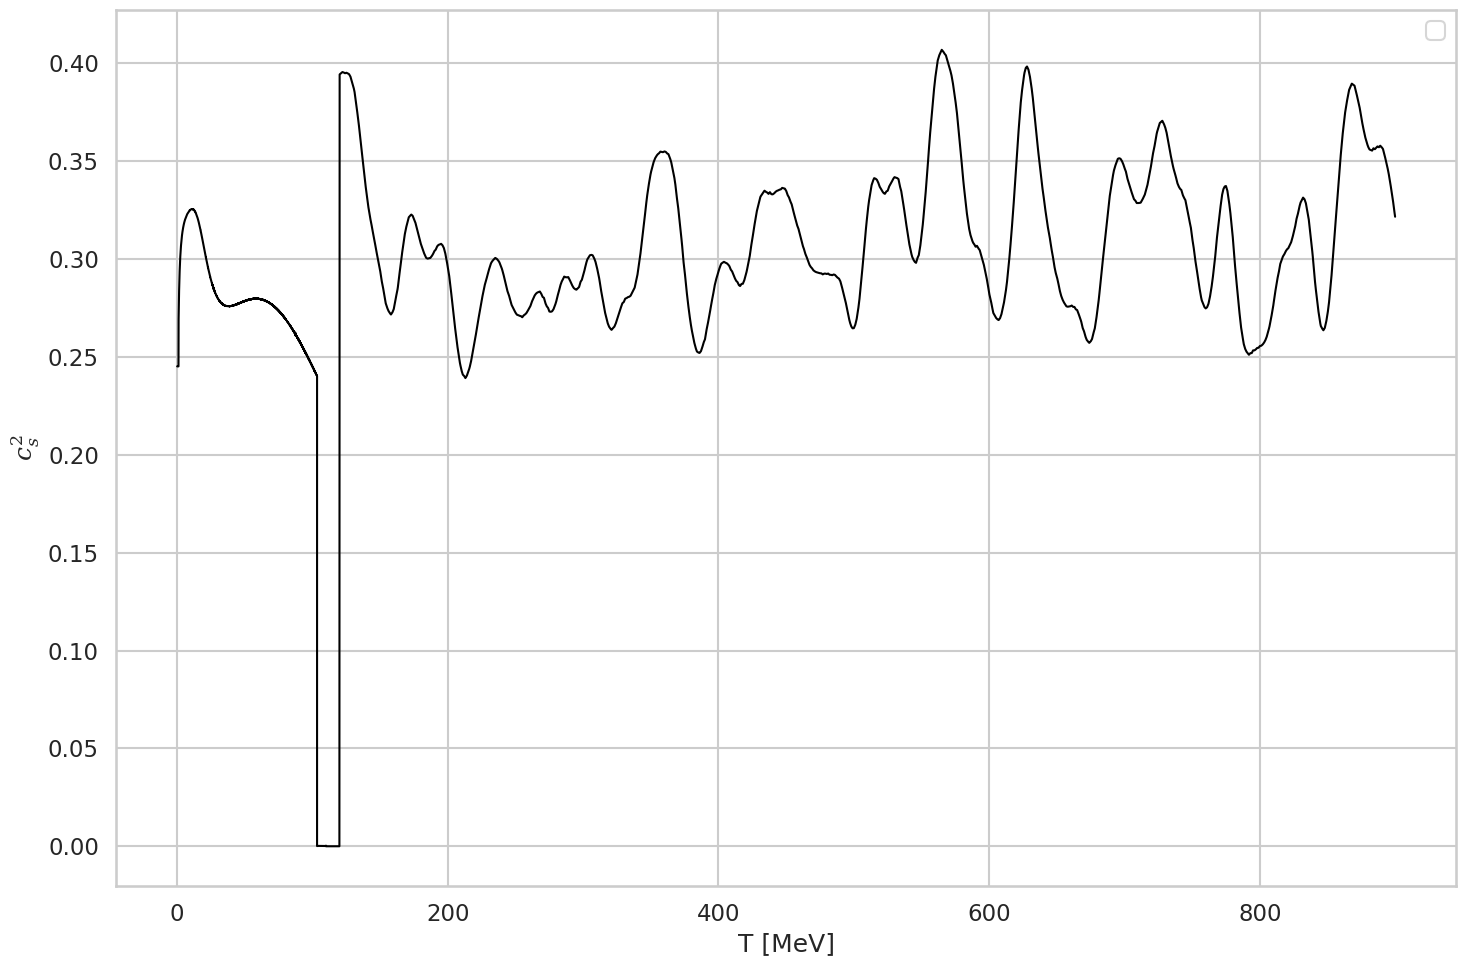

In [ ]:
#cs2 

""" cs2_range_unc = np.concatenate([cs2_hrg_to_interp, cs2_interp_unc(T_point01_up)])

cs2_extrap_unc = interp1d(T_concatenate_110to120, cs2_range_unc, kind='cubic') """

cs2_w_plot_unc = cs2_interp_w(cs2_interp_unc, p_plot_unc, e_unc_plot, T_total)

plt.plot(T_total, cs2_w_plot_unc , '-', linewidth=1.5, color='black')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel(f'$c_s^2$')
plt.legend()
#plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/cs2_total_unc.png')
plt.show()

In [ ]:
#checking thermodynamic consistency

with open("./check_files/thermo_check_w_unc.txt", "w") as f:
    p_unc = weightedExtrap_linear(P_hrg_to110, P_up_unc)
    e_unc = weightedExtrap_linear(e_hrg_to110, e_up_unc)
    s_unc = (p_unc + e_unc)/T_total

    for i, T in enumerate(T_total):
        s_value = s_unc[i]
        p_value = p_unc[i]
        e_value = e_unc[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

/tmp/ipykernel_5441/1238456903.py:6: RuntimeWarning: invalid value encountered in divide
  s_unc = (p_unc + e_unc)/T_total


103397
n_transition adjusted to 16505
len vec_down = 103397 len weights = 16505 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


### Power law extrap

In [ ]:
pressure_pwr_unc = np.concatenate([P_extrap_pwr(T_point001_down, T_point01_up, s_up_interp_unc, P_up_interp_unc), P_up_interp_unc(T_point01_up)])
entropy_pwr_unc = np.concatenate([s_extrap_pwr(T_point001_down, T_point01_up, s_up_interp_unc, P_up_interp_unc), s_up_interp_unc(T_point01_up)])
energy_pwr_unc = entropy_pwr_unc*T_total - pressure_pwr_unc

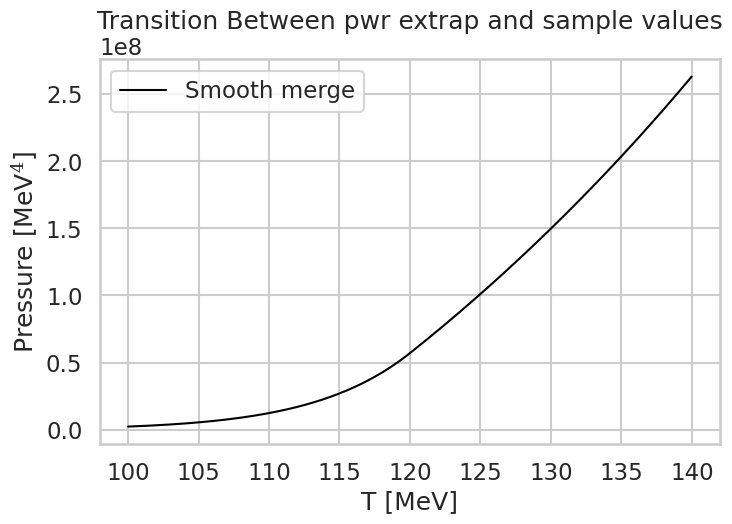

In [ ]:
#Pressure plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[idx_100:idx_140], pressure_pwr_unc[idx_100:idx_140] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.title('Transition Between pwr extrap and sample values')
plt.grid(True)
plt.savefig('./images/pwr_p_transition_unc.png')
plt.show()

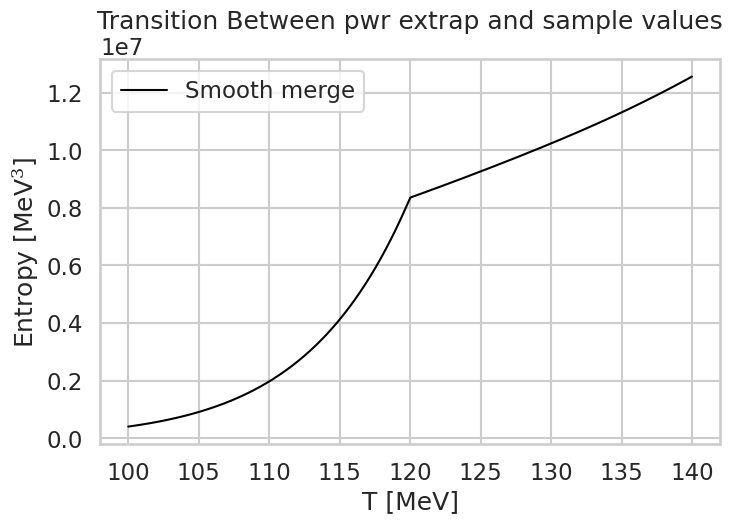

In [ ]:
#entropy plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[idx_100:idx_140], entropy_pwr_unc[idx_100:idx_140] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.title('Transition Between pwr extrap and sample values')
plt.grid(True)
plt.savefig('./images/pwr_s_transition_unc.png')
plt.show()

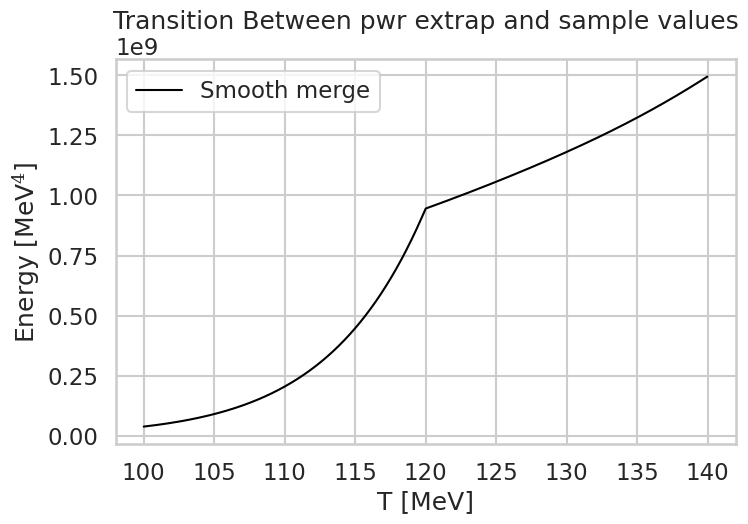

In [ ]:
#energy plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[idx_100:idx_140], energy_pwr_unc[idx_100:idx_140] , '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(105, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between pwr extrap and sample values')
plt.grid(True)
plt.savefig('./images/pwr_e_transition_unc.png')
plt.show()

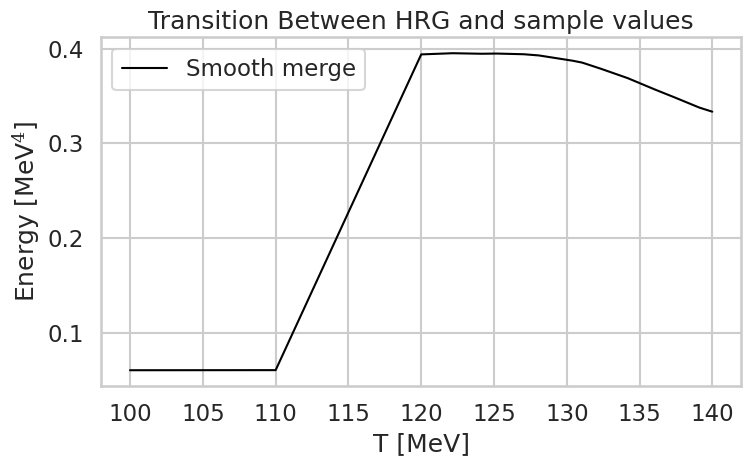

In [ ]:
#cs2 

cs2_vec_pwr_unc = np.concatenate([cs2_extrap_pwr(T_point001_down[:idx_110], T_point01_up, s_up_interp_unc, P_up_interp_unc), cs2_interp_unc(T_point01_up)])

cs2_pwr_unc = interp1d(T_concatenate_110to120, cs2_vec_pwr_unc, kind='linear')


# Plot

plt.figure(figsize=(8, 5))
#plt.plot(T_range_hrg, pressure_down_vec, 'o--', label='Down data')
#plt.plot(T_range_up[0:20], P_up[0:20], 'o--', label='Up data')

plt.plot(T_total[idx_100:idx_140], cs2_pwr_unc(T_total[idx_100:idx_140]), '-', linewidth=1.5, color='black', label='Smooth merge')
#plt.axvspan(110, 120, color='gray', alpha=0.15, label='Transition region')
plt.xlabel('T [MeV]')
plt.ylabel('Energy [MeV$^4$]')
plt.legend()
plt.title('Transition Between HRG and sample values')
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/pwr_cs2_transition_unc.png')
plt.show()

In [ ]:
with open("./check_files/thermo_check_pwr_unc.txt", "w") as f:
    p = pressure_pwr_unc
    e = energy_pwr_unc
    s = (p + e)/T_total

    for i, T in enumerate(T_total):
        s_value = s[i]
        p_value = p[i]
        e_value = e[i]
        check = e_value + p_value
        expected = s_value * T
        diff = abs(check - expected)

        f.write(f"T = {T:.2f} MeV | e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}\n")

        if diff > 1e-3:
            print(f"Discrepancy at T = {T:.2f} MeV: e + p = {check:.6f}, s*T = {expected:.6f}, diff = {diff:.2e}")

/tmp/ipykernel_5441/1248283010.py:4: RuntimeWarning: invalid value encountered in divide
  s = (p + e)/T_total


### HRG up to Tsw 

In [ ]:
P_total_Tsw_unc = np.concatenate([P_hrg_total, P_up_unc[idx_Tsw_up:]])
e_total_Tsw_unc = np.concatenate([e_hrg_total, e_up_unc[idx_Tsw_up:]])
s_total_Tsw_unc = np.concatenate([s_hrg_total, s_up_interp_unc(T_point01_up[idx_Tsw_up:])])

p_hrg_interp_unc = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), P_total_Tsw_unc, kind='linear')
e_hrg_interp_unc = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), e_total_Tsw_unc, kind='linear')
s_hrg_interp_unc = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), s_total_Tsw_unc, kind='linear')

/tmp/ipykernel_5441/349193504.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


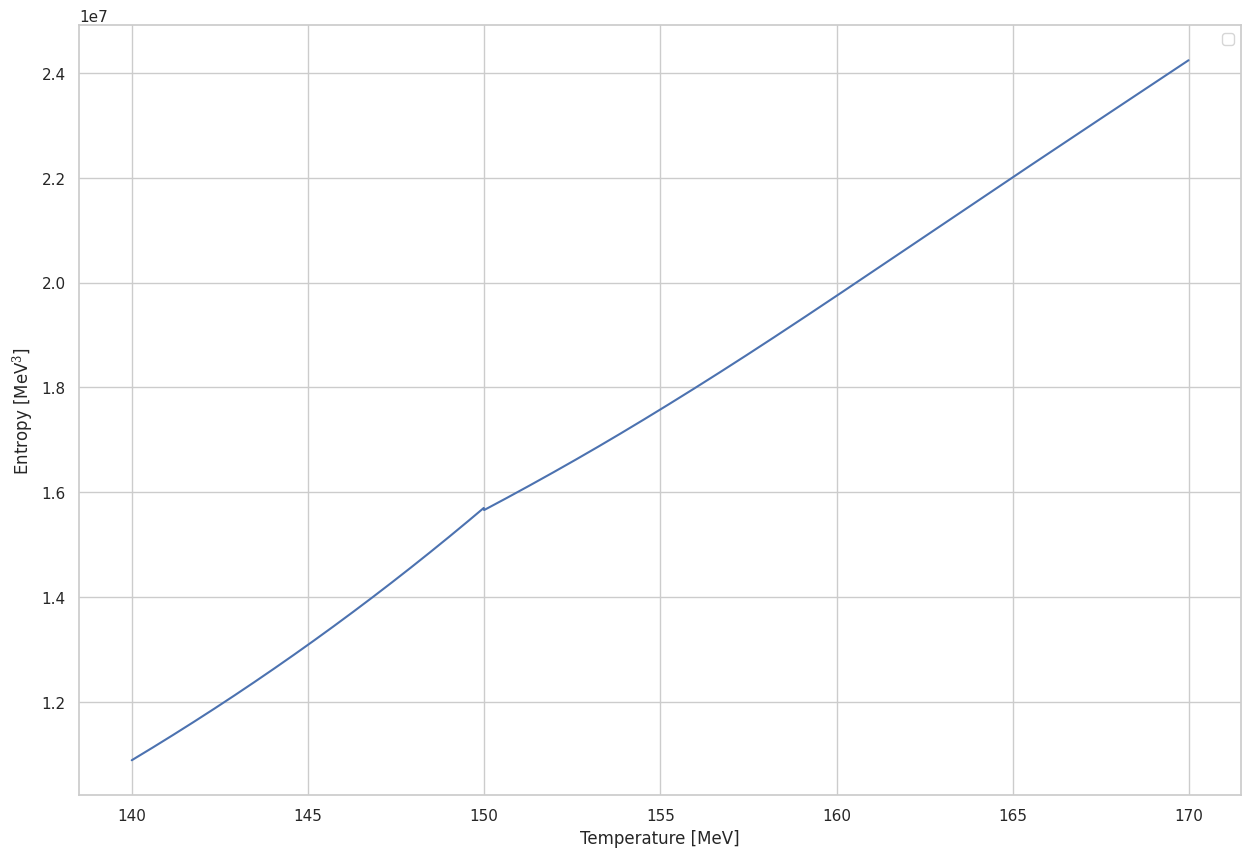

In [ ]:
df = pd.DataFrame({'T': T_total[idx_140:idx_170], 'pressure': s_hrg_interp_unc(T_total[idx_140:idx_170])})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='pressure')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Entropy [MeV$^3$]')
plt.legend()
plt.savefig('./images/s_unc_hrg_150.png')
plt.show()

/tmp/ipykernel_5441/3169840735.py:14: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


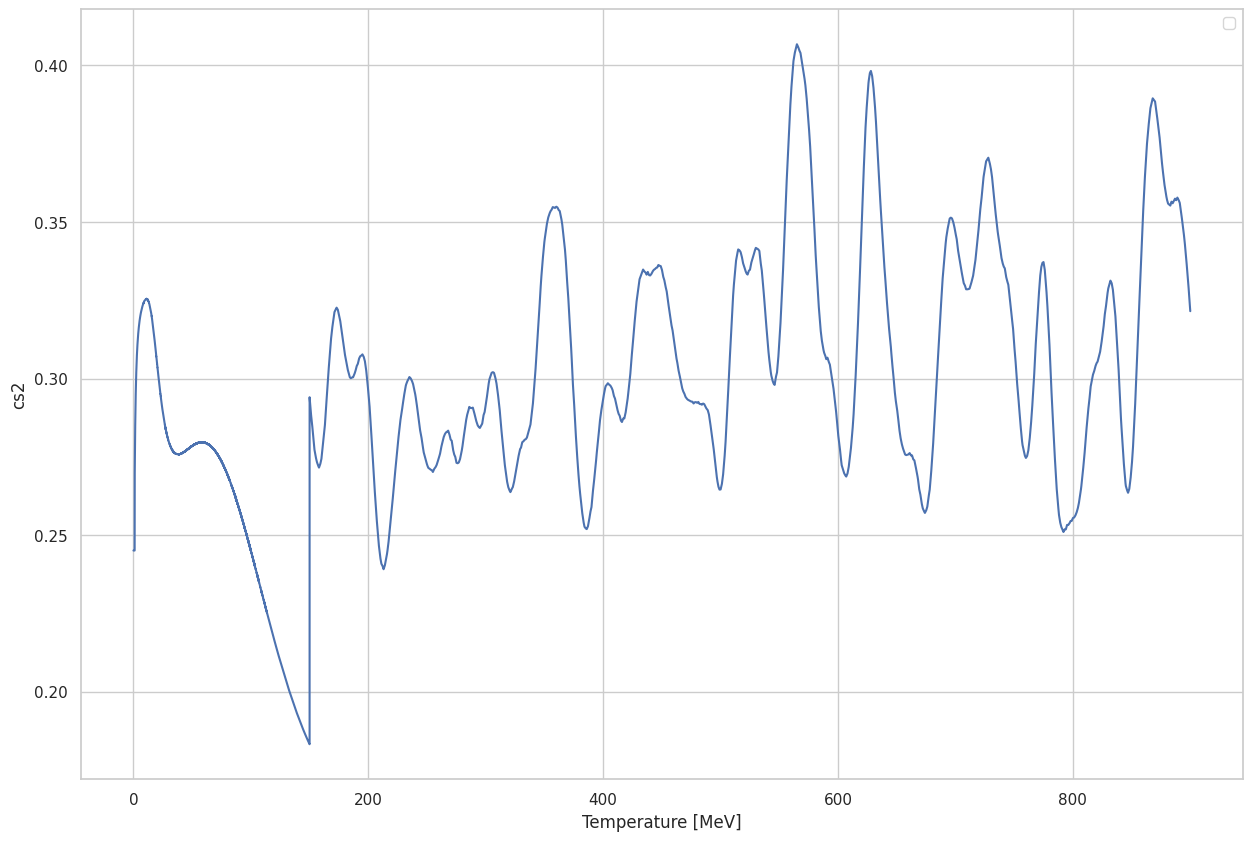

In [ ]:
cs2_Tswdisc_unc = np.concatenate([cs2_hrg_Tswdisc, cs2_interp_unc(T_point01_up[idx_Tsw_up:])])
    #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)
cs2_Tswdisc_unc_interp = interp1d(np.concatenate([T_total[:idx_Tsw],T_point01_up[idx_Tsw_up:]]), cs2_Tswdisc_unc, kind='linear')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_Tswdisc_unc_interp(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='cs2')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.legend()
plt.savefig('./images/cs2_unc_hrg_150.png')
plt.show()

## Saving to files (unconstrained gp)

In [ ]:
def save_unc_gp_files(sample_idx, l, sigma):
    while True:
        cs2_unc_file = unconstrained_sample(15, 30) #running this changes results below
        cs2_interp_unc_file = interp1d(T_stepOne_total, cs2_unc_file)

        s_up_unc_file = entropy_up(s_sw, T_sw, cs2_interp_unc_file(T_point01_up), T_point01_up)
        P_up_unc_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_unc_file)
        P_up_unc_interp_file = interp1d(T_point01_up, P_up_unc_file, kind='linear', fill_value="extrapolate")   
        e_up_unc_file = s_up_unc_file(T_point01_up) * T_point01_up - P_up_unc_interp_file(T_point01_up)

        #pwr extrap vectors
        pressure_pwr_unc_file = np.concatenate([P_extrap_pwr(T_point001_down, T_point01_up, s_up_unc_file, P_up_unc_interp_file), P_up_unc_file])
        entropy_pwr_unc_file = np.concatenate([s_extrap_pwr(T_point001_down, T_point01_up, s_up_unc_file, P_up_unc_interp_file), s_up_unc_file(T_point01_up)])
        energy_pwr_unc_file = entropy_pwr_unc_file*T_total - pressure_pwr_unc_file
        cs2_pwr_unc = np.concatenate([cs2_extrap_pwr(T_point001_110, T_point01_up, s_up_unc_file, P_up_unc_interp_file), cs2_interp_unc_file(T_point01_up)])
        cs2_pwr_unc_file_interp = interp1d(T_concatenate_110to120, cs2_pwr_unc, kind='quadratic')

        #weighted extrap vectors
        pressure_w_unc_file = weightedExtrap_linear(P_hrg_to110, P_up_unc_file)
        energy_w_unc_file = weightedExtrap_linear(e_hrg_to110, e_up_unc_file)
        entropy_w_unc_file = np.where(T_total != 0, (pressure_w_unc_file + energy_w_unc_file) / T_total, 0.0)
        cs2_w_unc_file = cs2_interp_w(cs2_interp_unc_file, pressure_w_unc_file, energy_w_unc_file, T_total)

        if np.any(cs2_w_unc_file[idx_110:idx_120] > 1.0001):
            print("Rejected sample: cs2 > 1 detected")
            continue   # regenerate

        if np.any(cs2_w_unc_file[idx_110:idx_120] < 0):
            print("Rejected sample: negative cs2")
            continue

        #hrg to 150 vectors
        pressure_hrg_unc_file = np.concatenate([P_hrg_total, P_up_unc_file[idx_Tsw_up:]])
        energy_hrg_unc_file = np.concatenate([e_hrg_total, e_up_unc_file[idx_Tsw_up:]])
        entropy_hrg_unc_file = np.concatenate([s_hrg_total, s_up_unc_file(T_point01_up[idx_Tsw_up:])])
        cs2_150disc_unc_file = np.concatenate([cs2_hrg_Tswdisc, cs2_interp_unc_file(T_point01_up[idx_Tsw_up:])])
        #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)
        cs2_150_unc_file_interp = interp1d(np.concatenate([T_total[:idx_Tsw],T_point01_up[idx_Tsw_up:]]), cs2_150disc_unc_file, kind='linear')
        pressure_hrg_unc_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), pressure_hrg_unc_file, kind='linear')
        energy_hrg_unc_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), energy_hrg_unc_file, kind='linear')
        entropy_hrg_unc_interp = interp1d(np.concatenate([T_total[:idx_Tsw], T_point01_up[idx_Tsw_up:]]), entropy_hrg_unc_file, kind='linear')

        with open(f"./data_files/unconstrained/l{l}_s{sigma}/eos_pwr_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(energy_pwr_unc_file)}\n")
            for e, T, p, cs2, s in zip(energy_pwr_unc_file, T_total, pressure_pwr_unc_file, cs2_pwr_unc_file_interp(T_total), entropy_pwr_unc_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./data_files/unconstrained/l{l}_s{sigma}/eos_w_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(energy_w_unc_file)}\n")
            for e, T, p, cs2, s in zip(energy_w_unc_file, T_total, pressure_w_unc_file, cs2_w_unc_file, entropy_w_unc_file):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        with open(f"./data_files/unconstrained/l{l}_s{sigma}/eos_hrg_s{sample_idx}_l{l}_s{sigma}.dat", "w") as f:
            f.write(f"{len(energy_hrg_unc_interp(T_total))}\n")
            for e, T, p, cs2, s in zip(energy_hrg_unc_interp(T_total), T_total, pressure_hrg_unc_interp(T_total), cs2_150_unc_file_interp(T_total), entropy_hrg_unc_interp(T_total)):
                f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")

        print("Sample accepted ✔")
        break

In [ ]:
""" for i in range(7, 9):
    save_unc_gp_files(sample_idx=i, l=10, sigma=15) """

104578
n_transition adjusted to 15324
len vec_down = 104578 len weights = 15324 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903


/tmp/ipykernel_5441/943845027.py:21: RuntimeWarning: invalid value encountered in divide
  entropy_w_unc_file = np.where(T_total != 0, (pressure_w_unc_file + energy_w_unc_file) / T_total, 0.0)


Sample accepted ✔
107715
n_transition adjusted to 12187
len vec_down = 107715 len weights = 12187 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
last valid index is 109999
n_transition adjusted to 9902
len vec_down = 110000 len weights = 9902 len vec_up = 78001 such that the difference should be zero = 0
Final length check: 197903 should be 197903
Sample accepted ✔


## Jackknife samples

In [ ]:
T_js = np.linspace(120,260,260-120+1)

j_samples = data.iloc[:, 3:] #selects all lines and all columns after the 3rd
jk_mean = j_samples.mean(axis=1) #mean over each row (axis=1), over the 48 samples for each T
N = j_samples.shape[1]
#print(j_samples.T)

#transpose of j_sample (N_T, N_samples) to (N_samples, N_T), subtracts the mean from each column
X = j_samples.T.sub(jk_mean, axis=1)  

#calculate covariance matrix
var_jk = ((N-1)/N) * ((j_samples.sub(jk_mean, axis=0)) ** 2).sum(axis=1)
cov_matrix = (X.T @ X)*((N-1)/N)

#print(X.T)
#print(cov_matrix)
#print(var_jk)

In [ ]:
#correlation matrix

cov_np = cov_matrix.to_numpy()
corr_matrix = np.zeros_like(cov_np)

#print(cov_np[0, 141])

for i in range(0, 140):
    for j in range(0, 140):
        denom = np.sqrt(cov_np[i, i] * cov_np[j, j])
        if denom > 0:
            corr_matrix[i, j] = cov_np[i, j] / denom
        else:
            corr_matrix[i, j] = 0


In [ ]:
def is_positive_definite_eig(matrix):
    return np.all(np.linalg.eigvalsh(matrix) >= 1e-10)

print(np.linalg.eigvalsh(cov_matrix))

print(is_positive_definite_eig(cov_matrix)) 


[-1.37953410e-18 -1.00791853e-18 -8.12938652e-19 -4.26212799e-19
 -3.23060037e-19 -3.10271275e-19 -2.43912438e-19 -2.33330365e-19
 -2.13351936e-19 -1.78103056e-19 -1.56530479e-19 -1.41967759e-19
 -1.28934727e-19 -1.22349042e-19 -1.16184186e-19 -1.12074382e-19
 -1.03605560e-19 -1.00509891e-19 -9.86220640e-20 -9.08773574e-20
 -8.69645017e-20 -7.74414775e-20 -7.58653676e-20 -6.83250596e-20
 -6.57249628e-20 -6.47708425e-20 -6.01014723e-20 -5.68009690e-20
 -5.44865352e-20 -5.20517713e-20 -5.03829882e-20 -4.33444677e-20
 -4.20283382e-20 -3.91919948e-20 -3.88044430e-20 -3.50977871e-20
 -3.20519034e-20 -3.16233060e-20 -2.79668829e-20 -2.53664604e-20
 -2.37127779e-20 -2.17925140e-20 -1.77815719e-20 -1.61916935e-20
 -1.48289214e-20 -1.44837973e-20 -1.29571452e-20 -1.02023031e-20
 -8.88129638e-21 -7.38605416e-21 -6.27563017e-21 -5.22978914e-21
 -3.87635315e-21 -2.80733875e-21  8.49453097e-23  1.01091349e-21
  1.09973006e-21  3.13980449e-21  5.63801228e-21  8.26621463e-21
  9.02624088e-21  1.20200

In [ ]:
with open("jk_check.txt", "w") as f:
    for i, T in enumerate(T_js):
        diff = (jk_mean - GP_mean_lat_file).iloc[i]
        diff_2 = (lattice_cs2.error - np.sqrt(var_jk)).iloc[i]

        f.write(f"T = {T:.2f} MeV, mean diff = {diff:.2e}, var diff = {diff_2:.2e}\n")


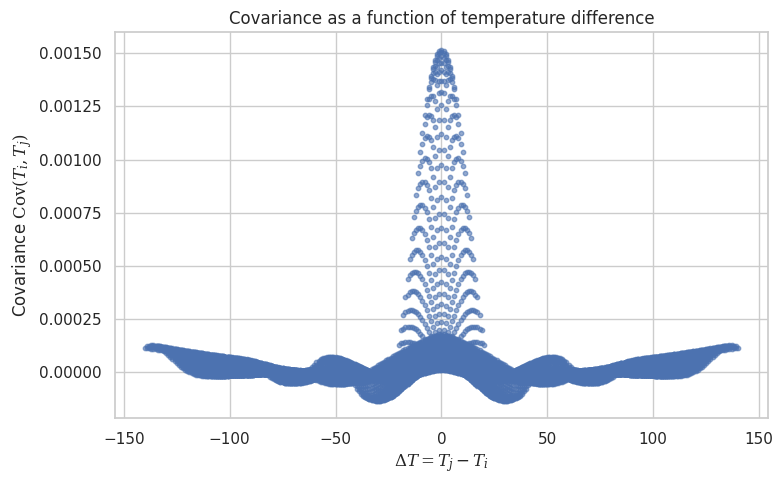

In [ ]:
T = data.iloc[:, 0].values
delta_T = T[np.newaxis, :] - T[:, np.newaxis]  # shape: (n_T, n_T)

# Flatten both matrices
delta_T_flat = delta_T.flatten()
cov_flat = cov_matrix.to_numpy().flatten()

# Plot covariance vs. ΔT
plt.figure(figsize=(8, 5))
plt.scatter(delta_T_flat, cov_flat, s=10, alpha=0.6)
plt.xlabel(r'$\Delta T = T_j - T_i$')
plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
plt.title("Covariance as a function of temperature difference")
plt.grid(True)
plt.tight_layout()

#plt.savefig('cov_matrix.png')
plt.show()

/tmp/ipykernel_5441/1929379322.py:8: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', 141)


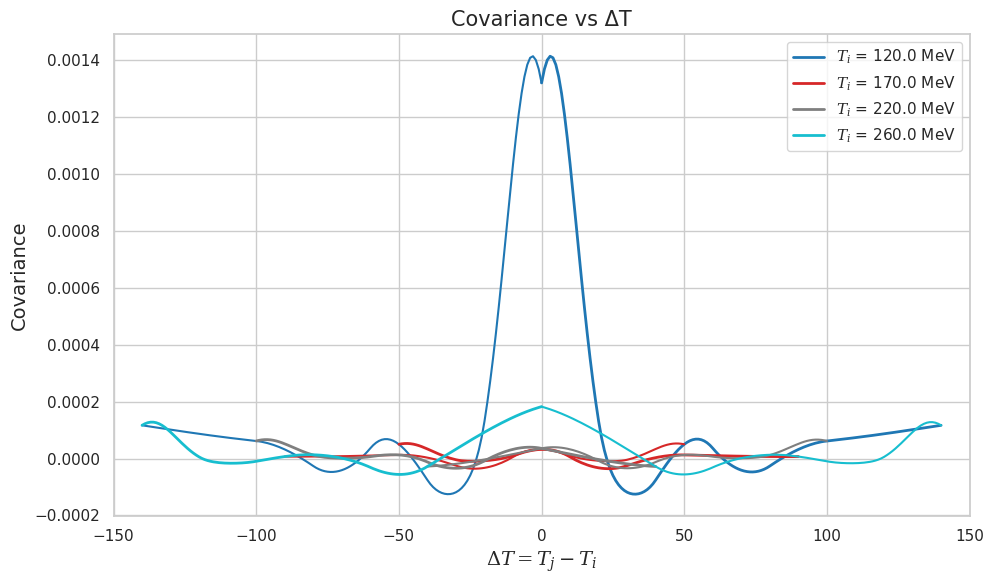

In [ ]:
#plot slices

cov = cov_matrix.to_numpy()

plt.figure(figsize=(10, 6))

rows_to_plot = [0, 50, 100, 140]
cmap = cm.get_cmap('tab10', 141)  
colors = [cmap(i) for i in range(141)]
#print(len(colors))

for i in rows_to_plot:
    color = colors[i] 
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    #delta_T_plot = np.concatenate([delta_T_minus, delta_T_plus])
    #cov_plot = np.concatenate([cov[i, :], cov[i, :]])
    cov_row = cov[i, :]

    plt.plot(delta_T_plus, cov[:, i], color=color, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)
    plt.plot(delta_T_minus, cov[:, i], color=color)
    #plt.plot(delta_T_plot, cov_plot, label=rf"$T_i$ = {T[i]:.1f} MeV", linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT', fontsize=15)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.xlim(-150, 150)
plt.savefig("./images/covariance_slices.png")
plt.show()

In [ ]:
#curve fitting save to file

def gaussian(x, sigma, l):
    return sigma * np.exp(-(x**2) / (2 * l**2))

sigma_fit_vec = []
l_fit_vec = []

with open("gaussian_fit_results.dat", "w") as f:
    f.write("# T    sigma    l\n")
    
    for i in range(len(T)):
        delta_T_plus = T - T[i]
        delta_T_minus = T[i] - T
        delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])
        cov_row = np.concatenate([cov[i, ::-1], cov[i, :]])

        try:
            #p0: initial guess for the parameters
            # Here, we use the diagonal element as the initial guess for sigma and a fixed value for l
            popt, _ = curve_fit(gaussian, delta_T, cov_row, p0=[cov[i, i], 10])
            # unpacks the two fitted parameters from popt:
            sigma_fit, l_fit = popt
        except RuntimeError:
            sigma_fit, l_fit = np.nan, np.nan

        sigma_fit_vec.append(sigma_fit)
        l_fit_vec.append(l_fit)

        f.write(f"{T[i]}  {sigma_fit}  {l_fit}\n")


/tmp/ipykernel_5441/2873404945.py:2: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab10', len(rows_to_plot))


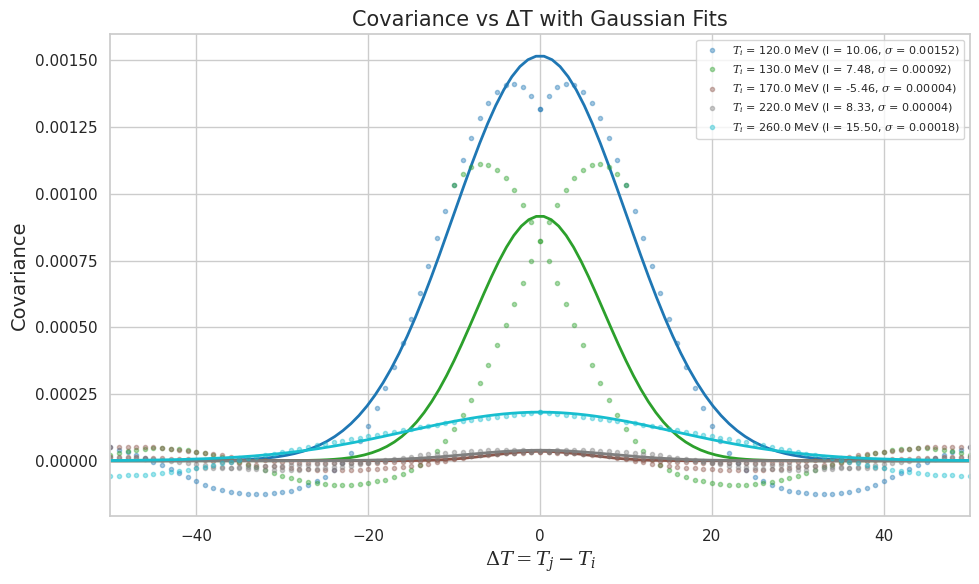

In [ ]:
rows_to_plot = [0, 10, 50, 100, 140]
cmap = cm.get_cmap('tab10', len(rows_to_plot))
colors = [cmap(i) for i in range(len(rows_to_plot))]

plt.figure(figsize=(10, 6))

for idx, i in enumerate(rows_to_plot):
    # ΔT for both sides
    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    cov_row = np.concatenate([cov[i, ::-1], cov[i, :]])  # match order

    # Fit Gaussian
    popt, pcov = curve_fit(gaussian, delta_T, cov_row, p0=[cov[i, i], 10])
    sigma_fit, l_fit = popt

    # Plot data
    plt.plot(delta_T, cov_row, 'o', markersize=3, color=colors[idx], alpha=0.4,
             label=rf"$T_i$ = {T[i]:.1f} MeV (l = {l_fit:.2f}, $\sigma$ = {sigma_fit:.5f})")
    
    # Plot fitted Gaussian
    x_fit = np.linspace(delta_T.min(), delta_T.max(), 300)
    plt.plot(x_fit, gaussian(x_fit, *popt), '-', color=colors[idx], linewidth=2)

plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Covariance', fontsize=14)
plt.title('Covariance vs ΔT with Gaussian Fits', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/covariance_gaussian_fits.png")
plt.show()

/tmp/ipykernel_5441/1820230671.py:11: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('viridis')  # continuous colormap


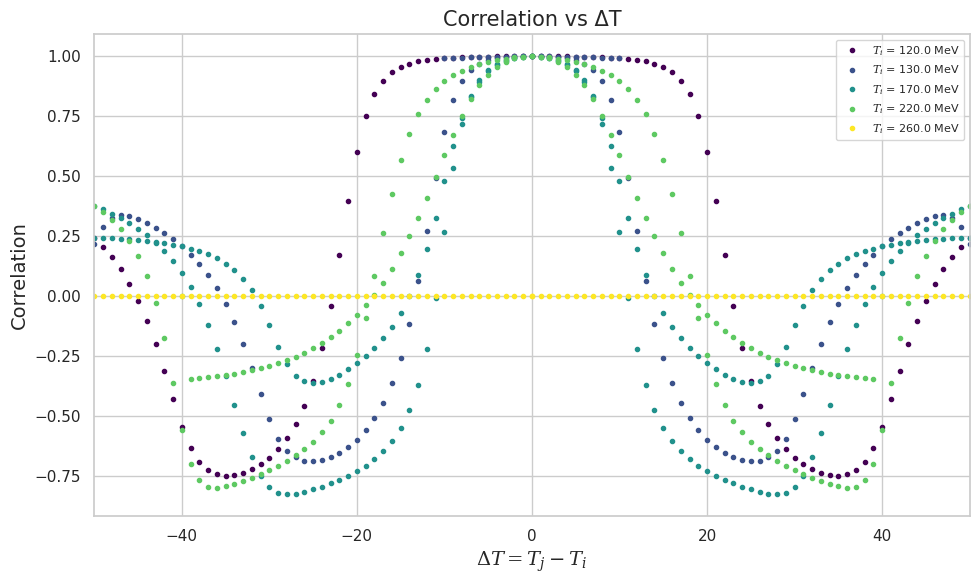

In [ ]:
#plot corr matrix


plt.figure(figsize=(10, 6))

rows_to_plot = [0, 10, 50, 100, 140]
""" cmap = cm.get_cmap('viridis', 141)  # or 'coolwarm'
colors = [cmap(i) for i in range(141)] """
#print(len(colors))

cmap = cm.get_cmap('viridis')  # continuous colormap
num_rows = len(rows_to_plot)

for idx, i in enumerate(rows_to_plot):
    color = cmap(idx / (num_rows - 1))

    delta_T_plus = T - T[i]
    delta_T_minus = T[i] - T
    delta_T = np.concatenate([delta_T_minus[::-1], delta_T_plus])  # symmetric
    corr_row = np.concatenate([corr_matrix[i, ::-1], corr_matrix[i, :]])

    plt.plot(delta_T_plus, corr_matrix[i, :], 'o', markersize=3, color=color, label=rf"$T_i$ = {T[i]:.1f} MeV")
    plt.plot(delta_T_minus, corr_matrix[i, :], 'o', markersize=3, color=color)
    #plt.plot(delta_T, corr_row, linewidth=2)


plt.xlabel(r'$\Delta T = T_j - T_i$', fontsize=14)
plt.ylabel('Correlation', fontsize=14)
plt.title('Correlation vs ΔT', fontsize=15)
plt.grid(True)
plt.legend(fontsize=8)
plt.tight_layout()
plt.xlim(-50, 50)
plt.savefig("./images/corr_slices.png")
plt.show()

In [ ]:
# k = []
# for x1 in T_js:
#     k_row = []
#     for x2 in T_js:
#         k_row.append(kernel_func(x1, x2, sigma, l)) 
#     k.append(k_row)   
# k = np.array(k)
# k[np.diag_indices_from(k)] += 0.001
# Sigma = cholesky(k)

In [ ]:
# T_k = np.array(T_js)
# delta_T_k = T_k[np.newaxis, :] - T_k[:, np.newaxis]

# #transf into 1D array
# delta_T_flat_k = delta_T_k.flatten()
# k_flat = k.flatten()
# sigma_flat = Sigma.flatten()

# # Plot covariance vs. ΔT
# plt.figure(figsize=(8, 5))
# plt.scatter(delta_T_flat_k, k_flat, s=10, alpha=0.6)
# plt.xlabel(r'$\Delta T = T_j - T_i$')
# plt.ylabel(r'Covariance $\mathrm{Cov}(T_i, T_j)$')
# plt.title("Covariance as a function of temperature difference")
# plt.grid(True)
# plt.tight_layout()
# plt.show()

## Kernel with fitted l and sigma

In [ ]:
""" def generate_sample_fitted():   
    k = []
    mean = [phifromsc2(el) for el in GP_mean_file]
    for x1, l, sigma in zip(T_sampling[0:141], l_fit_vec, sigma_fit_vec):
        k_row = []
        for x2 in T_sampling[0:141]:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_sampling[0:141]))
    sample = list(mean + np.dot(Sigma, u))

    # Convert sample using cs2fromphi
    sample = [cs2fromphi(el) for el in sample]

    return sample """

' def generate_sample_fitted():   \n    k = []\n    mean = [phifromsc2(el) for el in GP_mean_file]\n    for x1, l, sigma in zip(T_sampling[0:141], l_fit_vec, sigma_fit_vec):\n        k_row = []\n        for x2 in T_sampling[0:141]:\n            k_row.append(kernel_func(x1, x2, sigma, l)) \n        k.append(k_row)   \n    k = np.array(k)\n    k[np.diag_indices_from(k)] += 0.001 \n\n    # Cholesky decomposition\n    Sigma = cholesky(k)\n\n    # Sample from multivariate normal\n    u = np.random.normal(0, 0.05, len(T_sampling[0:141]))\n    sample = list(mean + np.dot(Sigma, u))\n\n    # Convert sample using cs2fromphi\n    sample = [cs2fromphi(el) for el in sample]\n\n    return sample '

In [ ]:
""" # Seaborn style for better visuals
sns.set(style="whitegrid", context="talk")

# Assume lat_cs2 is a pandas DataFrame with columns 'T', 'cs2', and 'error'

fig, ax = plt.subplots(figsize=(15, 10))

for i in range(11):
    interp_plot = interp1d(T_sampling[0:141], generate_sample_fitted(), kind='cubic', fill_value="extrapolate")
    
    ax.plot(
        T_sampling[0:141],
        interp_plot(T_sampling[0:141]),
        color='blue',
        alpha=0.5,
        label='GP samples' if i == 0 else None
    )

    # ax.plot(
    #     T_down,
    #     y_down,
    #     color='blue',
    #     alpha=0.5,
    #     #label='GP samples' if i == 0 else None
        
    #)

# Axis labels
ax.set_xlabel("T [MeV]")
ax.set_ylabel(r"$c_s^2$")

# Axis limits
#ax.set_xlim(120, 700)

# Ticks and frame style
ax.patch.set_edgecolor('black')
ax.patch.set_linewidth(5)
ax.xaxis.set_tick_params(width=5, length=10)
ax.yaxis.set_tick_params(width=5, length=10)
ax.yaxis.major.formatter._useMathText = True

# Legend
ax.legend(
    loc='lower right',
    framealpha=0,
    frameon=False,
    fontsize=30,
    ncol=1
)

plt.tight_layout()
plt.savefig('./images/cs2_fitted.png')
plt.show() """

' # Seaborn style for better visuals\nsns.set(style="whitegrid", context="talk")\n\n# Assume lat_cs2 is a pandas DataFrame with columns \'T\', \'cs2\', and \'error\'\n\nfig, ax = plt.subplots(figsize=(15, 10))\n\nfor i in range(11):\n    interp_plot = interp1d(T_sampling[0:141], generate_sample_fitted(), kind=\'cubic\', fill_value="extrapolate")\n\n    ax.plot(\n        T_sampling[0:141],\n        interp_plot(T_sampling[0:141]),\n        color=\'blue\',\n        alpha=0.5,\n        label=\'GP samples\' if i == 0 else None\n    )\n\n    # ax.plot(\n    #     T_down,\n    #     y_down,\n    #     color=\'blue\',\n    #     alpha=0.5,\n    #     #label=\'GP samples\' if i == 0 else None\n\n    #)\n\n# Axis labels\nax.set_xlabel("T [MeV]")\nax.set_ylabel(r"$c_s^2$")\n\n# Axis limits\n#ax.set_xlim(120, 700)\n\n# Ticks and frame style\nax.patch.set_edgecolor(\'black\')\nax.patch.set_linewidth(5)\nax.xaxis.set_tick_params(width=5, length=10)\nax.yaxis.set_tick_params(width=5, length=10)\nax.y

## Cs² via jackknife samples

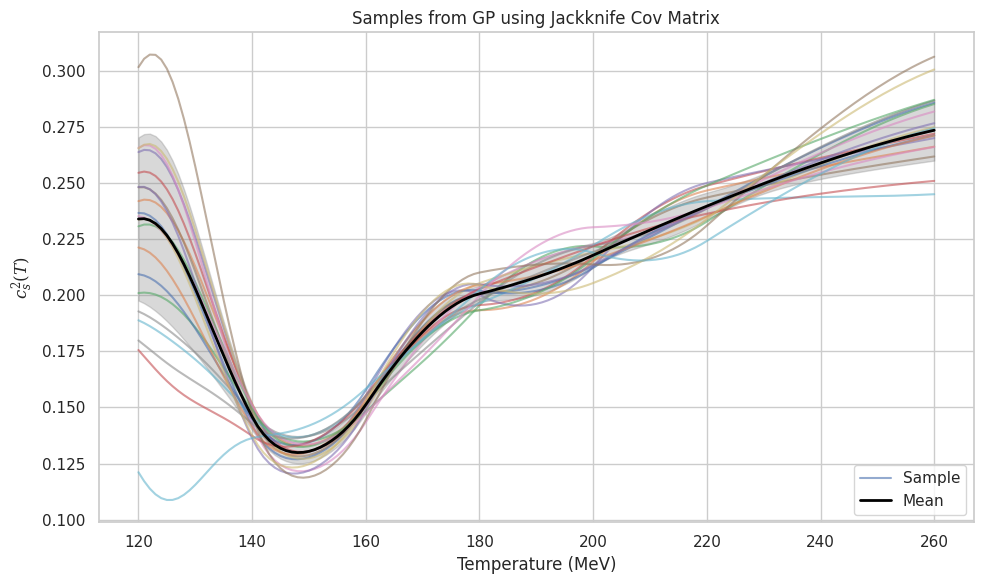

In [ ]:
n_samples = 20  # number of functions to draw
jk_cs2 = multivariate_normal(mean=jk_mean, cov=cov_matrix, size=n_samples)

plt.figure(figsize=(10, 6))
for i in range(n_samples):
    plt.plot(T, jk_cs2[i], alpha=0.6, label=f'Sample' if i == 0 else None)

# Plot the mean and uncertainty band
std_diag = np.sqrt(np.diag(cov_matrix))
plt.plot(T, jk_mean, color='black', lw=2, label='Mean')
plt.fill_between(T, jk_mean - std_diag, jk_mean + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig('./images/cs2_from_jk.png')
plt.show()

## Obtaining thermo quantities from those samples

In [ ]:
cs2_interp_jkLowT = []

for i in range(n_samples):
    
    interp_func = interp1d(
        T_stepOne,
        jk_cs2[i],
        kind="linear",
        bounds_error=False, 
        fill_value=(jk_cs2[i][0], jk_cs2[i][-1])
    )
    
    cs2_interp_jkLowT.append(interp_func)

In [ ]:

def cs2_powerlaw(T, interp):
    T = np.asarray(T)
    
    cs2_data = interp(T)
    T_max = T_stepOne[-1]
    cs2_Tmax = interp(T_max)

    A = T_max**2 * (1.0/3.0 - cs2_Tmax)
    highT_part = 1.0/3.0 - A / T**2

    return np.where(T <= T_max, cs2_data, highT_part)


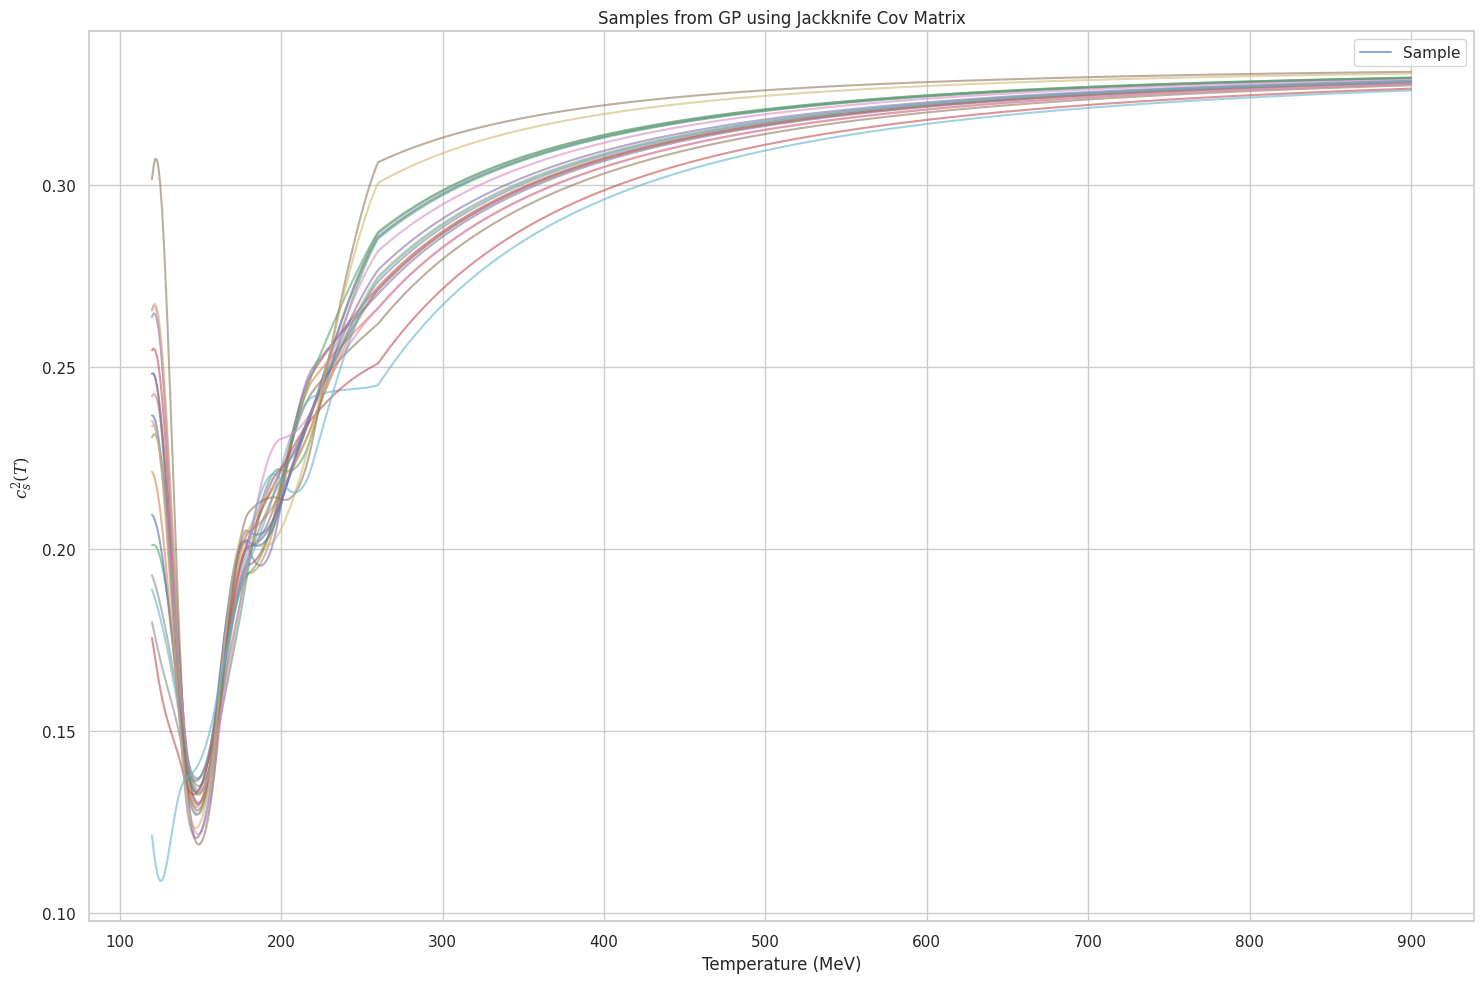

In [ ]:

for i in range(n_samples):
    plt.plot(
        T_point01_up,
        cs2_powerlaw(T_point01_up, cs2_interp_jkLowT[i]),
        alpha=0.6,
        label="Sample" if i == 0 else None
    )

# Plot the mean and uncertainty band
#std_diag = np.sqrt(np.diag(cov_matrix))
#plt.plot(T, jk_mean, color='black', lw=2, label='Mean')
#plt.fill_between(T, jk_mean - std_diag, jk_mean + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.savefig('./images/cs2_interp_jk_pwr.png')
plt.tight_layout()

plt.show()

In [ ]:
def cs2_interp_tanh(T, interp, T0=500.0, delta=70.0):
    T = np.asarray(T)
    w = 0.5 * (1 + np.tanh((T - T0) / delta))
    return (1 - w) * interp(T) + w * (1.0 / 3.0)

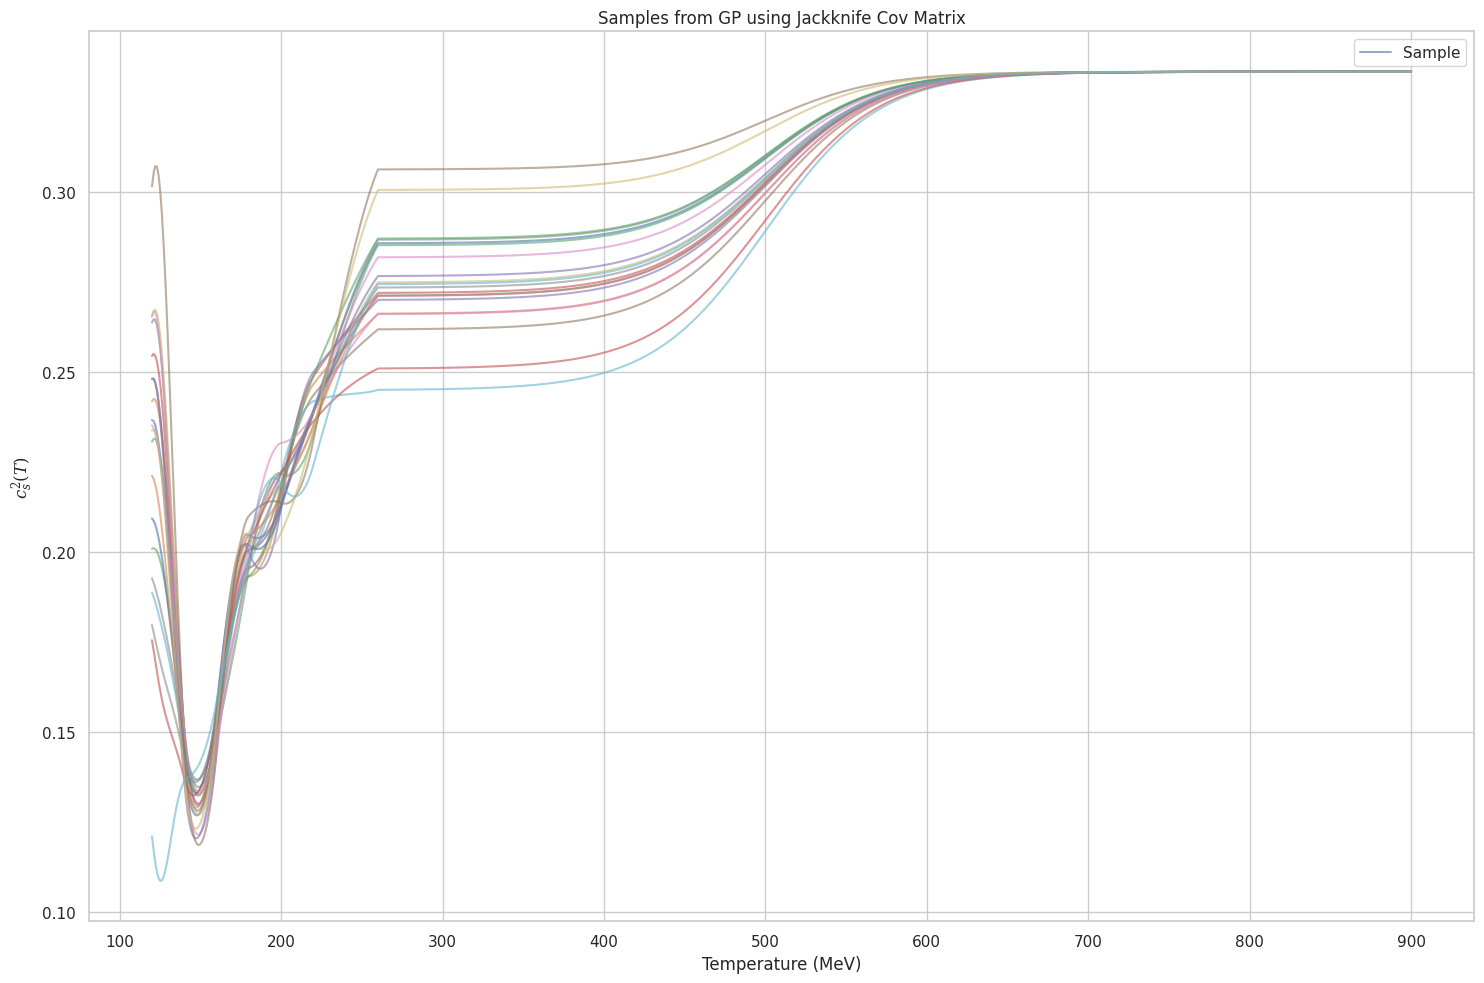

In [ ]:

for i in range(n_samples):
    plt.plot(
        T_point01_up,
        cs2_interp_tanh(T_point01_up, cs2_interp_jkLowT[i]),
        alpha=0.6,
        label="Sample" if i == 0 else None
    )

# Plot the mean and uncertainty band
#std_diag = np.sqrt(np.diag(cov_matrix))
#plt.plot(T, jk_mean, color='black', lw=2, label='Mean')
#plt.fill_between(T, jk_mean - std_diag, jk_mean + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.savefig('./images/cs2_interp_jk_tanh.png')
plt.tight_layout()

plt.show()

In [ ]:
s_up_interp_jk = entropy_up(s_sw, T_sw, cs2_interp_tanh(T_point01_up, cs2_interp_jkLowT[0]), T_point01_up)
P_up_vec_jk = pressure_up(P_sw, T_sw, T_point01_up, s_up_interp_jk)
P_up_interp_jk = interp1d(T_point01_up, P_up_vec_jk, kind='linear', fill_value=(P_up_vec_jk[0], P_up_vec_jk[-1]))   

In [ ]:
def energy_up_jk(s, P, T_vec):
    energy_vec = []
    for T in T_vec:
        energy_vec.append(s(T)*T - P(T))
    return energy_vec

e_up_vec_jk = energy_up_jk(s_up_interp_jk, P_up_interp_jk, T_point01_up)

In [ ]:
def cs2_exp_extrap(T, interp, T0=260.0, X_inf=1.0/3.0, dT=0.5):
    """
    Exponential extrapolation of cs^2 that matches value and slope at T0.
    """

    T = np.asarray(T)

    # value at matching point
    y0 = interp(T0)

    # numerical slope at T0
    slope = (interp(T0 + dT) - interp(T0 - dT)) / (2*dT)

    delta = X_inf - y0

    # protect against division problems
    if abs(delta) < 1e-12 or abs(slope) < 1e-12:
        return np.full_like(T, X_inf)

    k = slope / delta

    result = X_inf - delta * np.exp(-k * (T - T0))

    return result

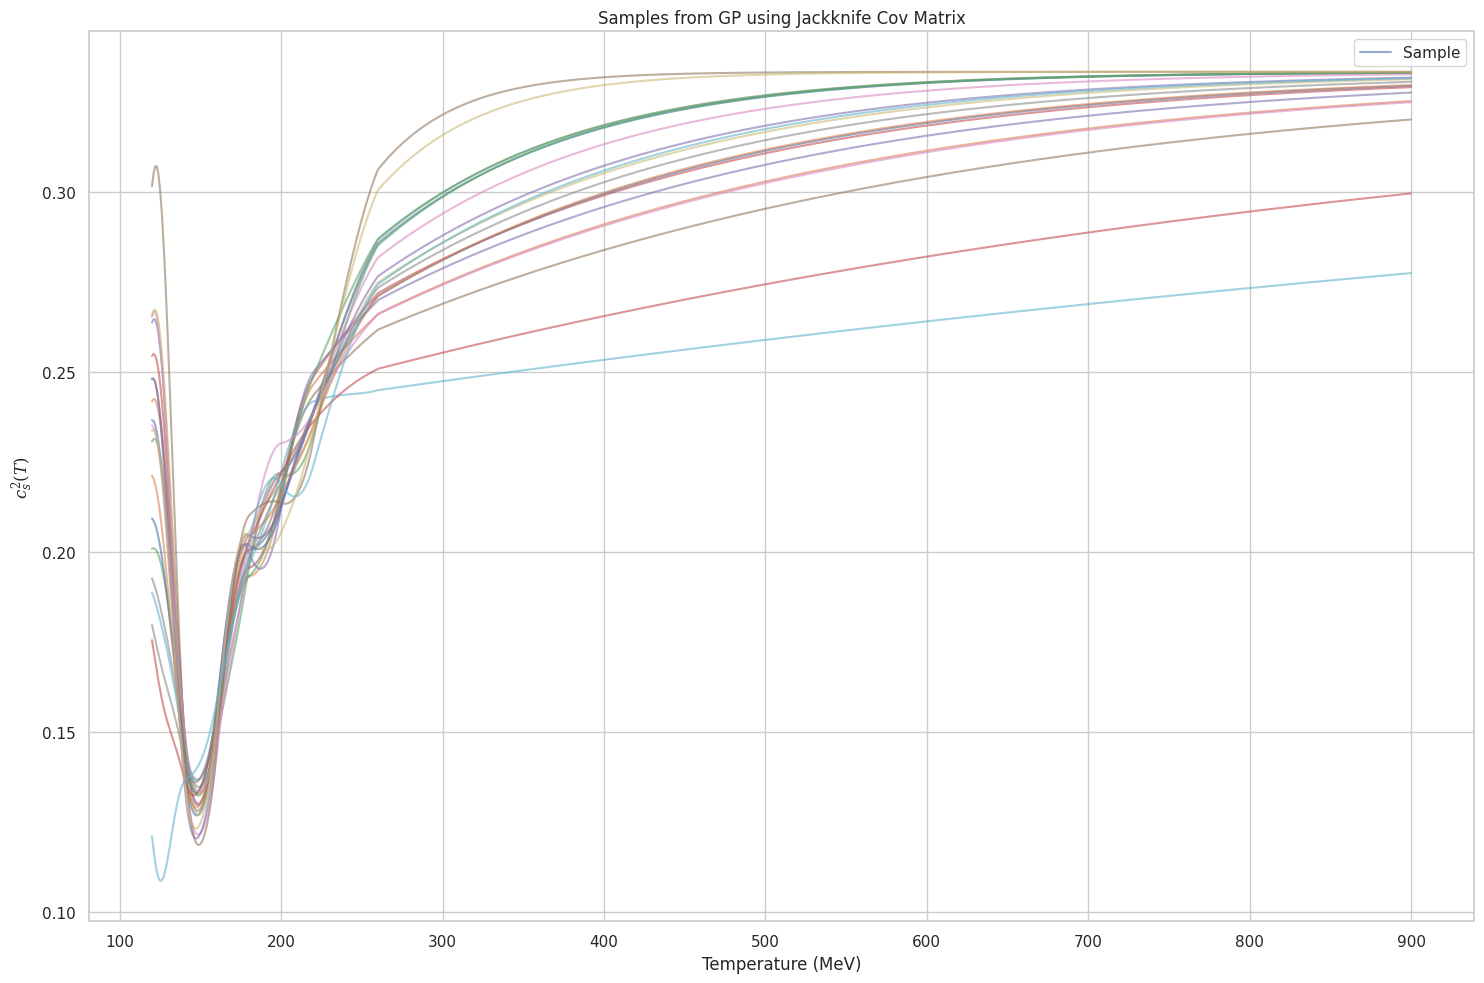

In [ ]:
""" cs2_expExtrap = np.where(
    T_point01_up <= T[-1],
    cs2_interp_jk(T_point01_up, cs2_interp_jkLowT[0]),
    cs2_exp_extrap(T_point01_up, cs2_interp_jkLowT[0], T[-1])
) """

for i in range(n_samples):

    cs2_expExtrap = np.where(
        T_point01_up <= T[-1],
        cs2_interp_jkLowT[i](T_point01_up),
        cs2_exp_extrap(T_point01_up, cs2_interp_jkLowT[i], T0=T[-1])
    )

    plt.plot(
        T_point01_up,
        cs2_expExtrap,
        alpha=0.6,
        label="Sample" if i == 0 else None
    )

# Plot the mean and uncertainty band
#std_diag = np.sqrt(np.diag(cov_matrix))
#plt.fill_between(T, jk_mean - std_diag, jk_mean + std_diag, color='gray', alpha=0.3)

plt.xlabel('Temperature (MeV)')
plt.ylabel('$c_s^2(T)$')
plt.title('Samples from GP using Jackknife Cov Matrix')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig('./images/cs2_interp_jk_expExtrap.png')

plt.show()

### Downwards extrap as HRG below 150 MeV

In [ ]:
P_total_150_jk = np.concatenate([P_hrg_total, P_up_vec_jk[idx_Tsw_up:]])
e_total_150_jk = np.concatenate([e_hrg_total, e_up_vec_jk[idx_Tsw_up:]])
s_total_150_jk = np.concatenate([s_hrg_total, s_up_interp_jk(T_point01_up[idx_Tsw_up:])])
 
p_hrg_interp_jk = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), P_total_150_jk, kind='linear')
e_hrg_interp_jk = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), e_total_150_jk, kind='linear')
s_hrg_interp_jk = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), s_total_150_jk, kind='linear')

/tmp/ipykernel_5441/4198462306.py:10: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


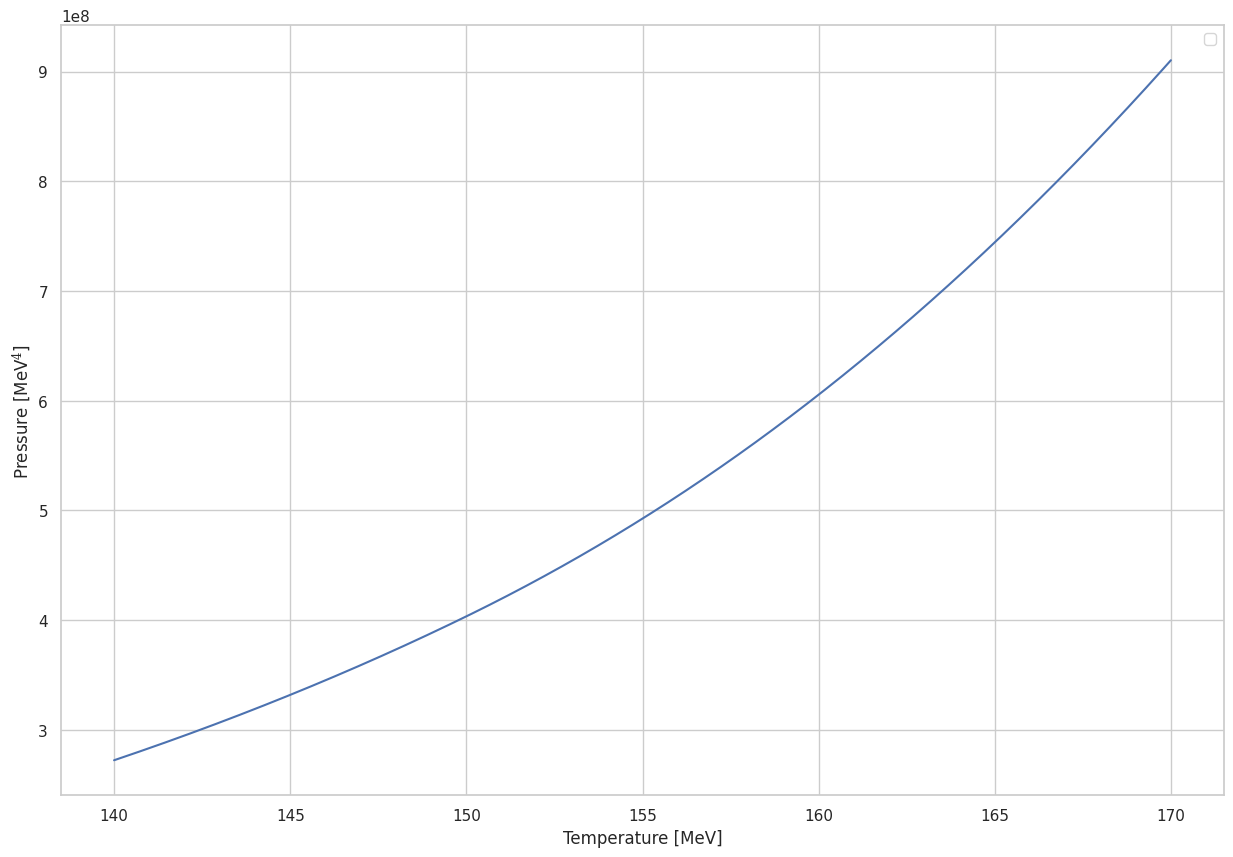

In [ ]:
df = pd.DataFrame({'T': T_total[idx_140:idx_170], 'pressure': p_hrg_interp_jk(T_total[idx_140:idx_170])})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='pressure')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('Pressure [MeV$^4$]')
plt.legend()
plt.savefig('./images/p_jk_trans.png')
plt.show()

In [ ]:
""" #cs2 

cs2_150disc_jk = np.concatenate([cs2_hrg_Tswdisc, cs2_expExtrap])
    #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)
cs2_150_jk_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), cs2_150disc_jk, kind='linear')

df = pd.DataFrame({'T': T_total, 'cs2':cs2_150_jk_interp(T_total)})

sns.set(style="whitegrid")
#sns.lineplot(data=df, x='T', y='energy', label='Energy')
sns.lineplot(data=df, x='T', y='cs2')
#sns.lineplot(data=df, x='T', y='sT', label='sT')

plt.xlabel('Temperature [MeV]')
plt.ylabel('cs2')
plt.legend()
#plt.savefig('./images/cs2_unc_hrg_150.png')
plt.show() """



' #cs2 \n\ncs2_150disc_jk = np.concatenate([cs2_hrg_Tswdisc, cs2_expExtrap])\n    #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)\ncs2_150_jk_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[idx_Tsw_up:]]), cs2_150disc_jk, kind=\'linear\')\n\ndf = pd.DataFrame({\'T\': T_total, \'cs2\':cs2_150_jk_interp(T_total)})\n\nsns.set(style="whitegrid")\n#sns.lineplot(data=df, x=\'T\', y=\'energy\', label=\'Energy\')\nsns.lineplot(data=df, x=\'T\', y=\'cs2\')\n#sns.lineplot(data=df, x=\'T\', y=\'sT\', label=\'sT\')\n\nplt.xlabel(\'Temperature [MeV]\')\nplt.ylabel(\'cs2\')\nplt.legend()\n#plt.savefig(\'./images/cs2_unc_hrg_150.png\')\nplt.show() '

### Saving to a file

In [ ]:
def save_jk_gp_files(i, m, cs2_interp=None):
    cs2_interp_jk_file = cs2_interp

    s_up_jk_file = entropy_up(s_sw, T_sw, cs2_interp_jk_file, T_point01_up)
    P_up_jk_file = pressure_up(P_sw, T_sw, T_point01_up, s_up_jk_file)
    P_up_jk_interp_file = interp1d(T_point01_up, P_up_jk_file, kind='linear', fill_value="extrapolate")   
    e_up_jk_file = s_up_jk_file(T_point01_up) * T_point01_up - P_up_jk_interp_file(T_point01_up)

    #hrg to 150 vectors
    pressure_hrg_jk_file = np.concatenate([P_hrg_total, P_up_jk_file[idx_Tsw_up:]])
    energy_hrg_jk_file = np.concatenate([e_hrg_total, e_up_jk_file[idx_Tsw_up:]])
    entropy_hrg_jk_file = np.concatenate([s_hrg_total, s_up_jk_file(T_point01_up[idx_Tsw_up:])])
    cs2_150disc_jk_file = np.concatenate([cs2_hrg_Tswdisc, cs2_interp_jk_file(T_point01_up[idx_Tsw_up:])])
    #interpolations (T_point001_150 + T_point01_up[3001:] is different from T_total)
    cs2_150_jk_interp = interp1d(np.concatenate([T_total[:idx_150],T_point01_up[3001:] ]), cs2_150disc_jk_file, kind='linear')
    pressure_hrg_jk_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), pressure_hrg_jk_file, kind='linear')
    energy_hrg_jk_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), energy_hrg_jk_file, kind='linear')
    entropy_hrg_jk_interp = interp1d(np.concatenate([T_total[:idx_150], T_point01_up[3001:]]), entropy_hrg_jk_file, kind='linear')

    with open(f"./data_files/jk_samples/eos_jk_run{m}_s{i}.dat", "w") as f:
        f.write(f"{len(energy_hrg_jk_interp(T_total))}\n")
        for e, T, p, cs2, s in zip(energy_hrg_jk_interp(T_total), T_total, pressure_hrg_jk_interp(T_total), cs2_150_jk_interp(T_total), entropy_hrg_jk_interp(T_total)):
            f.write(f"{e*MeV4_to_GeV_fm3} {T*MeV_to_GeV} {p*MeV4_to_GeV_fm3} {cs2} {s*(1/hbarc**3)}\n")


In [ ]:
#changes distribution, every time this is run, change m to inidicate different set

jk_cs2 = multivariate_normal(mean=jk_mean, cov=cov_matrix, size=n_samples)

cs2_interp_jk = []

m = 1

In [ ]:

for i in range(n_samples):
    cs2_extended = np.concatenate([jk_cs2[i], np.array([1/3])])
    
    interp_func = interp1d(
        T_interpolate_jk,
        cs2_extended,
        kind="linear",
        fill_value="extrapolate"
    )
    
    cs2_interp_jk.append(interp_func)

for i in range(0, 3):
    save_jk_gp_files(i, m, cs2_interp=cs2_interp_jk[i])

NameError: name 'T_interpolate_jk' is not defined

## PCA

In [467]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [684]:
N = 500
samples_cs2_GP = []
samples_cs2_interp = []
samples_s = []
samples_P = []
samples_e = []

for _ in range(N):
    cs2_GP = generate_sample(400, 10)
    cs2_interp_sample = interp1d(T_stepOne_total, cs2_GP) 

    s_up_sample = entropy_up(s_sw, T_sw, cs2_interp_sample(T_point01_up), T_point01_up)
    s_up_sample_interp = interp1d(T_point01_up, s_up_sample(T_point01_up), kind='linear', fill_value="extrapolate")
    P_up_sample = pressure_up(P_sw, T_sw, T_point01_up, s_up_sample)
    P_up_interp_sample = interp1d(T_point01_up, P_up_sample, kind='linear')
    e_up_sample = s_up_sample(T_point01_up)*T_point01_up - P_up_interp_sample(T_point01_up)
    
    samples_cs2_GP.append(cs2_GP)
    samples_cs2_interp.append(cs2_interp_sample(T_point01_up))
    samples_s.append(s_up_sample_interp(T_point01_up))
    samples_P.append(P_up_sample)
    samples_e.append(e_up_sample)
    #print(f"Generated sample {_+1}/{N}")

samples_cs2_GP = np.array(samples_cs2_GP)
samples_cs2_interp = np.array(samples_cs2_interp)
samples_s = np.array(samples_s)
samples_P = np.array(samples_P)
samples_e = np.array(samples_e)

In [527]:
print(samples_cs2_GP.shape)
print(samples_cs2_GP)

(500, 781)
[[0.11024764 0.10577829 0.10167681 ... 0.38384084 0.3888952  0.39282586]
 [0.12339454 0.12113894 0.11998661 ... 0.31616116 0.31623256 0.31792592]
 [0.3471245  0.34870794 0.34659499 ... 0.35078798 0.35147935 0.3546021 ]
 ...
 [0.18185821 0.17593394 0.17134037 ... 0.32184006 0.3177726  0.31362189]
 [0.380598   0.37950319 0.3760593  ... 0.39270293 0.3659538  0.3394773 ]
 [0.18109083 0.19596897 0.21181714 ... 0.12745539 0.13584934 0.14581761]]


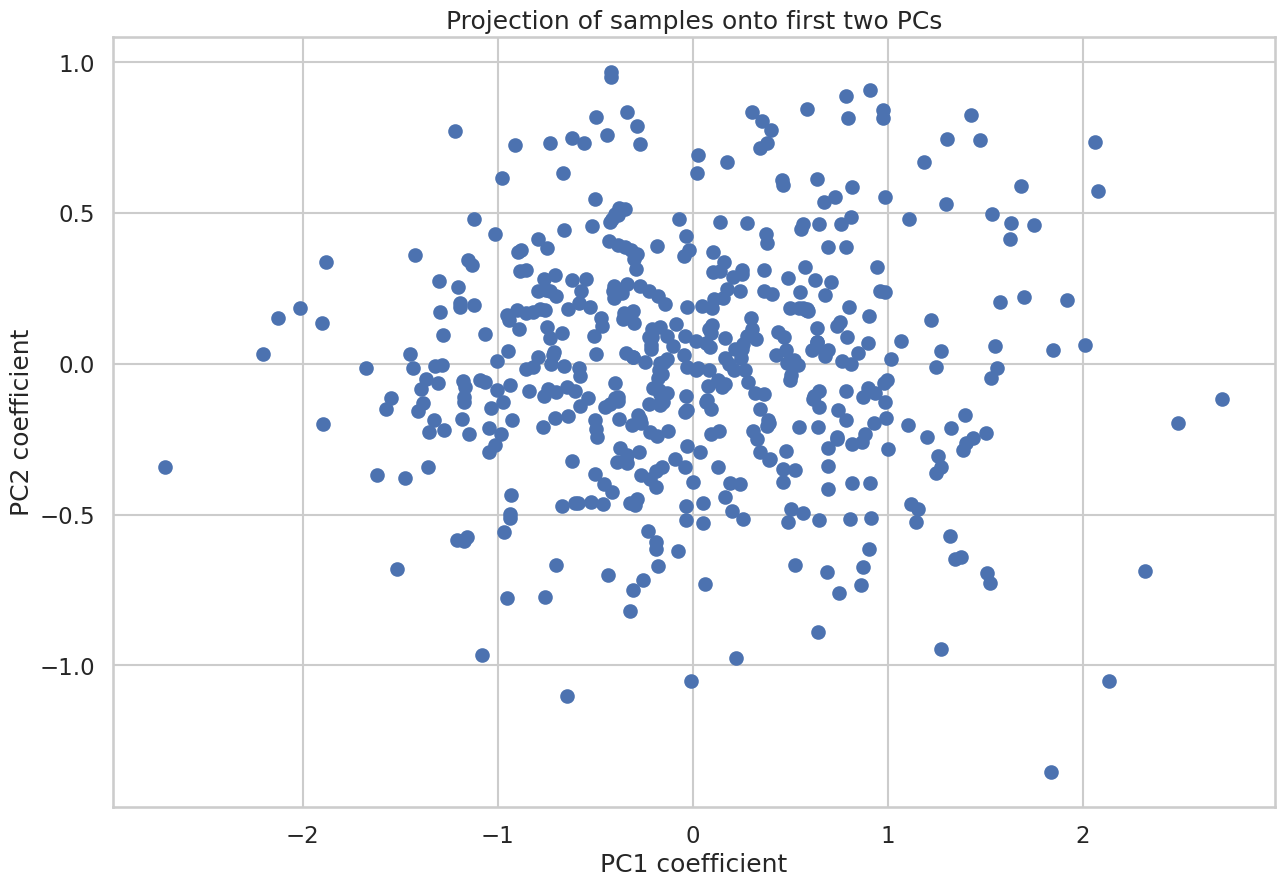

In [685]:
pca = PCA() 
#already subtracted mean, so no need to center again
#n_components not set so all components are kept

coeff = pca.fit_transform(samples_cs2_GP) #learns pca basis and projects data onto it

PCs = pca.components_ #eigenvectors
eigenvals = pca.explained_variance_ #the amount of variance explained by each of the selected components (eigenvalues)

var_fraction = pca.explained_variance_ratio_

plt.scatter(coeff[:,0], coeff[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs")
plt.savefig("./images/pca_projection_cs2.png")
plt.show()

In [686]:
for j in range(len(PCs)):
    for k in range(len(PCs)):
        dot = np.dot(PCs[j], PCs[k])
        if j == k:
            print(f"{j},{k} (norm):", dot)
        else:
            if abs(dot) > 1e-10:
                print(f"{j},{k} (dot):", dot)

0,0 (norm): 0.9999999999999998
1,1 (norm): 1.000000000000001
2,2 (norm): 1.0000000000000004
3,3 (norm): 0.9999999999999998
4,4 (norm): 0.9999999999999999
5,5 (norm): 1.0000000000000007
6,6 (norm): 1.0000000000000009
7,7 (norm): 1.0
8,8 (norm): 1.0000000000000004
9,9 (norm): 1.0000000000000004
10,10 (norm): 1.0000000000000007
11,11 (norm): 0.9999999999999996
12,12 (norm): 1.0
13,13 (norm): 1.0000000000000004
14,14 (norm): 1.0000000000000004
15,15 (norm): 1.0000000000000004
16,16 (norm): 1.0000000000000002
17,17 (norm): 1.0000000000000004
18,18 (norm): 1.0000000000000007
19,19 (norm): 0.9999999999999993
20,20 (norm): 1.0
21,21 (norm): 1.0000000000000004
22,22 (norm): 1.0000000000000007
23,23 (norm): 0.9999999999999998
24,24 (norm): 0.9999999999999999
25,25 (norm): 1.0000000000000004
26,26 (norm): 0.9999999999999996
27,27 (norm): 1.0000000000000004
28,28 (norm): 1.0
29,29 (norm): 0.9999999999999991
30,30 (norm): 0.9999999999999993
31,31 (norm): 0.9999999999999991
32,32 (norm): 0.999999999

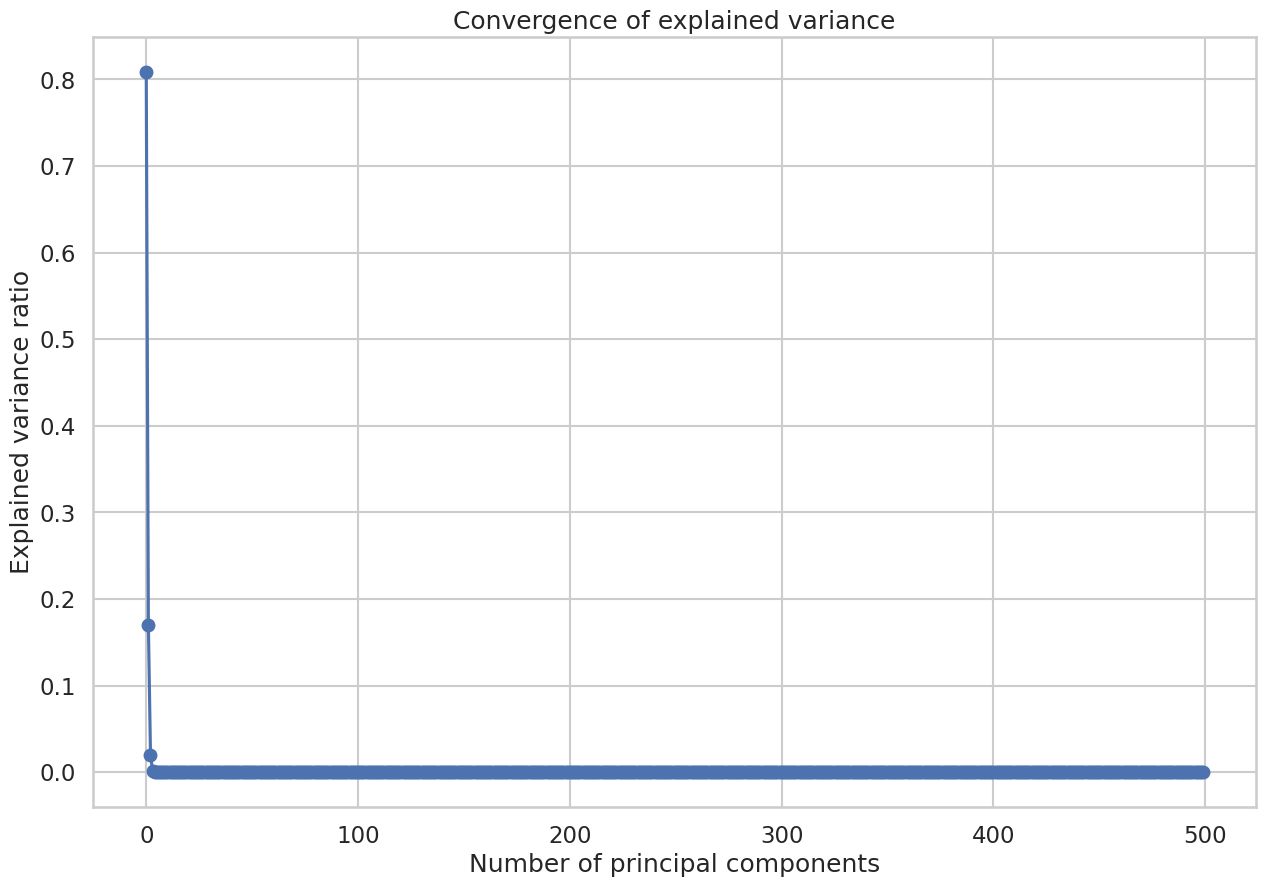

In [687]:
plt.plot(var_fraction, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("Convergence of explained variance")
plt.savefig("./images/pca_explained_variance_cs2_l100.png")
plt.show()

/tmp/ipykernel_5441/4111971457.py:7: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


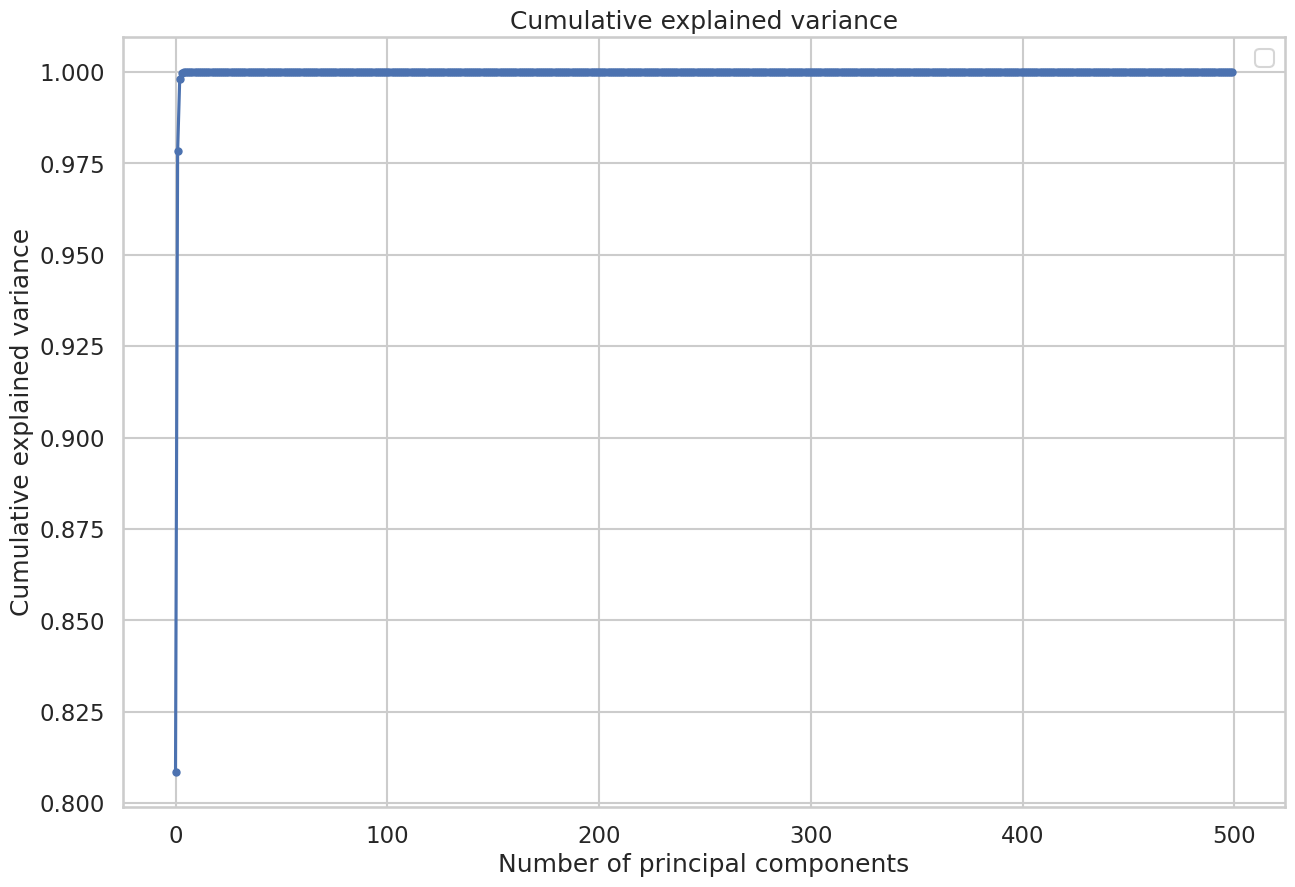

In [688]:
#cumulative variance
cumulative_variance = np.cumsum(var_fraction)
plt.plot(cumulative_variance, marker='o', markersize=5)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.legend()
plt.savefig("./images/pca_cumulative_variance_cs2_l100.png")
plt.show()

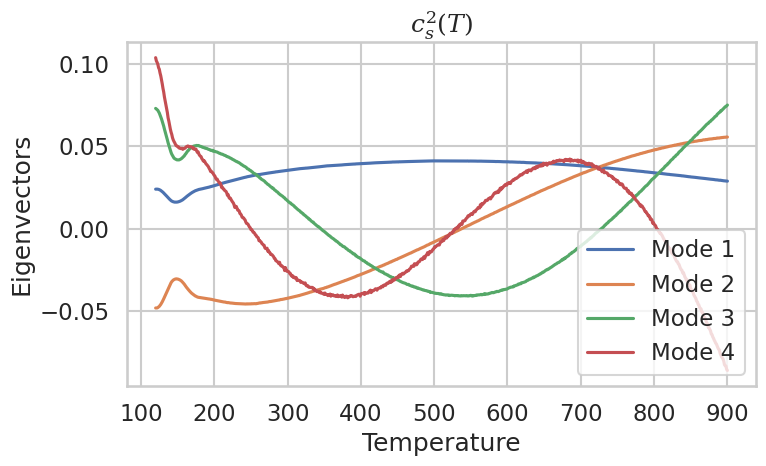

In [689]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_stepOne_total[::], PCs[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvectors")
plt.title("$c_s^2(T)$")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_cs2.png")
plt.show()

Max abs diff: 1.1102230246251565e-16
All close: True


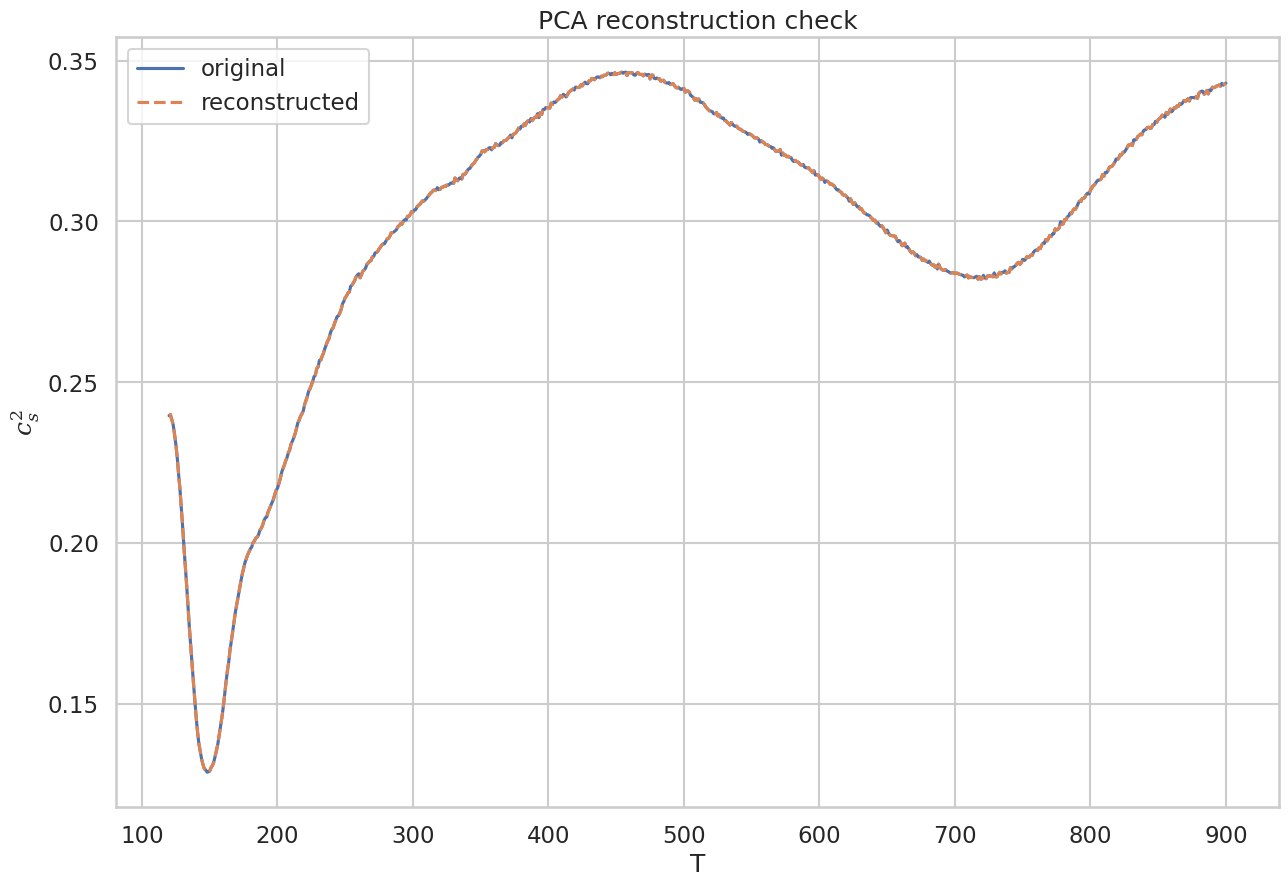

In [577]:
i = 0

original = samples_cs2_GP[i]
reconstructed = pca.inverse_transform(coeff)[i]

print("Max abs diff:", np.max(np.abs(original - reconstructed)))
print("All close:", np.allclose(original, reconstructed))

plt.plot(T_stepOne_total, original, label="original")
plt.plot(T_stepOne_total, reconstructed, "--", label="reconstructed")

plt.xlabel("T")
plt.ylabel("$c_s^2$")
plt.title("PCA reconstruction check")
plt.legend()
plt.show()

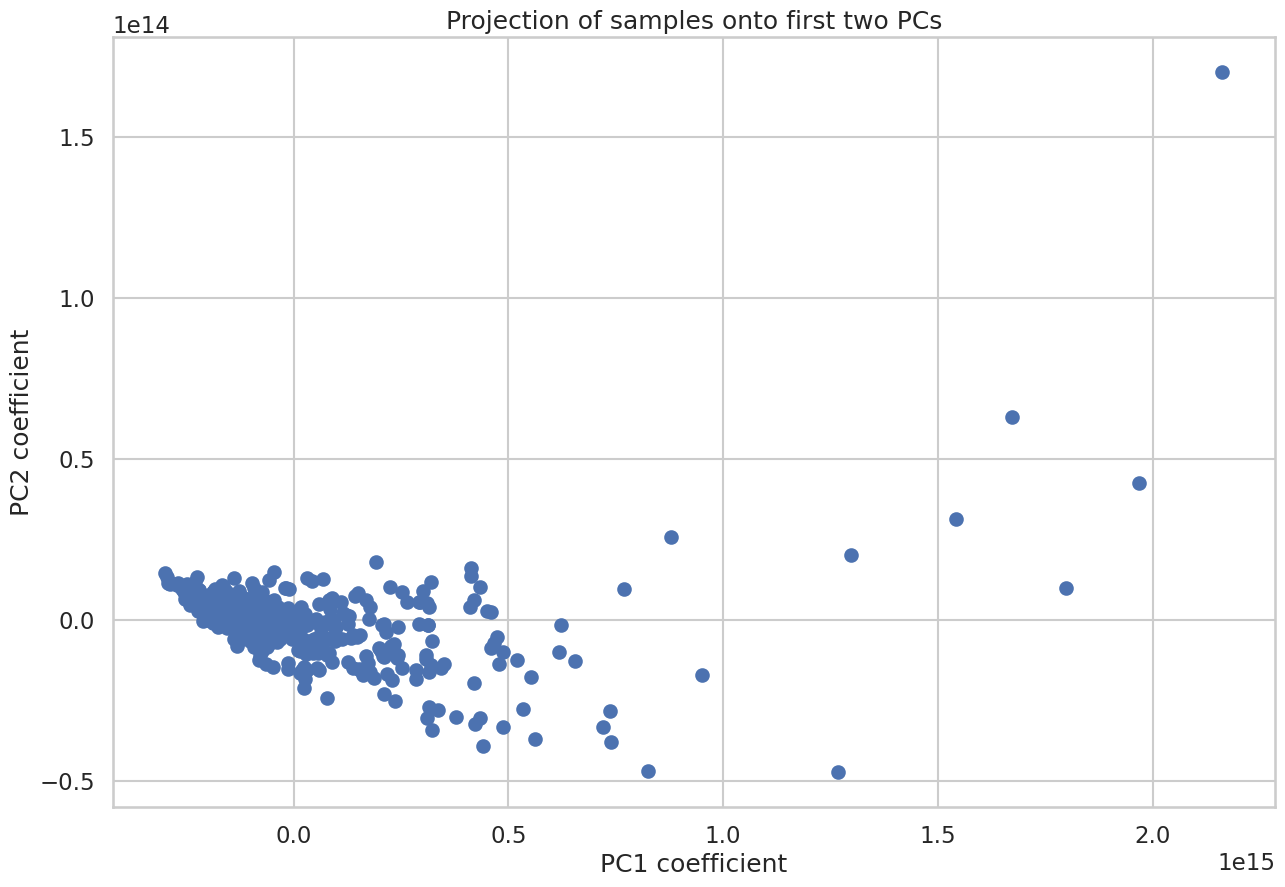

In [690]:
#Pressure

samples_P = samples_P[:, ::]
pca_P = PCA() 
#already subtracted mean, so no need to center again
#n_components is not set: all components are kept

coeff_P = pca_P.fit_transform(samples_P) #learns pca basis and projects data onto it

PCs_P = pca_P.components_
eigenvals_P = pca_P.explained_variance_
var_fraction_P = pca_P.explained_variance_ratio_

plt.scatter(coeff_P[:,0], coeff_P[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs")
plt.savefig("./images/pca_projection_P.png")
plt.show()

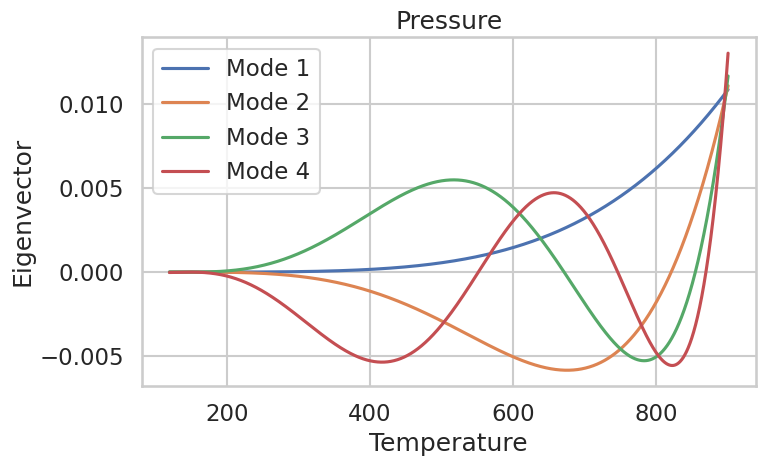

In [691]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_point01_up[::], PCs_P[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvector")
plt.title("Pressure")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_P.png")
plt.show()

In [639]:
for j in range(len(PCs_P)):
    for k in range(len(PCs_P)):
        dot = np.dot(PCs_P[j], PCs_P[k])
        if j == k:
            print(f"{j},{k} (norm):", dot)
        else:
            if abs(dot) > 1e-10:
                print(f"{j},{k} (dot):", dot)

0,0 (norm): 1.0000000000000009
1,1 (norm): 1.000000000000001
2,2 (norm): 0.9999999999999998
3,3 (norm): 0.9999999999999996
4,4 (norm): 1.0000000000000029
5,5 (norm): 1.000000000000001
6,6 (norm): 0.9999999999999999
7,7 (norm): 1.0000000000000018
8,8 (norm): 0.9999999999999993
9,9 (norm): 0.999999999999999
10,10 (norm): 1.000000000000001
11,11 (norm): 0.999999999999999
12,12 (norm): 0.9999999999999996
13,13 (norm): 1.000000000000001
14,14 (norm): 1.0000000000000013
15,15 (norm): 1.0000000000000009
16,16 (norm): 1.0000000000000018
17,17 (norm): 1.0000000000000009
18,18 (norm): 1.0000000000000009
19,19 (norm): 0.9999999999999998
20,20 (norm): 1.0000000000000004
21,21 (norm): 0.9999999999999996
22,22 (norm): 0.9999999999999991
23,23 (norm): 1.0000000000000004
24,24 (norm): 0.9999999999999998
25,25 (norm): 0.9999999999999989
26,26 (norm): 0.9999999999999997
27,27 (norm): 1.0000000000000002
28,28 (norm): 1.0000000000000002
29,29 (norm): 0.9999999999999991
30,30 (norm): 0.9999999999999979
31,

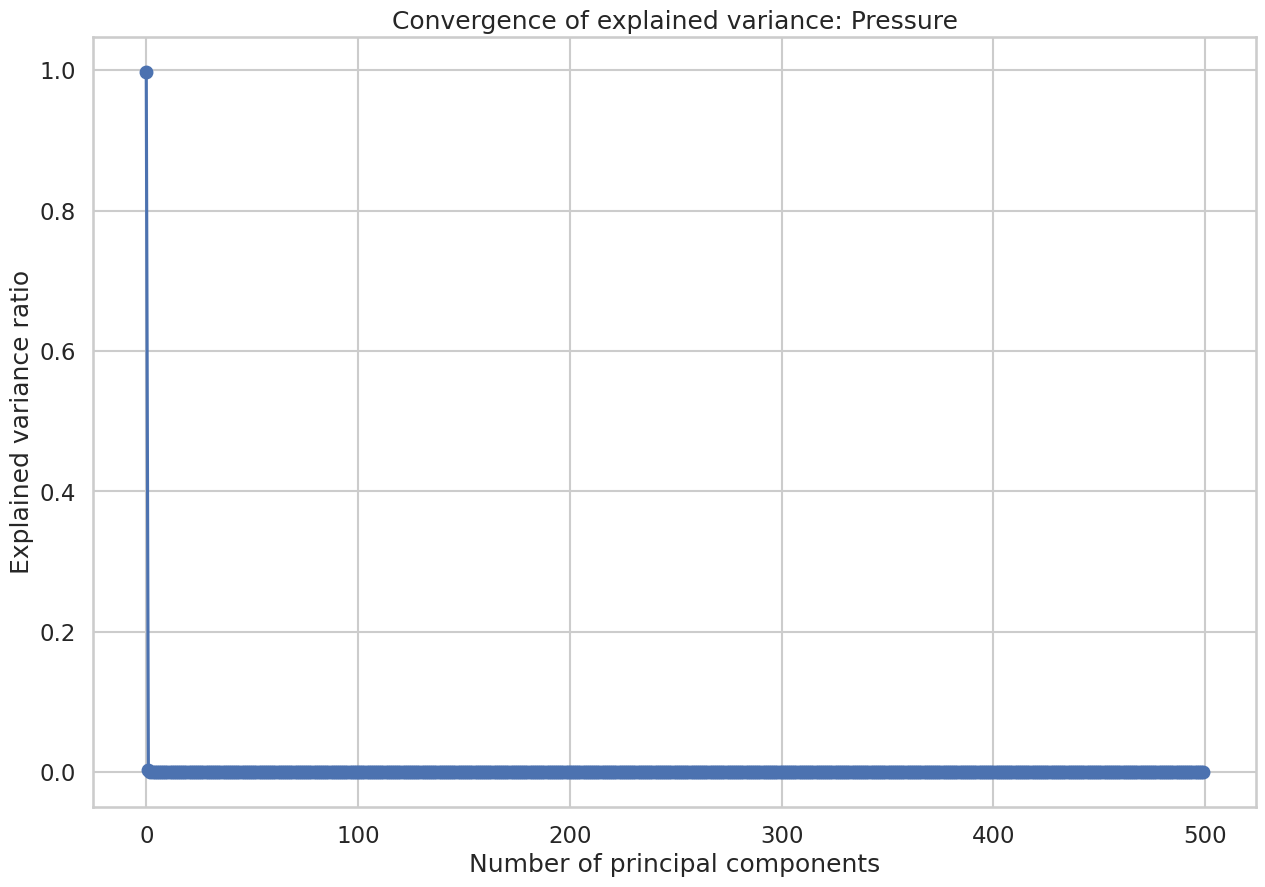

In [579]:
plt.plot(var_fraction_P, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("Convergence of explained variance: Pressure")
plt.savefig("./images/pca_explained_variance_P.png")
plt.show()

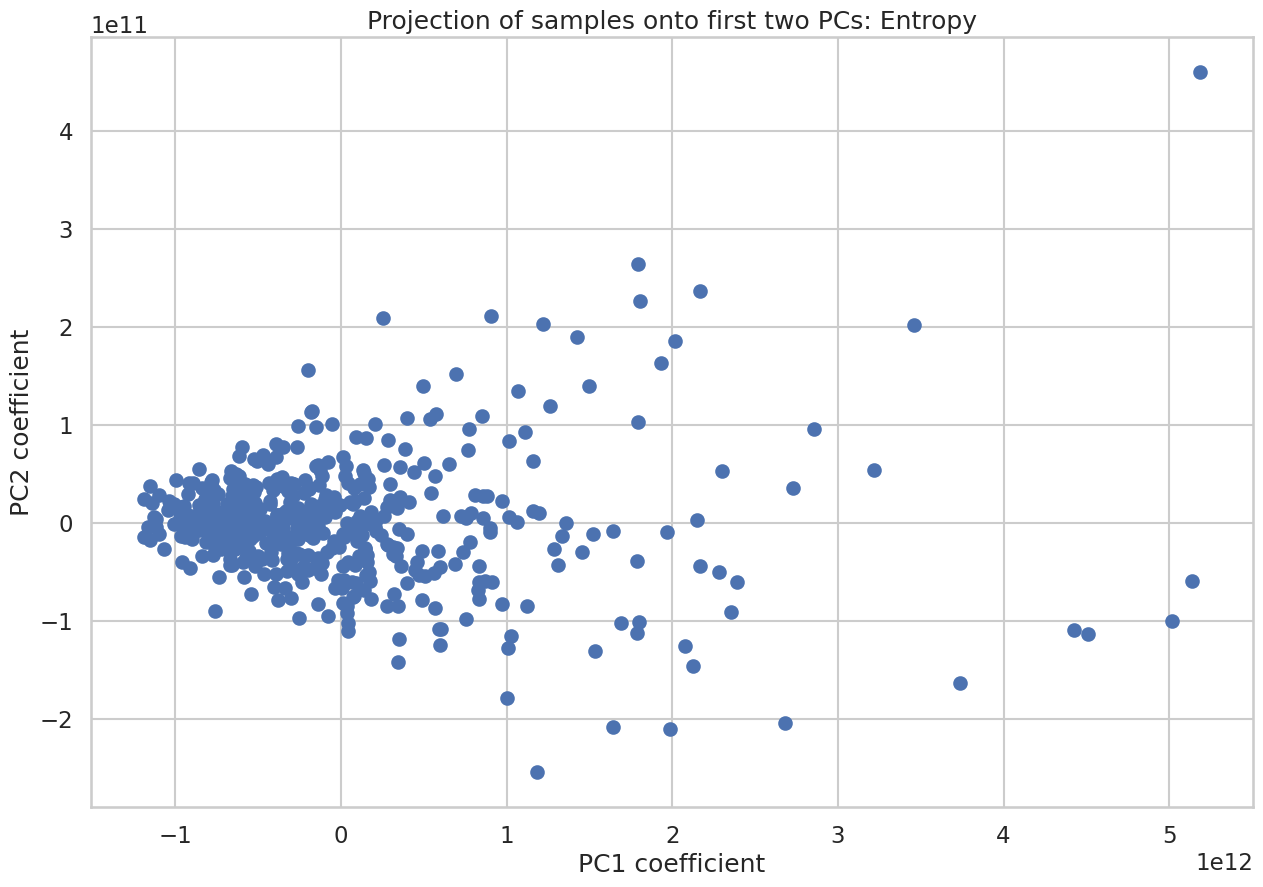

In [580]:
#entropy

pca_s = PCA()
coeff_s = pca_s.fit_transform(samples_s)
PCs_s = pca_s.components_
eigvals_s = pca_s.explained_variance_
var_fraction_s = pca_s.explained_variance_ratio_

plt.scatter(coeff_s[:,0], coeff_s[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs: Entropy")
plt.savefig("./images/pca_projection_s.png")
plt.show()

In [638]:
for j in range(len(PCs_s)):
    for k in range(len(PCs_s)):
        dot = np.dot(PCs_s[j], PCs_s[k])
        if j == k:
            print(f"{j},{k} (norm):", dot)
        else:
            if abs(dot) > 1e-10:
                print(f"{j},{k} (dot):", dot)

0,0 (norm): 1.0
1,1 (norm): 1.0
2,2 (norm): 0.9999999999999999
3,3 (norm): 1.000000000000001
4,4 (norm): 0.9999999999999999
5,5 (norm): 1.0000000000000013
6,6 (norm): 1.0000000000000016
7,7 (norm): 0.9999999999999986
8,8 (norm): 0.9999999999999989
9,9 (norm): 1.0000000000000004
10,10 (norm): 0.9999999999999991
11,11 (norm): 0.9999999999999998
12,12 (norm): 1.0000000000000004
13,13 (norm): 0.9999999999999994
14,14 (norm): 0.9999999999999997
15,15 (norm): 1.0000000000000009
16,16 (norm): 1.0000000000000018
17,17 (norm): 0.9999999999999998
18,18 (norm): 0.9999999999999994
19,19 (norm): 0.9999999999999993
20,20 (norm): 0.9999999999999997
21,21 (norm): 1.0000000000000004
22,22 (norm): 1.000000000000002
23,23 (norm): 0.9999999999999984
24,24 (norm): 0.9999999999999999
25,25 (norm): 1.0000000000000004
26,26 (norm): 1.0
27,27 (norm): 1.0000000000000004
28,28 (norm): 1.0000000000000007
29,29 (norm): 0.9999999999999998
30,30 (norm): 0.9999999999999996
31,31 (norm): 0.9999999999999998
32,32 (norm

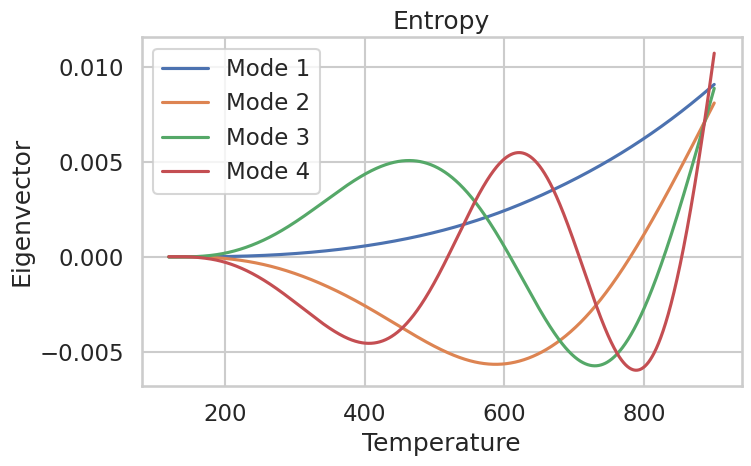

In [592]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_point01_up[::], PCs_s[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvector")
plt.title("Entropy")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_s.png")
plt.show()

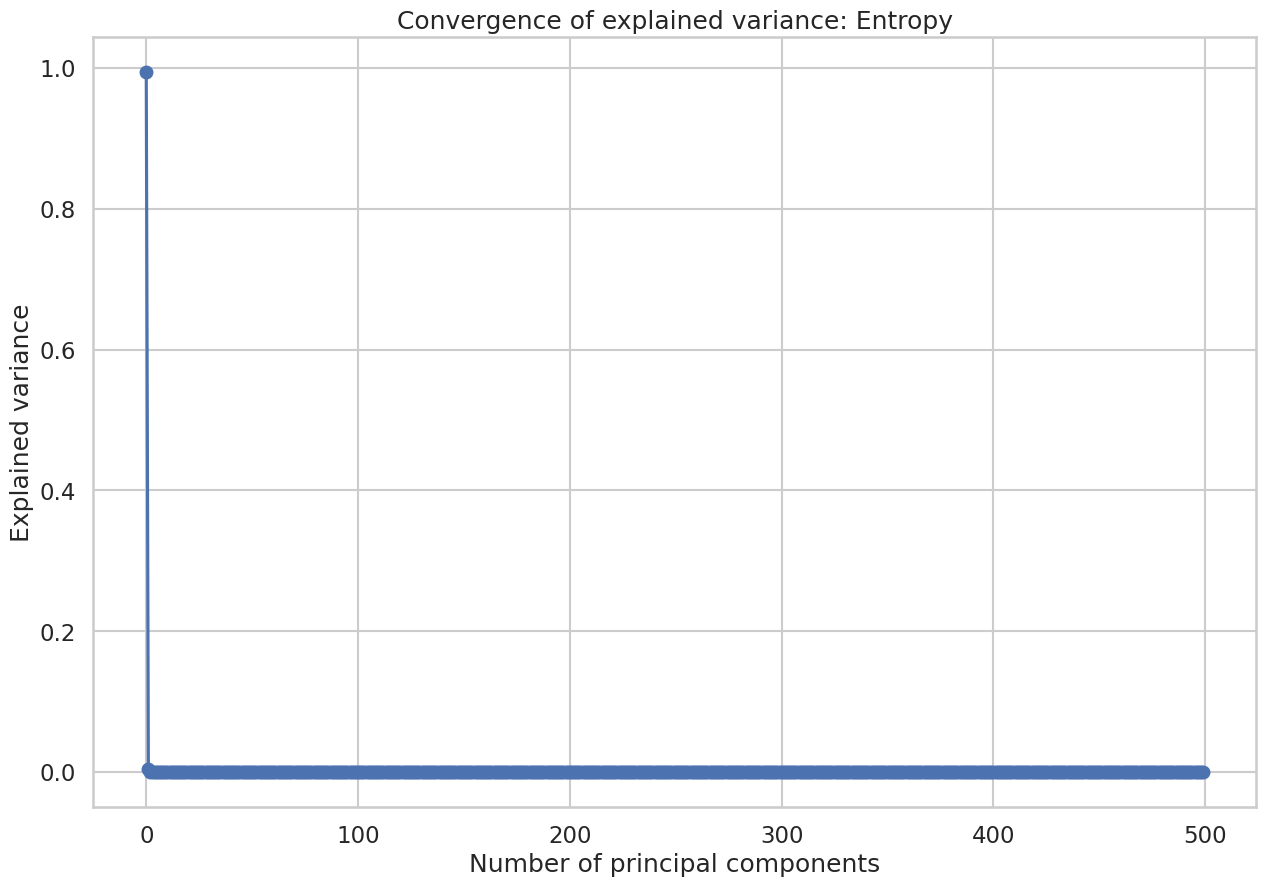

In [581]:
plt.plot(var_fraction_s, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance")
plt.title("Convergence of explained variance: Entropy")
plt.savefig("./images/pca_explained_variance_s.png")
plt.show()

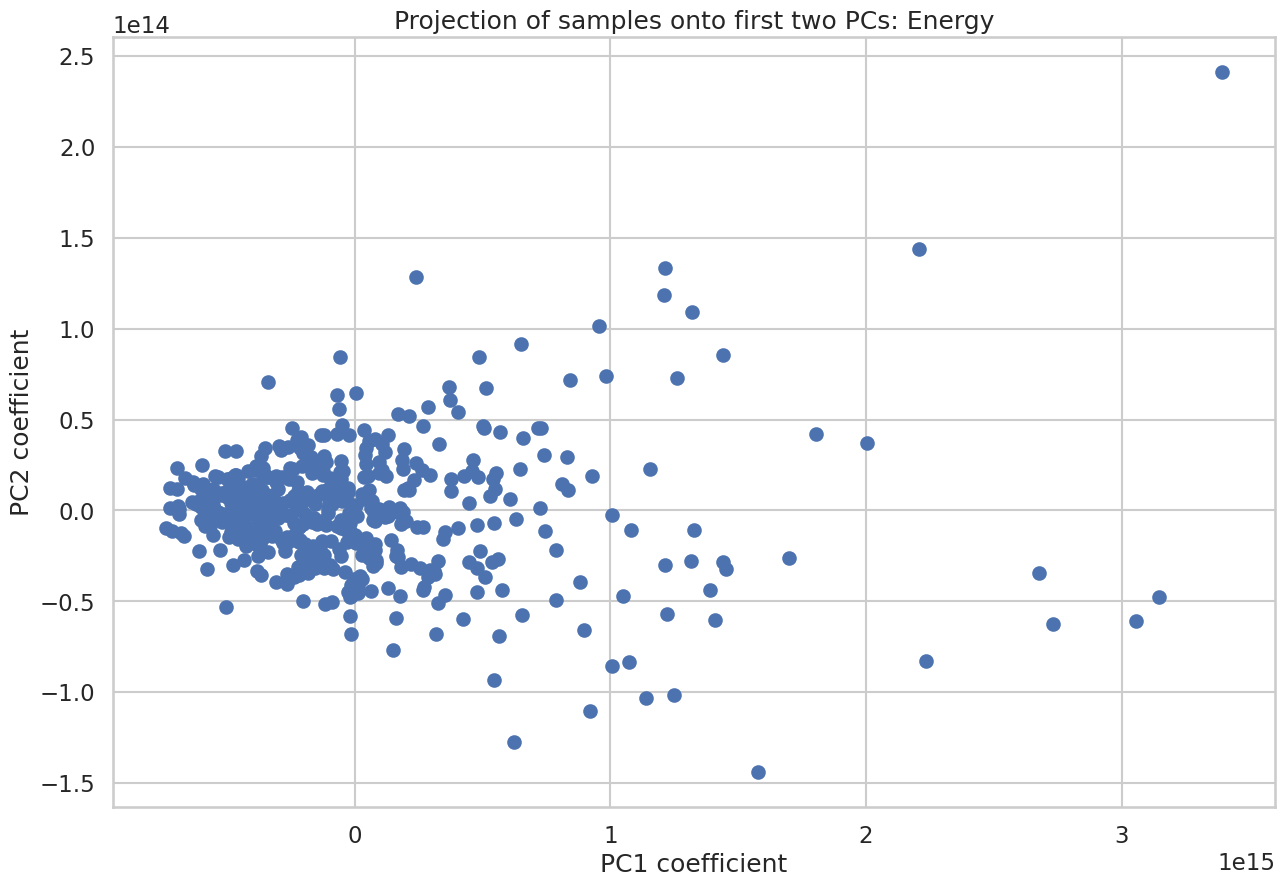

In [600]:
#energy

pca_e = PCA()
coeff_e = pca_e.fit_transform(samples_e)    
PCs_e = pca_e.components_
eigenvals_e = pca_e.explained_variance_
var_fraction_e = pca_e.explained_variance_ratio_

plt.scatter(coeff_e[:,0], coeff_e[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs: Energy")
plt.savefig("./images/pca_projection_e.png")
plt.show()

In [637]:
for j in range(len(PCs_e)):
    for k in range(len(PCs_e)):
        dot = np.dot(PCs_e[j], PCs_e[k])
        if j == k:
            print(f"{j},{k} (norm):", dot)
        else:
            if abs(dot) > 1e-10:
                print(f"{j},{k} (dot):", dot)

0,0 (norm): 1.0000000000000007
1,1 (norm): 0.9999999999999996
2,2 (norm): 1.0000000000000009
3,3 (norm): 0.9999999999999998
4,4 (norm): 0.9999999999999999
5,5 (norm): 1.0000000000000013
6,6 (norm): 0.9999999999999999
7,7 (norm): 0.9999999999999987
8,8 (norm): 1.0000000000000002
9,9 (norm): 0.9999999999999986
10,10 (norm): 0.9999999999999987
11,11 (norm): 0.9999999999999988
12,12 (norm): 0.9999999999999979
13,13 (norm): 1.0000000000000004
14,14 (norm): 0.9999999999999989
15,15 (norm): 0.9999999999999997
16,16 (norm): 0.9999999999999987
17,17 (norm): 0.9999999999999996
18,18 (norm): 1.0000000000000002
19,19 (norm): 1.0
20,20 (norm): 0.9999999999999993
21,21 (norm): 1.0
22,22 (norm): 1.0000000000000007
23,23 (norm): 0.9999999999999993
24,24 (norm): 1.000000000000001
25,25 (norm): 0.9999999999999998
26,26 (norm): 0.9999999999999996
27,27 (norm): 1.0
28,28 (norm): 0.9999999999999994
29,29 (norm): 1.0
30,30 (norm): 1.000000000000001
31,31 (norm): 1.0000000000000009
32,32 (norm): 1.0000000000

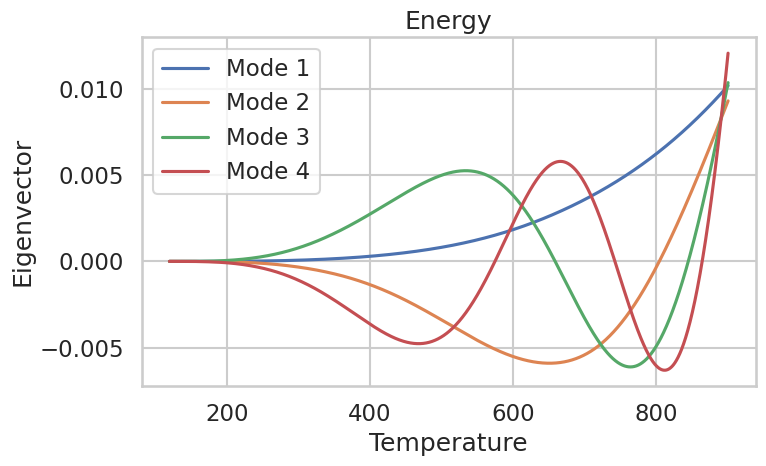

In [596]:
plt.figure(figsize=(8,5))

for k in range(4):
    plt.plot(T_point01_up[::], PCs_e[k], label=f"Mode {k+1}")

plt.xlabel("Temperature")
plt.ylabel("Eigenvector")
plt.title("Energy")
plt.legend()
plt.tight_layout()
plt.savefig("./images/pca_eigenfunctions_e.png")
plt.show()

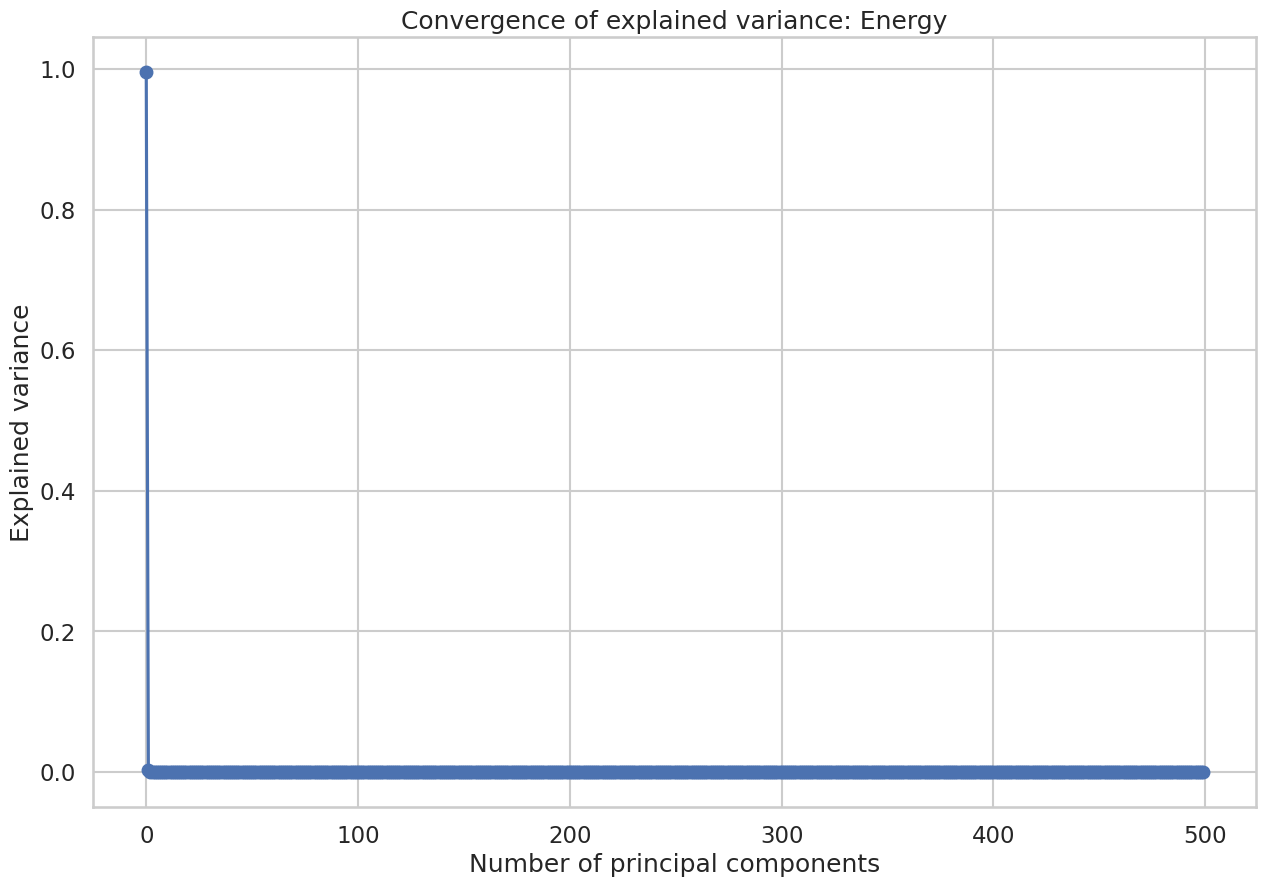

In [583]:
plt.plot(var_fraction_e, marker='o')
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance")
plt.title("Convergence of explained variance: Energy")
plt.savefig("./images/pca_explained_variance_e.png")
plt.show()

### Kernel func

In [668]:
l_pca = 400
sigma_pca = 10
K = np.array([[kernel_func(x1, x2, sigma_pca, l_pca) 
               for x2 in T_stepOne_total]
               for x1 in T_stepOne_total])

K[np.diag_indices_from(K)] += 0.001


In [669]:
eigenvals_K, eigenvecs_K = np.linalg.eigh(K)

#print(eigenvals_K)

idx = np.argsort(eigenvals_K)[::-1] #returns the indices that would sort an array

eigenvals_K = eigenvals_K[idx]
eigenvecs_K = eigenvecs_K[:, idx]

In [670]:
def generate_phi(sigma, l):
    mean_data = np.concatenate([GP_mean_lat_file, GP_mean_extract])
    k = []
    mean = [phifromsc2(el) for el in mean_data]
    for x1 in T_stepOne_total:
        k_row = []
        for x2 in T_stepOne_total:
            k_row.append(kernel_func(x1, x2, sigma, l)) 
        k.append(k_row)   
    k = np.array(k)
    k[np.diag_indices_from(k)] += 0.001 

    # Cholesky decomposition
    Sigma = cholesky(k)

    # Sample from multivariate normal
    u = np.random.normal(0, 0.05, len(T_stepOne_total))
    sample = mean + np.dot(Sigma, u)

    return sample

In [671]:
phi_samples = []

for _ in range(N):
    phi_sample = generate_phi(sigma_pca, l_pca)
    phi_samples.append(phi_sample)

phi_samples = np.array(phi_samples)

In [672]:
phi_samples = np.array(phi_samples)

mean_phi = np.mean(phi_samples, axis=0)

X_phi = phi_samples - mean_phi

coeff_phi = X_phi @ eigenvecs_K

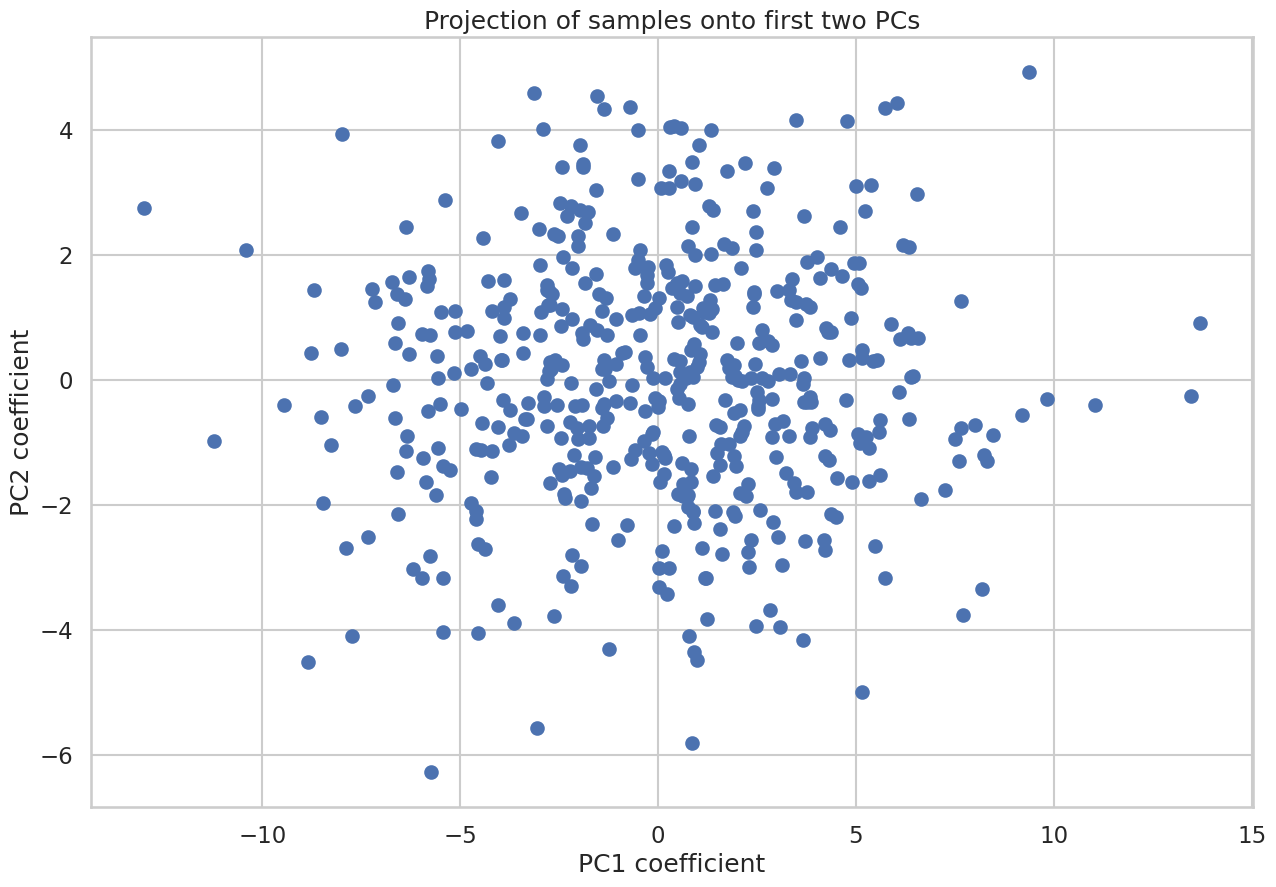

In [673]:
plt.scatter(coeff_phi[:,0], coeff_phi[:,1])
plt.xlabel("PC1 coefficient")
plt.ylabel("PC2 coefficient")
plt.title("Projection of samples onto first two PCs")
plt.savefig("./images/pca_projection_phi.png")
plt.show()

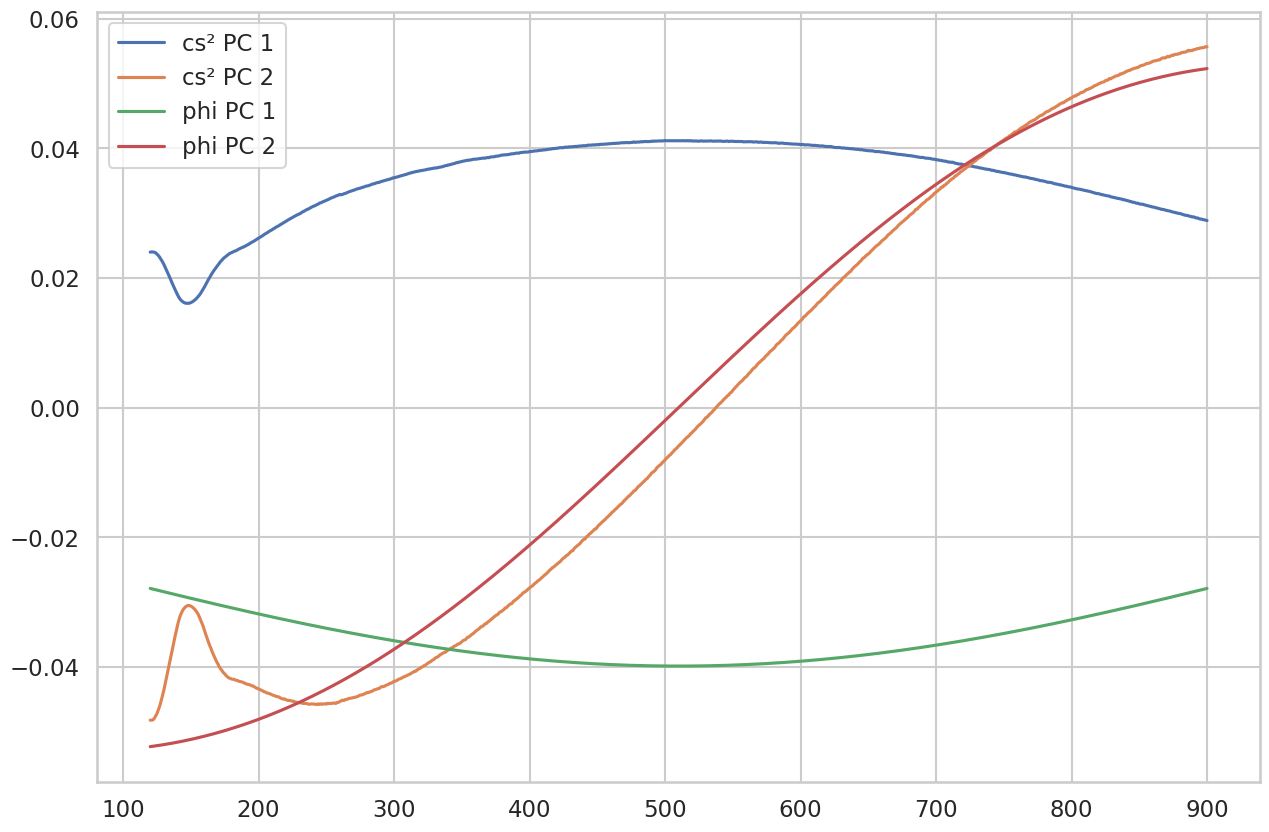

In [692]:
plt.plot(T_stepOne_total, PCs[0], label="cs² PC 1")
plt.plot(T_stepOne_total, PCs[1], label="cs² PC 2")
plt.plot(T_stepOne_total, eigenvecs_K[:,0], label="phi PC 1")
plt.plot(T_stepOne_total, eigenvecs_K[:,1], label="phi PC 2")
plt.legend()
plt.savefig("./images/pca_kernel_mode_comparison.png")
plt.show()

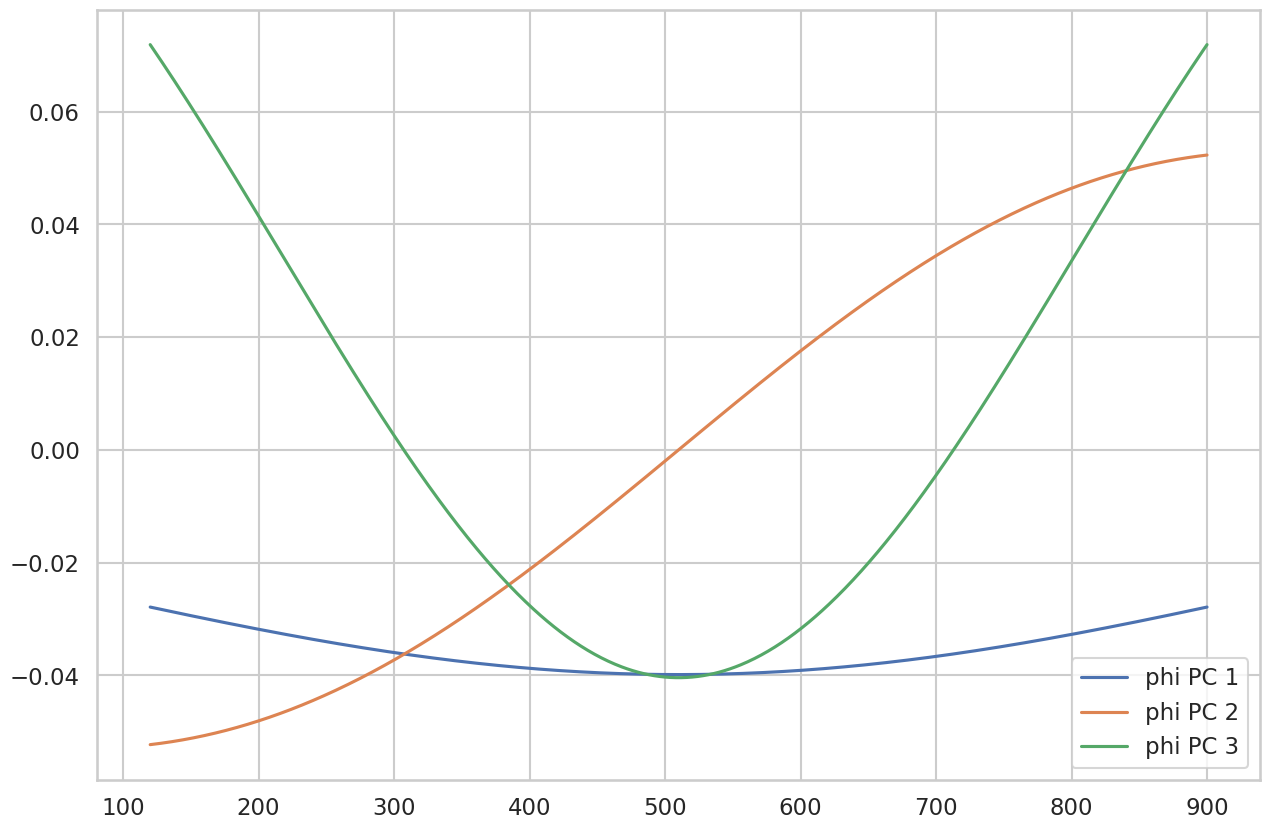

In [683]:

plt.plot(T_stepOne_total, eigenvecs_K[:,0], label="phi PC 1")
plt.plot(T_stepOne_total, eigenvecs_K[:,1], label="phi PC 2")
plt.plot(T_stepOne_total, eigenvecs_K[:,2], label="phi PC 3")  
plt.legend()
plt.savefig("./images/kernel_modes.png")
plt.show()

Max abs diff: 4.440892098500626e-16
All close: True


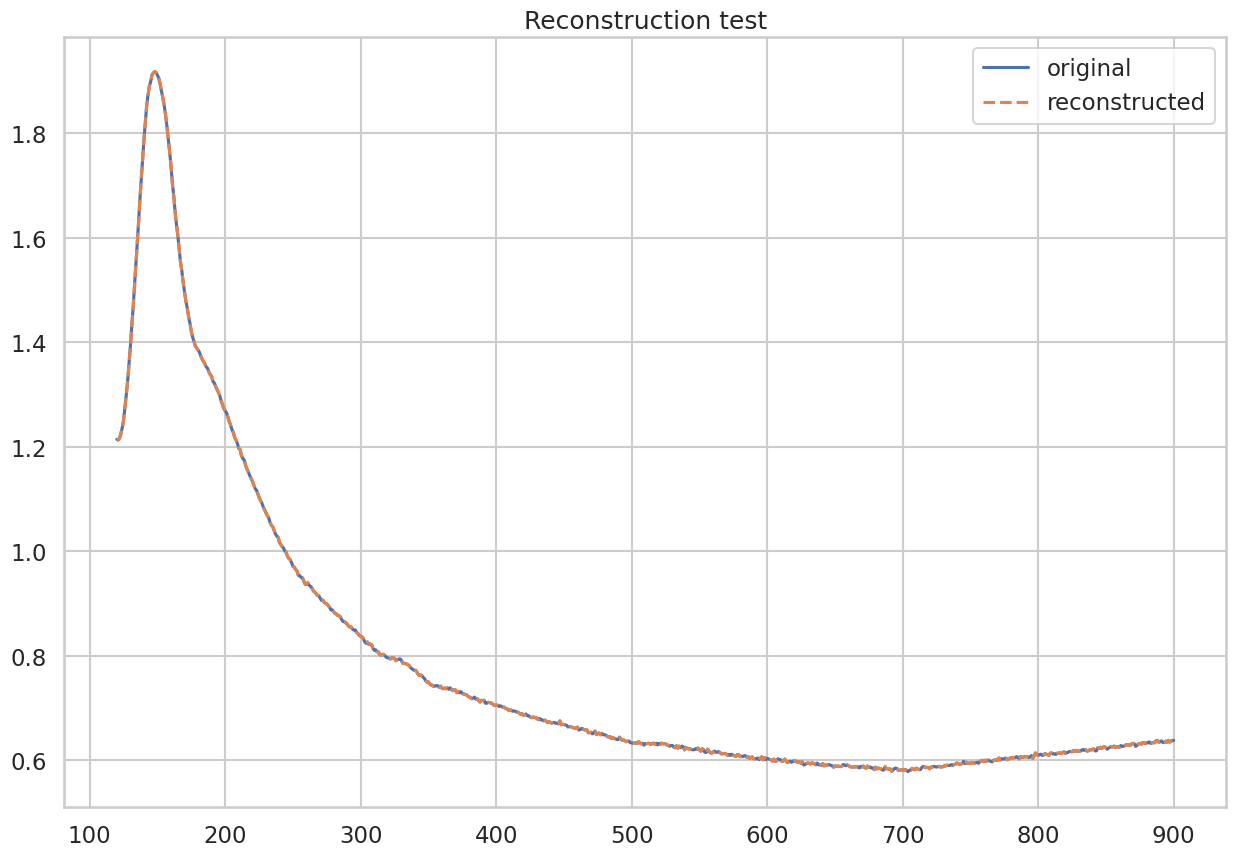

In [676]:
reconstructed = mean_phi + coeff_phi[0] @ eigenvecs_K.T

original = phi_samples[0]

print("Max abs diff:", np.max(np.abs(reconstructed - original)))
print("All close:", np.allclose(reconstructed, original))

plt.plot(T_stepOne_total, original, label="original")
plt.plot(T_stepOne_total, reconstructed, "--", label="reconstructed")

plt.legend()
plt.title("Reconstruction test")
plt.show()

In [677]:
var_fraction_K = eigenvals_K / np.sum(eigenvals_K)

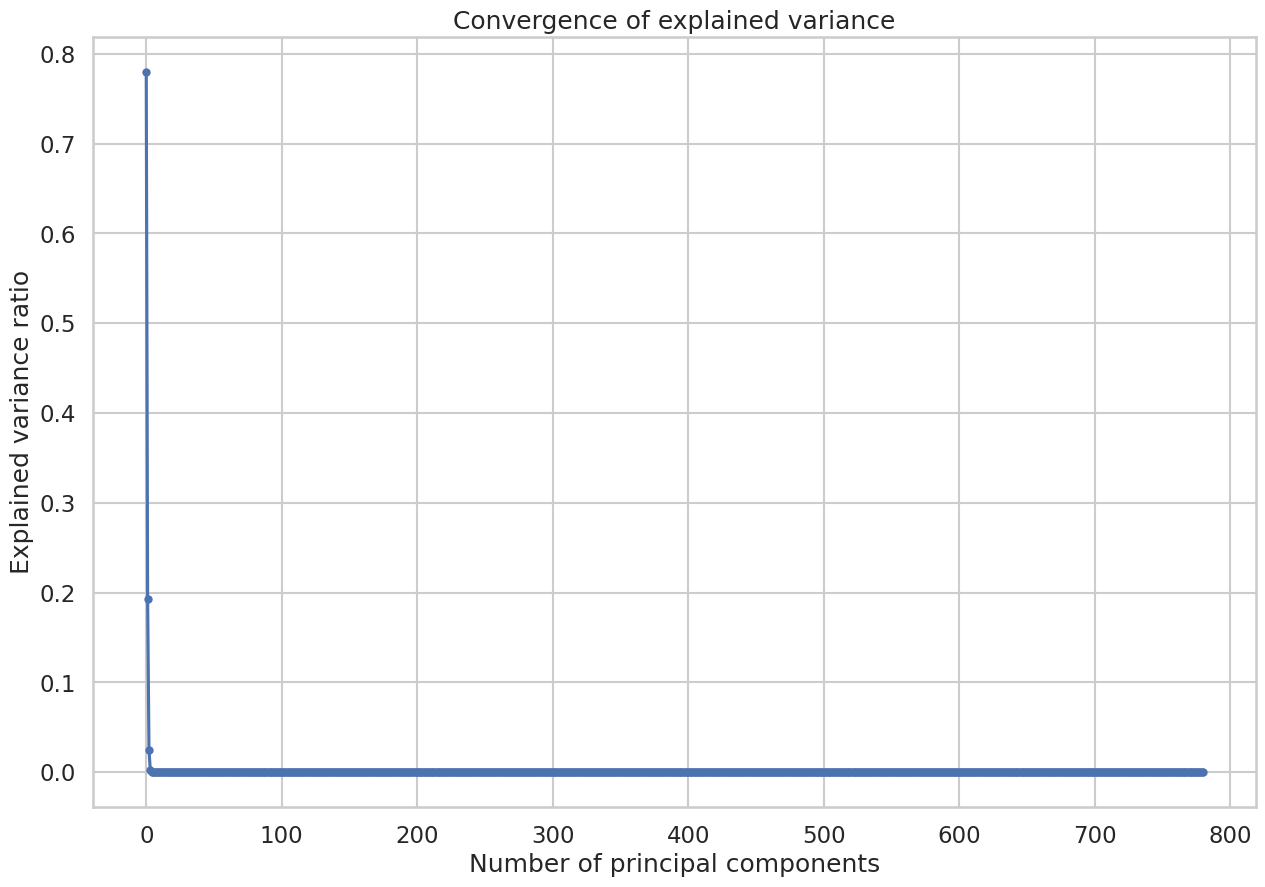

In [678]:
plt.plot(var_fraction_K, marker='o', markersize=5)
plt.xlabel("Number of principal components")
plt.ylabel("Explained variance ratio")
plt.title("Convergence of explained variance")
plt.savefig(f"./images/pca_explained_variance_phi_l{l_pca}_sigma{sigma_pca}.png")
plt.show()

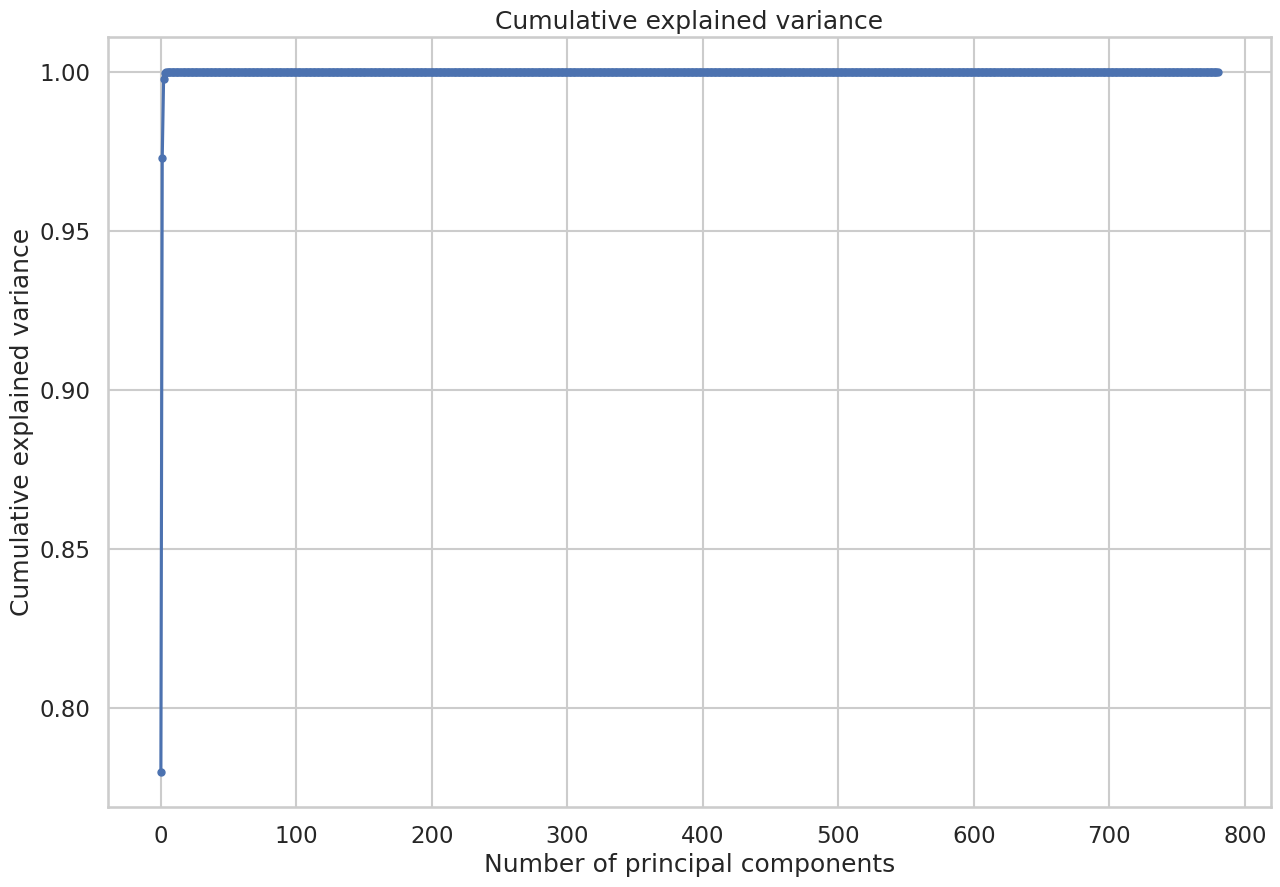

In [679]:
cum_var_frac = np.cumsum(var_fraction_K)
plt.plot(cum_var_frac, marker='o', markersize=5)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance")
plt.title("Cumulative explained variance")
plt.savefig(f"./images/pca_cumulative_variance_phi_l{l_pca}_sigma{sigma_pca}.png")
plt.show()